In [1]:
# Standard library imports
import os
from math import ceil, sqrt
from typing import Dict, Tuple, List, Optional
from pathlib import Path

# Third-party library imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
from matplotlib.ticker import ScalarFormatter
from matplotlib.gridspec import GridSpec
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

from sklearn.cross_decomposition import CCA
import itertools

import umap
from sklearn.manifold import TSNE

# Local library imports
from lp3d_analysis.plot import plot_colors, organize_data_structure, generate_paths_with_models_and_ensembles
from lp3d_analysis.maha_organize import process_mahalanobis
from aniposelib.cameras import CameraGroup


In [2]:
# dataset_name = 'fly-anipose'
# views = ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E', 'Cam-F']

# dataset_name = 'mirror-mouse-separate'
# views =['bot','top']

# dataset_name = 'chickadee-crop'
# views = ['lBack', 'lFront', 'lTop', 'rBack', 'rFront', 'rTop']

dataset_name = 'ibl-mouse'
views = ['rightCamera','leftCamera']
keypoints = ['pawL', 'pawR', 'nose']

seed_dirs = ['0','1','2'] # only second seed 
ensemble_seed = '0-2'
ensemble_methods = []
video_dir = ['videos_new', 'videos_new_add', 'videos_new_segmentation']
n_hand_labels = '200'
model_type = 'mvt_3d_loss'

dataset_name == 'ibl-mouse'
ensemble_methods = ['ensemble_median', 'eks_multiview_varinf']

results_dirs = [
    'test_200_MVT_3d_aug_patch_masking_new_labels', 
    'test_200_multiview_resnet50_new_labels',
]
results_configs = {
    
    'test_200_multiview_resnet50_new_labels': {
        'model_type': 'supervised',  # or whatever the correct model_type is
        'n_hand_labels': '200'
    },

    'test_200_MVT_3d_aug_patch_masking_new_labels': {
        'model_type': 'multiview_transformer', 
        'n_hand_labels': '200'
    },


    
}

# The 4 models we want to compare
models_of_interest = [
    'test_200_multiview_resnet50_new_labels_ensemble_median',
    # 'test_200_multiview_resnet50_new_labels_ensemble_median_anipose',
    # 'test_200_MVT_3d_aug_patch_masking_new_labels_ensemble_median',
    'test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf',
]

# Short names for plotting
model_short_names = {
    'test_200_multiview_resnet50_new_labels_ensemble_median': 'ResNet50',
    'test_200_multiview_resnet50_new_labels_ensemble_median_anipose': 'ResNet50+Anipose',
    'test_200_MVT_3d_aug_patch_masking_new_labels_ensemble_median': 'MVT++',
    'test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf': 'MVT+++EKS',
}


camera_params_dir = f'/teamspace/studios/data/{dataset_name}/calibrations'

session_name = '_iblrig_.downsampled.9b528ad0-4599-4a55-9148-96cc1d93fb24'
original_session_name = session_name 

from lp3d_analysis.utils import generate_comprehensive_paths_multi_results

In_Dist_paths, Out_Dist_paths, all_file_paths = generate_comprehensive_paths_multi_results(
    dataset_name, views, results_configs, video_dir, 
    seed_dirs, ensemble_seed=ensemble_seed, ensemble_methods=ensemble_methods,
    include_seeds=False, include_ensembles=True
)


=== Processing results directory: test_200_multiview_resnet50_new_labels ===
    Model type: supervised, Labels: 200
  Checking ensemble dir: /teamspace/studios/this_studio/outputs/ibl-mouse/test_200_multiview_resnet50_new_labels/supervised_200_0-2/ensemble_median/videos_new
    EXISTS: Added test_200_multiview_resnet50_new_labels_ensemble_median
  Checking ensemble dir: /teamspace/studios/this_studio/outputs/ibl-mouse/test_200_multiview_resnet50_new_labels/supervised_200_0-2/ensemble_median/videos_new_add
    EXISTS: Added test_200_multiview_resnet50_new_labels_ensemble_median
  Checking ensemble dir: /teamspace/studios/this_studio/outputs/ibl-mouse/test_200_multiview_resnet50_new_labels/supervised_200_0-2/ensemble_median/videos_new_segmentation
    EXISTS: Added test_200_multiview_resnet50_new_labels_ensemble_median
  Checking ensemble dir: /teamspace/studios/this_studio/outputs/ibl-mouse/test_200_multiview_resnet50_new_labels/supervised_200_0-2/eks_multiview_varinf/videos_new
    N

In [3]:
# Pick the session to analyze
# target_session = '_iblrig.downsampled.9b528ad0-4599-4a55-9148-96cc1d93fb24' # this one we have decent results 

# target_session = '_iblrig.downsampled.15763234-d21e-491f-a01b-1238eb96d389'


# target_session = '_iblrig.downsampled.4b00df29-3769-43be-bb40-128b1cba6d35'
# target_session = '_iblrig.downsampled.aad23144-0e52-4eac-80c5-c4ee2decb198'
# '_iblrig.downsampled.aad23144-0e52-4eac-80c5-c4ee2decb198',  # not good removed also the one that starts with 008

# target_sessions = ['_iblrig.downsampled.9b528ad0-4599-4a55-9148-96cc1d93fb24', #1
#                     '_iblrig.downsampled.15763234-d21e-491f-a01b-1238eb96d389', #2
#                     '_iblrig.downsampled.4b00df29-3769-43be-bb40-128b1cba6d35', #3
#                     '_iblrig.downsampled.15b69921-d471-4ded-8814-2adad954bcd8', #4
#                     '_iblrig.downsampled.f312aaec-3b6f-44b3-86b4-3a0c119c0438', #5
#                     '_iblrig.downsampled.1b715600-0cbc-442c-bd00-5b0ac2865de1', #6
#                     '_iblrig.downsampled.3bcb81b4-d9ca-4fc9-a1cd-353a966239ca', #7
#                     '_iblrig.downsampled.7cb81727-2097-4b52-b480-c89867b5b34c', #8
#                     '_iblrig.downsampled.8928f98a-b411-497e-aa4b-aa752434686d', #9
#                     '_iblrig.downsampled.0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde', #10
#                     # tried to add new oens 
#                     '_iblrig.downsampled.03d9a098-07bf-4765-88b7-85f8d8f620cc', #11
#                     '_iblrig.downsampled.3e6a97d3-3991-49e2-b346-6948cb4580fb', #12
#                     '_iblrig.downsampled.3f859b5c-e73a-4044-b49e-34bb81e96715', #13
#                     '_iblrig.downsampled.4b7fbad4-f6de-43b4-9b15-c7c7ef44db4b', #14
#                     '_iblrig.downsampled.5ae68c54-2897-4d3a-8120-426150704385', #15
#                     '_iblrig.downsampled.5dcee0eb-b34d-4652-acc3-d10afc6eae68', #16
#                     '_iblrig.downsampled.8a3a0197-b40a-449f-be55-c00b23253bbf', #17
#                     '_iblrig.downsampled.30c4e2ab-dffc-499d-aae4-e51d6b3218c2', #18
#                     '_iblrig.downsampled.51e53aff-1d5d-4182-a684-aba783d50ae5', #19

#                     # ones that I know are bad 
#                     # '_iblrig.downsampled.aad23144-0e52-4eac-80c5-c4ee2decb198', # this one is bad! remove maybe from decoding too.
#                     '_iblrig.downsampled.0841d188-8ef2-4f20-9828-76a94d5343a4',
                    
                    
# ]

target_sessions = [ "_iblrig.downsampled.15b69921-d471-4ded-8814-2adad954bcd8",    
                    "_iblrig.downsampled.15763234-d21e-491f-a01b-1238eb96d389", 
                    # "_iblrig.downsampled.aad23144-0e52-4eac-80c5-c4ee2decb198",
                    "_iblrig.downsampled.9b528ad0-4599-4a55-9148-96cc1d93fb24",
                    "_iblrig.downsampled.4b00df29-3769-43be-bb40-128b1cba6d35",
                    "_iblrig.downsampled.0841d188-8ef2-4f20-9828-76a94d5343a4", # resnet is doing better than MVT - we can still have it if we decide 23 sessions for decoding 
                    "_iblrig.downsampled.f312aaec-3b6f-44b3-86b4-3a0c119c0438",
                    "_iblrig.downsampled.0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde",
                    "_iblrig.downsampled.1b715600-0cbc-442c-bd00-5b0ac2865de1",
                    
                    # "_iblrig.downsampled.3bcb81b4-d9ca-4fc9-a1cd-353a966239ca", # not looking good. consider removing
                    # "_iblrig.downsampled.03d9a098-07bf-4765-88b7-85f8d8f620cc", # very bad with EKS 
                    "_iblrig.downsampled.3e6a97d3-3991-49e2-b346-6948cb4580fb",
                    "_iblrig.downsampled.3f859b5c-e73a-4044-b49e-34bb81e96715", # bad with EKS 
                    "_iblrig.downsampled.4b7fbad4-f6de-43b4-9b15-c7c7ef44db4b",
                    "_iblrig.downsampled.5ae68c54-2897-4d3a-8120-426150704385",
                    "_iblrig.downsampled.5dcee0eb-b34d-4652-acc3-d10afc6eae68",
                    # "_iblrig.downsampled.6c6b0d06-6039-4525-a74b-58cfaa1d3a60", # I used to comment out - in general can remove but will decide later 
                    "_iblrig.downsampled.7cb81727-2097-4b52-b480-c89867b5b34c",
                    "_iblrig.downsampled.8a3a0197-b40a-449f-be55-c00b23253bbf",
                    "_iblrig.downsampled.30c4e2ab-dffc-499d-aae4-e51d6b3218c2",
                    "_iblrig.downsampled.51e53aff-1d5d-4182-a684-aba783d50ae5",
                    # "_iblrig.downsampled.61e11a11-ab65-48fb-ae08-3cb80662e5d6", # bad with EKS 
                    "_iblrig.downsampled.746d1902-fa59-4cab-b0aa-013be36060d5",
                    "_iblrig.downsampled.824cf03d-4012-4ab1-b499-c83a92c5589e",

                    "_iblrig.downsampled.3638d102-e8b6-4230-8742-e548cd87a949",
                    "_iblrig.downsampled.6899a67d-2e53-4215-a52a-c7021b5da5d4",
                    "_iblrig.downsampled.8928f98a-b411-497e-aa4b-aa752434686d",

                    "_iblrig.downsampled.46794e05-3f6a-4d35-afb3-9165091a5a74", 
                    "_iblrig.downsampled.493170a6-fd94-4ee4-884f-cc018c17eeb9", 
                    "_iblrig.downsampled.54238fd6-d2d0-4408-b1a9-d19d24fd29ce", 
                    "_iblrig.downsampled.73918ae1-e4fd-4c18-b132-00cb555b1ad2", # not great for MVT
                    "_iblrig.downsampled.b03fbc44-3d8e-4a6c-8a50-5ea3498568e0", 
                    # # "_iblrig.downsampled.b196a2ad-511b-4e90-ac99-b5a29ad25c22", # not great camera parameters 
                    "_iblrig.downsampled.b22f694e-4a34-4142-ab9d-2556c3487086", 
                    "_iblrig.downsampled.c7248e09-8c0d-40f2-9eb4-700a8973d8c8", 
                    "_iblrig.downsampled.c7bf2d49-4937-4597-b307-9f39cb1c7b16", 
                    "_iblrig.downsampled.ca4ecb4c-4b60-4723-9b9e-2c54a6290a53", 
                    "_iblrig.downsampled.d0ea3148-948d-4817-94f8-dcaf2342bbbe", 
                    "_iblrig.downsampled.d23a44ef-1402-4ed7-97f5-47e9a7a504d9", 
                    # # "_iblrig.downsampled.db4df448-e449-4a6f-a0e7-288711e7a75a", # this is a bad session with variance or something like this 
                    "_iblrig.downsampled.dc962048-89bb-4e6a-96a9-b062a2be1426", 
                    "_iblrig.downsampled.e535fb62-e245-4a48-b119-88ce62a6fe67", 
                    "_iblrig.downsampled.f115196e-8dfe-4d2a-8af3-8206d93c1729", 
                    "_iblrig.downsampled.f140a2ec-fd49-4814-994a-fe3476f14e66", 
                    "_iblrig.downsampled.f3ce3197-d534-4618-bf81-b687555d1883", 
                    "_iblrig.downsampled.ff96bfe1-d925-4553-94b5-bf8297adf259",

                    
]

Using vectorized triangulation (lightning-pose triangulate_fast)
Processing only 39 sessions of interest: ['_iblrig.downsampled.0841d188-8ef2-4f20-9828-76a94d5343a4', '_iblrig.downsampled.15763234-d21e-491f-a01b-1238eb96d389', '_iblrig.downsampled.15b69921-d471-4ded-8814-2adad954bcd8', '_iblrig.downsampled.4b00df29-3769-43be-bb40-128b1cba6d35', '_iblrig.downsampled.9b528ad0-4599-4a55-9148-96cc1d93fb24', '_iblrig.downsampled.f312aaec-3b6f-44b3-86b4-3a0c119c0438', '_iblrig.downsampled.0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde', '_iblrig.downsampled.1b715600-0cbc-442c-bd00-5b0ac2865de1', '_iblrig.downsampled.30c4e2ab-dffc-499d-aae4-e51d6b3218c2', '_iblrig.downsampled.3638d102-e8b6-4230-8742-e548cd87a949', '_iblrig.downsampled.3e6a97d3-3991-49e2-b346-6948cb4580fb', '_iblrig.downsampled.3f859b5c-e73a-4044-b49e-34bb81e96715', '_iblrig.downsampled.4b7fbad4-f6de-43b4-9b15-c7c7ef44db4b', '_iblrig.downsampled.51e53aff-1d5d-4182-a684-aba783d50ae5', '_iblrig.downsampled.5ae68c54-2897-4d3a-8120-42615070

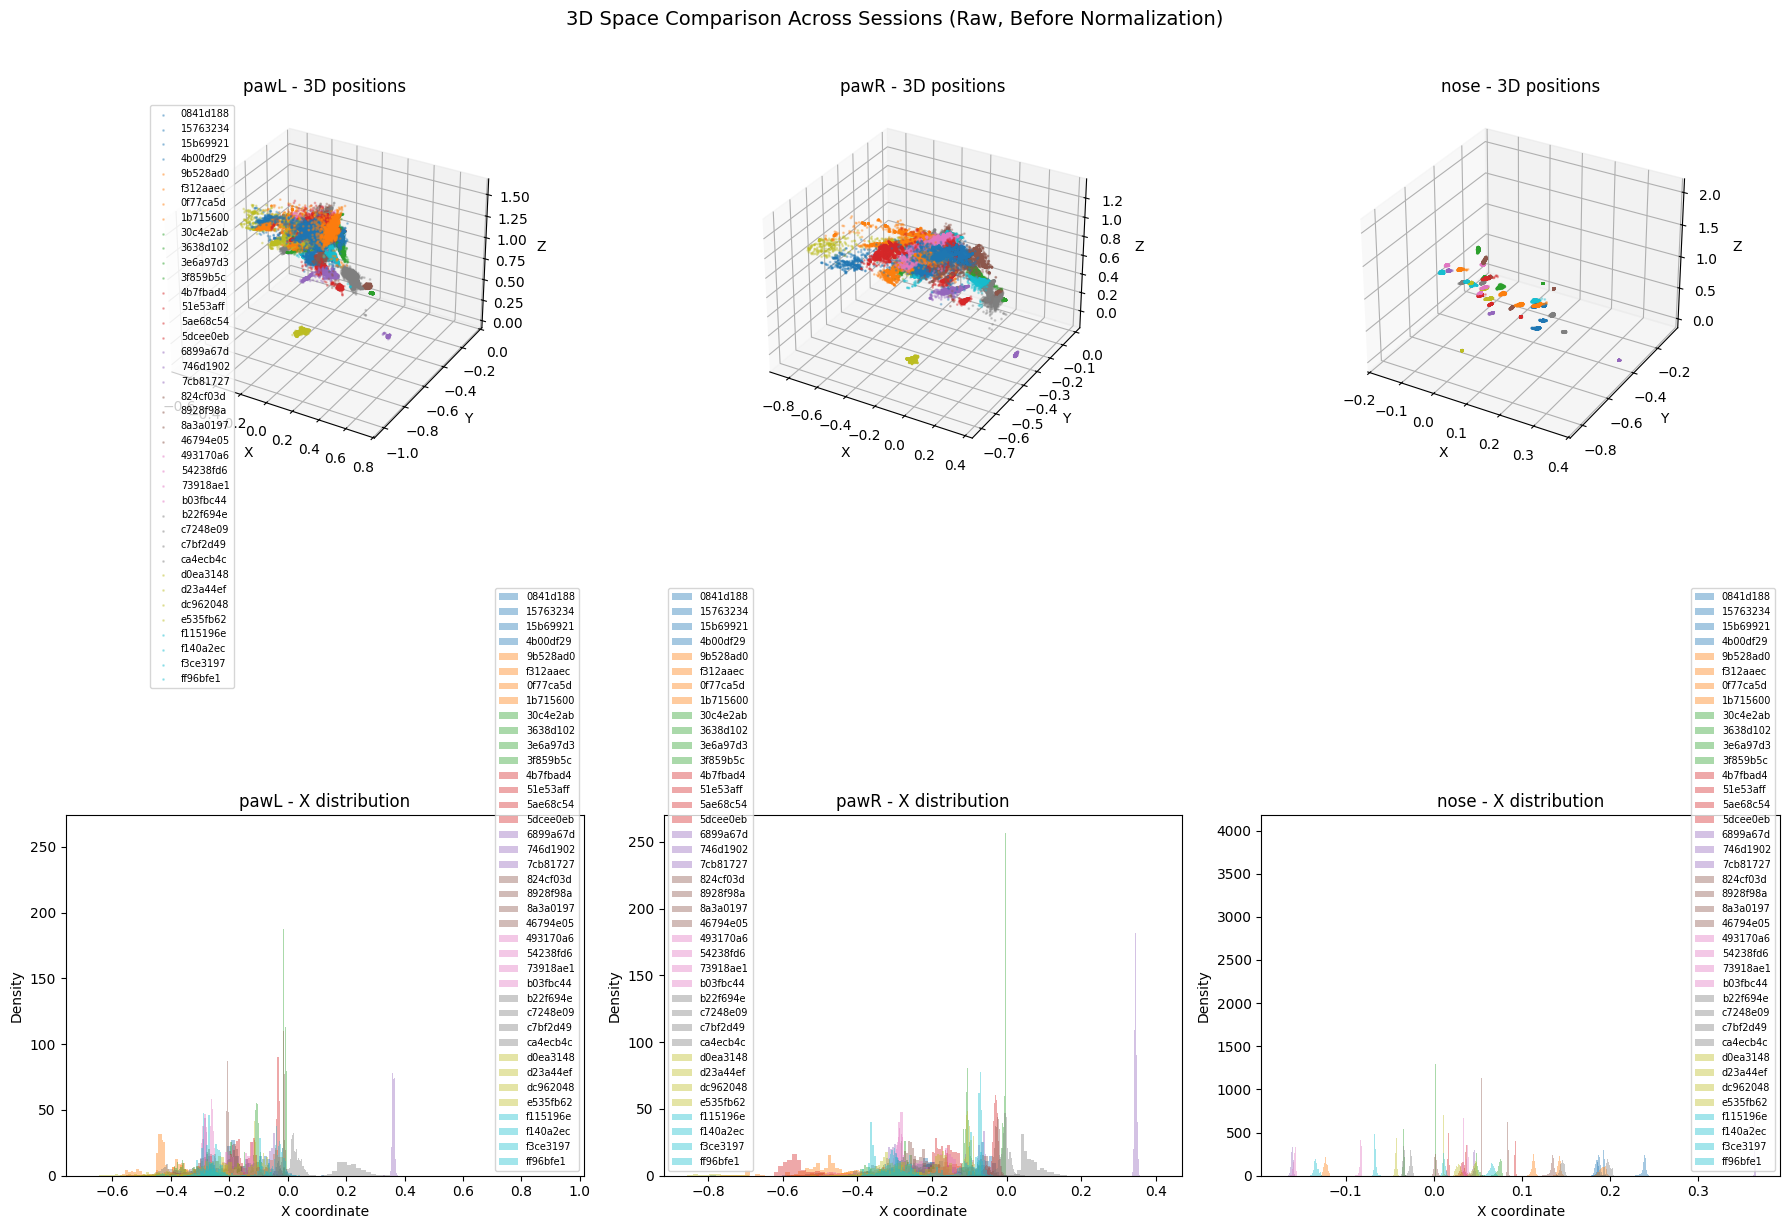

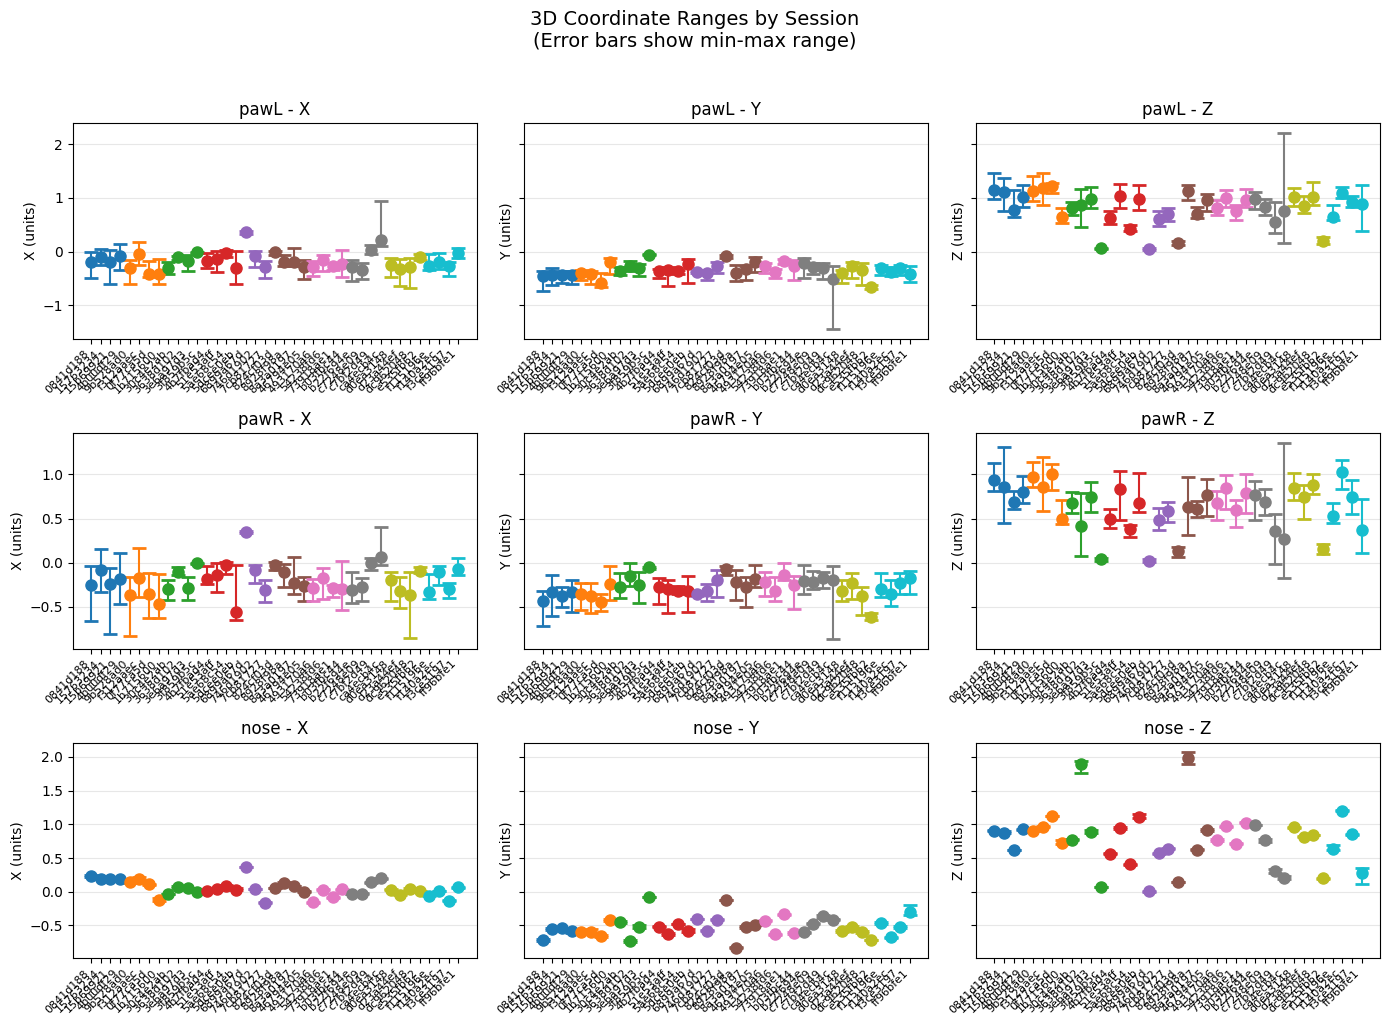

/teamspace/studios/this_studio/lp3d-analysis/lp3d_analysis/clustering/check_3d_coord.py:300: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


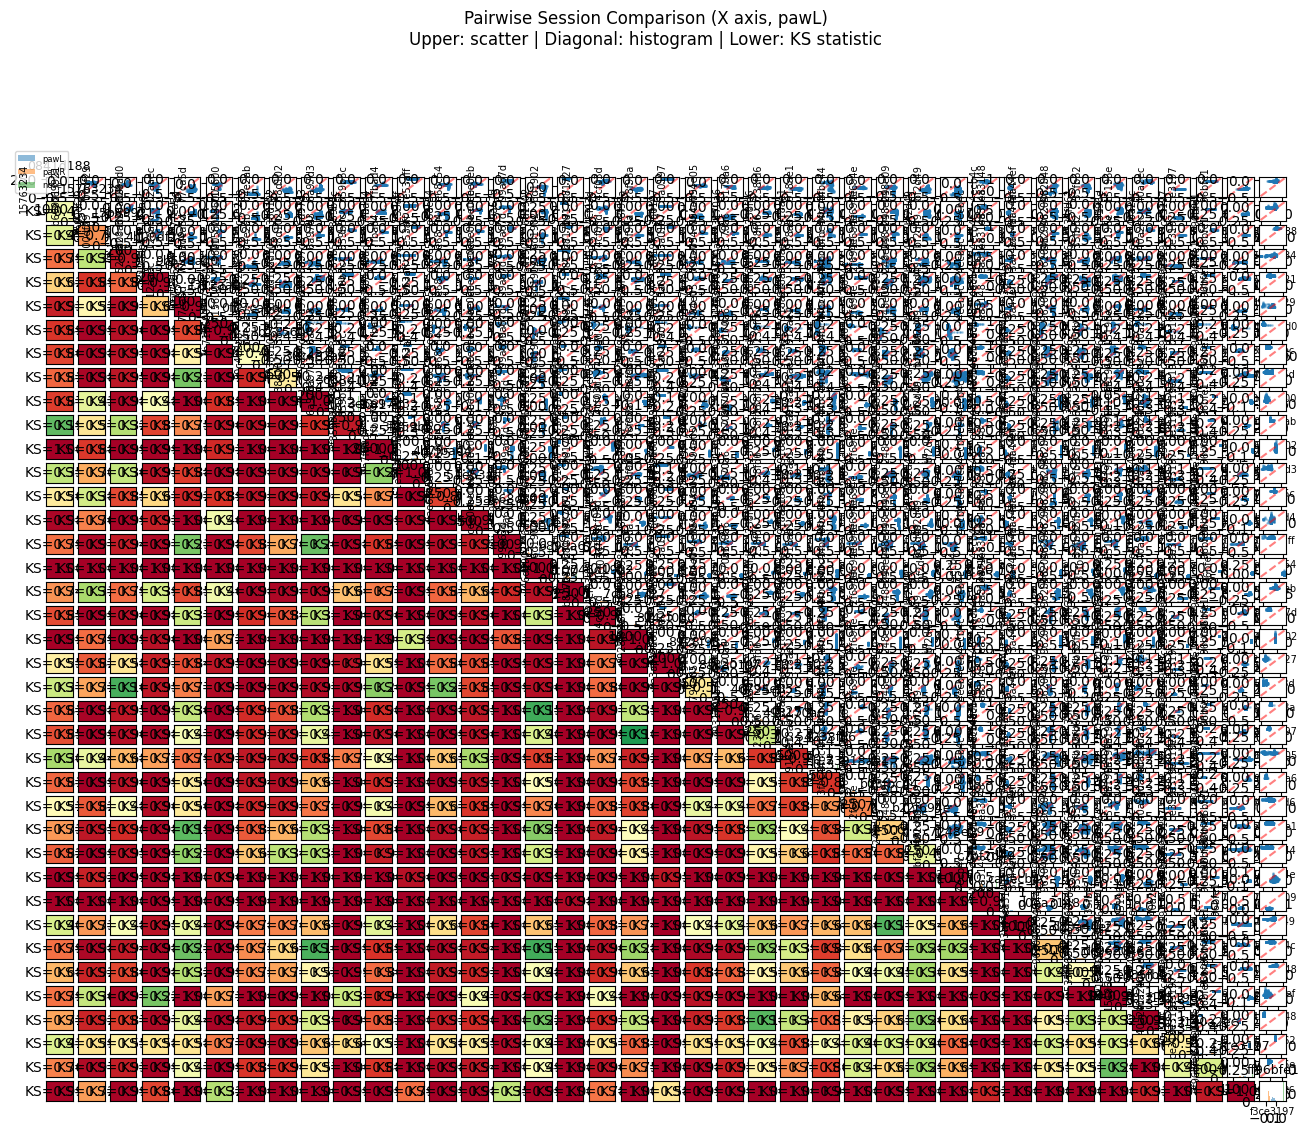

In [4]:
# importlib.reload(lp3d_analysis.clustering.utils)
from lp3d_analysis.clustering.utils import load_and_triangulate_all_sessions
from lp3d_analysis.clustering.check_3d_coord import check_3d_space_consistency




max_frames_per_session = 20000

# load raw data and triangulate 
all_3d_data_raw, all_2d_data, session_frame_counts = load_and_triangulate_all_sessions(
    all_file_paths, models_of_interest, views, keypoints, camera_params_dir,
    normalize=False,  # Keep raw coordinates
    max_frames_per_session=max_frames_per_session,
    sessions_of_interest=target_sessions,
    use_vectorized=True
)

# check 3d space consistency 
df_stats, df_diff = check_3d_space_consistency(
    all_3d_data_raw, 
    model_name=models_of_interest[1],  # Use one model for this check
    keypoints=keypoints
)



In [5]:
keypoints

['pawL', 'pawR', 'nose']

Using vectorized triangulation (lightning-pose triangulate_fast)
Processing only 39 sessions of interest: ['_iblrig.downsampled.0841d188-8ef2-4f20-9828-76a94d5343a4', '_iblrig.downsampled.15763234-d21e-491f-a01b-1238eb96d389', '_iblrig.downsampled.15b69921-d471-4ded-8814-2adad954bcd8', '_iblrig.downsampled.4b00df29-3769-43be-bb40-128b1cba6d35', '_iblrig.downsampled.9b528ad0-4599-4a55-9148-96cc1d93fb24', '_iblrig.downsampled.f312aaec-3b6f-44b3-86b4-3a0c119c0438', '_iblrig.downsampled.0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde', '_iblrig.downsampled.1b715600-0cbc-442c-bd00-5b0ac2865de1', '_iblrig.downsampled.30c4e2ab-dffc-499d-aae4-e51d6b3218c2', '_iblrig.downsampled.3638d102-e8b6-4230-8742-e548cd87a949', '_iblrig.downsampled.3e6a97d3-3991-49e2-b346-6948cb4580fb', '_iblrig.downsampled.3f859b5c-e73a-4044-b49e-34bb81e96715', '_iblrig.downsampled.4b7fbad4-f6de-43b4-9b15-c7c7ef44db4b', '_iblrig.downsampled.51e53aff-1d5d-4182-a684-aba783d50ae5', '_iblrig.downsampled.5ae68c54-2897-4d3a-8120-42615070

  test_200_multiview_resnet50_new_labels_ensemble_median: 60000/60000 valid 3D points
  test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf: 60000/60000 valid 3D points

=== Processing session: _iblrig.downsampled.15763234-d21e-491f-a01b-1238eb96d389 ===
  test_200_multiview_resnet50_new_labels_ensemble_median: 60000/60000 valid 3D points
  test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf: 60000/60000 valid 3D points

=== Processing session: _iblrig.downsampled.15b69921-d471-4ded-8814-2adad954bcd8 ===
  test_200_multiview_resnet50_new_labels_ensemble_median: 60000/60000 valid 3D points
  test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf: 60000/60000 valid 3D points

=== Processing session: _iblrig.downsampled.4b00df29-3769-43be-bb40-128b1cba6d35 ===
  test_200_multiview_resnet50_new_labels_ensemble_median: 60000/60000 valid 3D points
  test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf: 60000/60000 valid 3D points

=== Proce

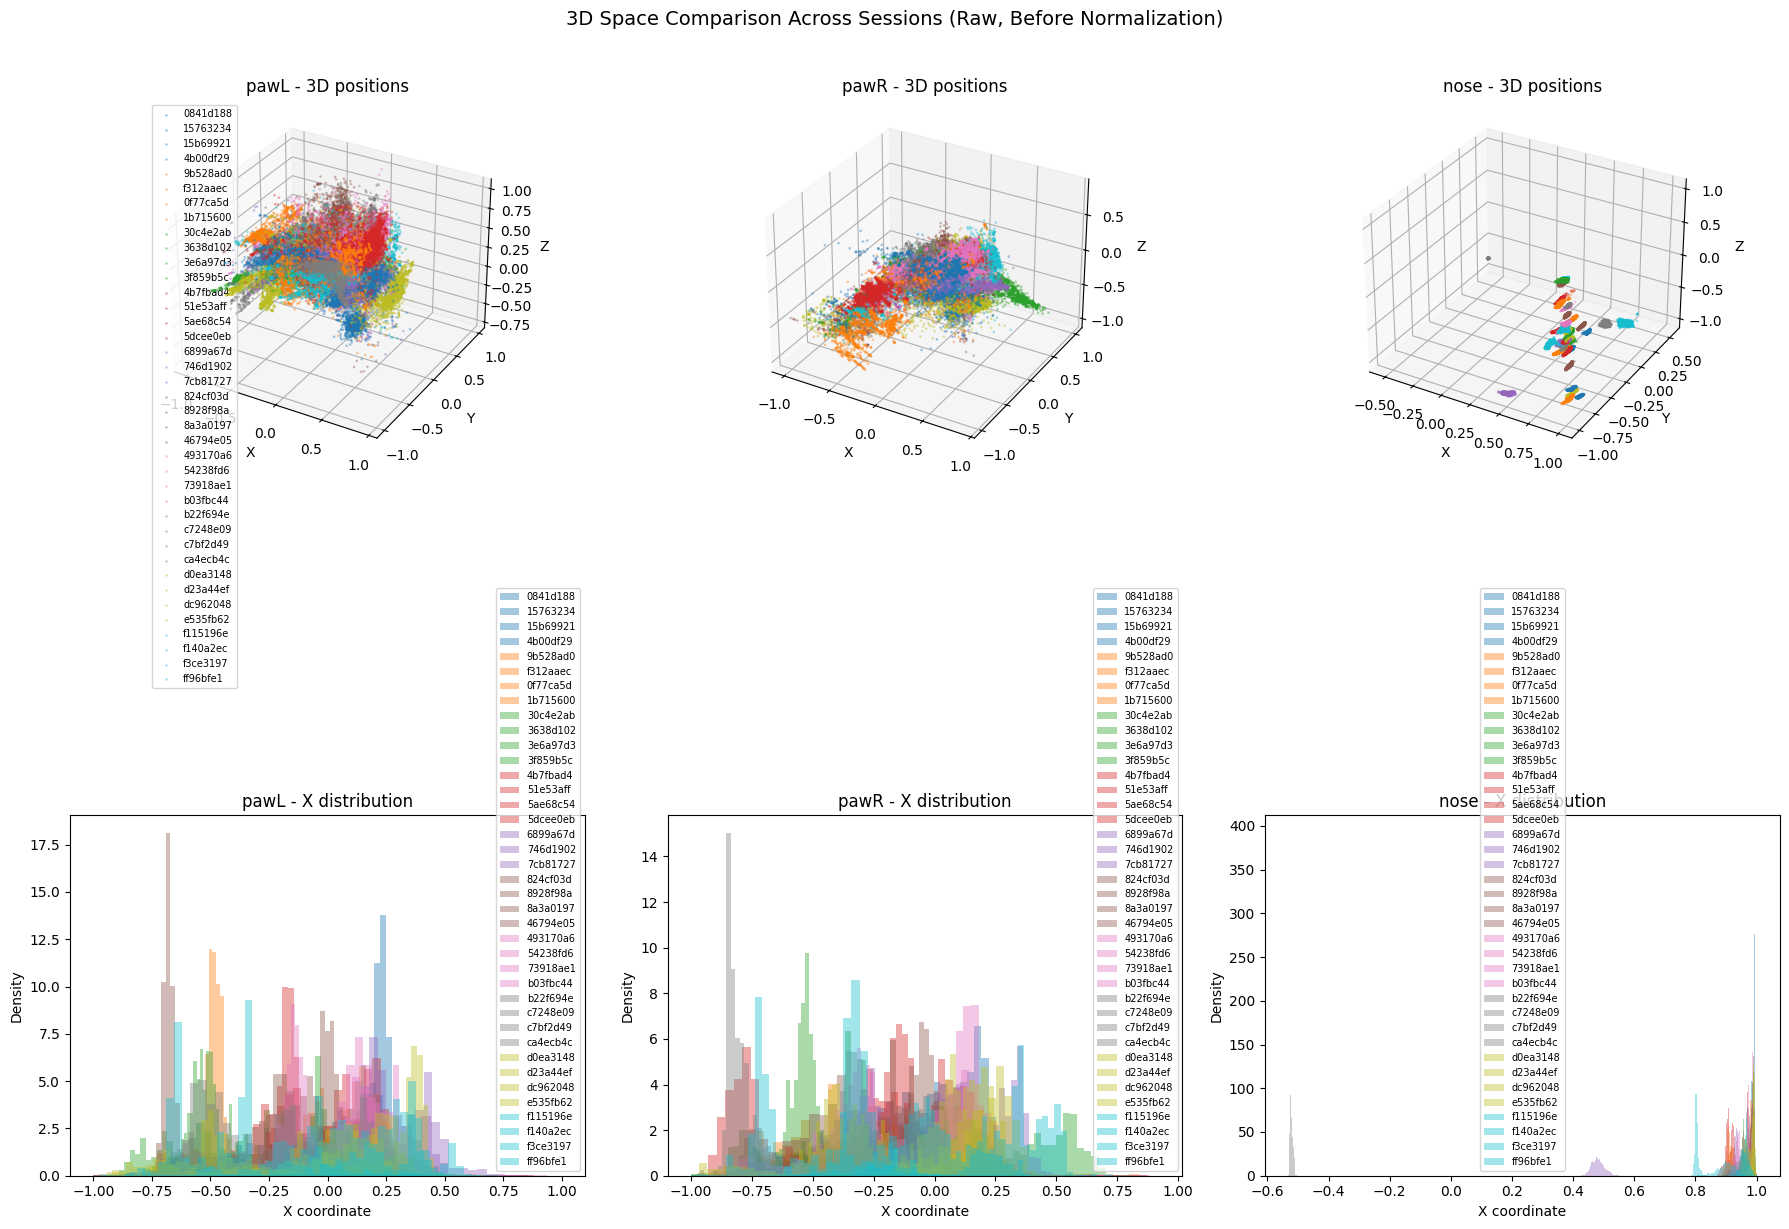

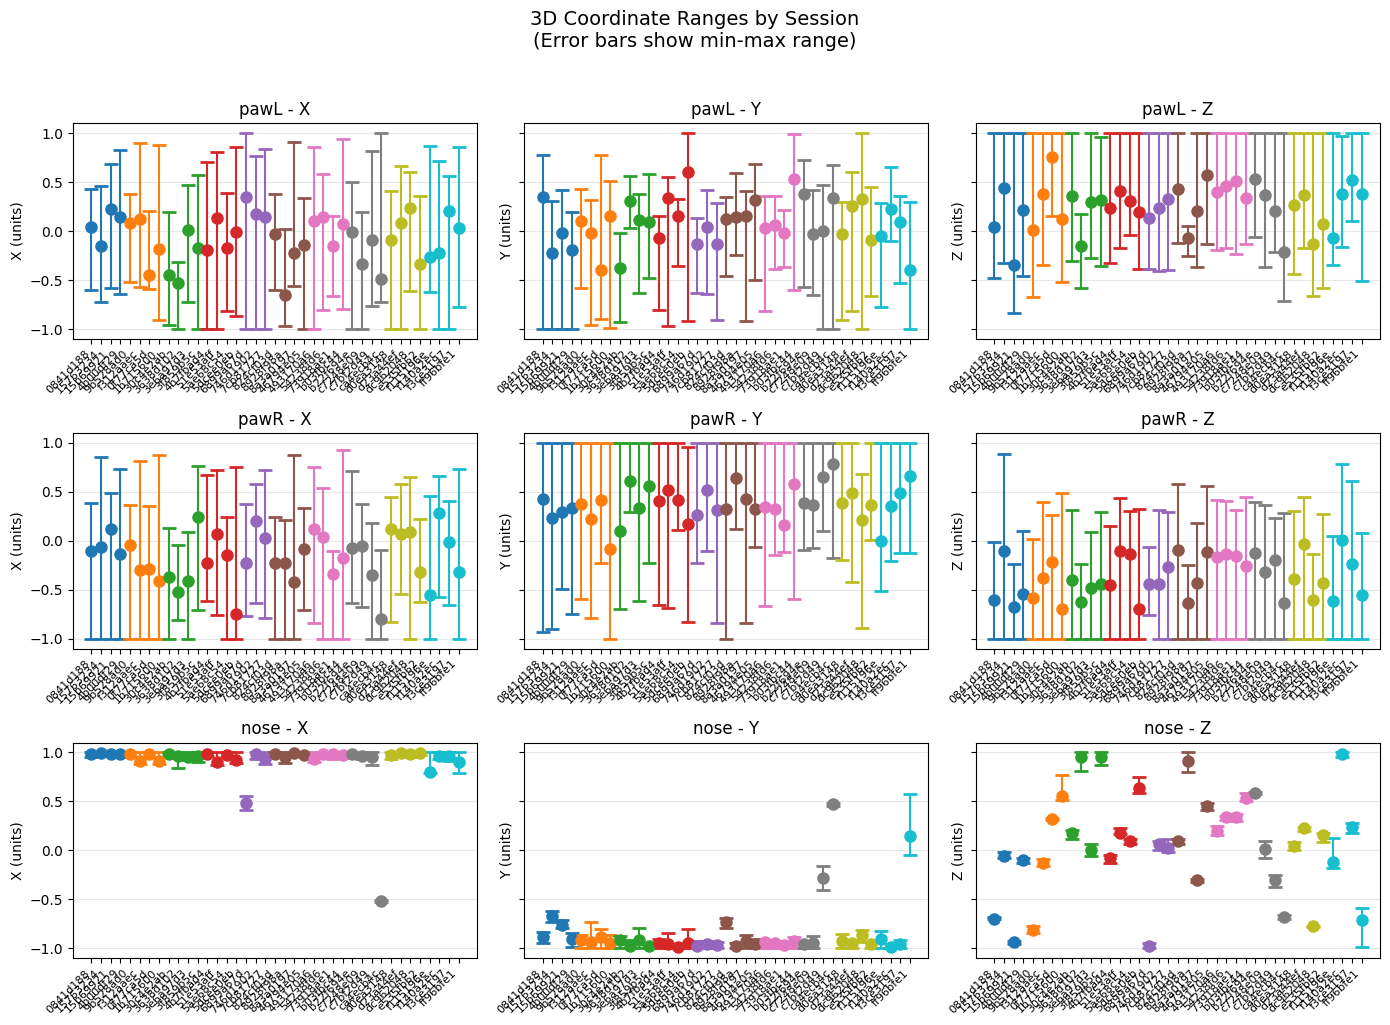

/teamspace/studios/this_studio/lp3d-analysis/lp3d_analysis/clustering/check_3d_coord.py:300: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


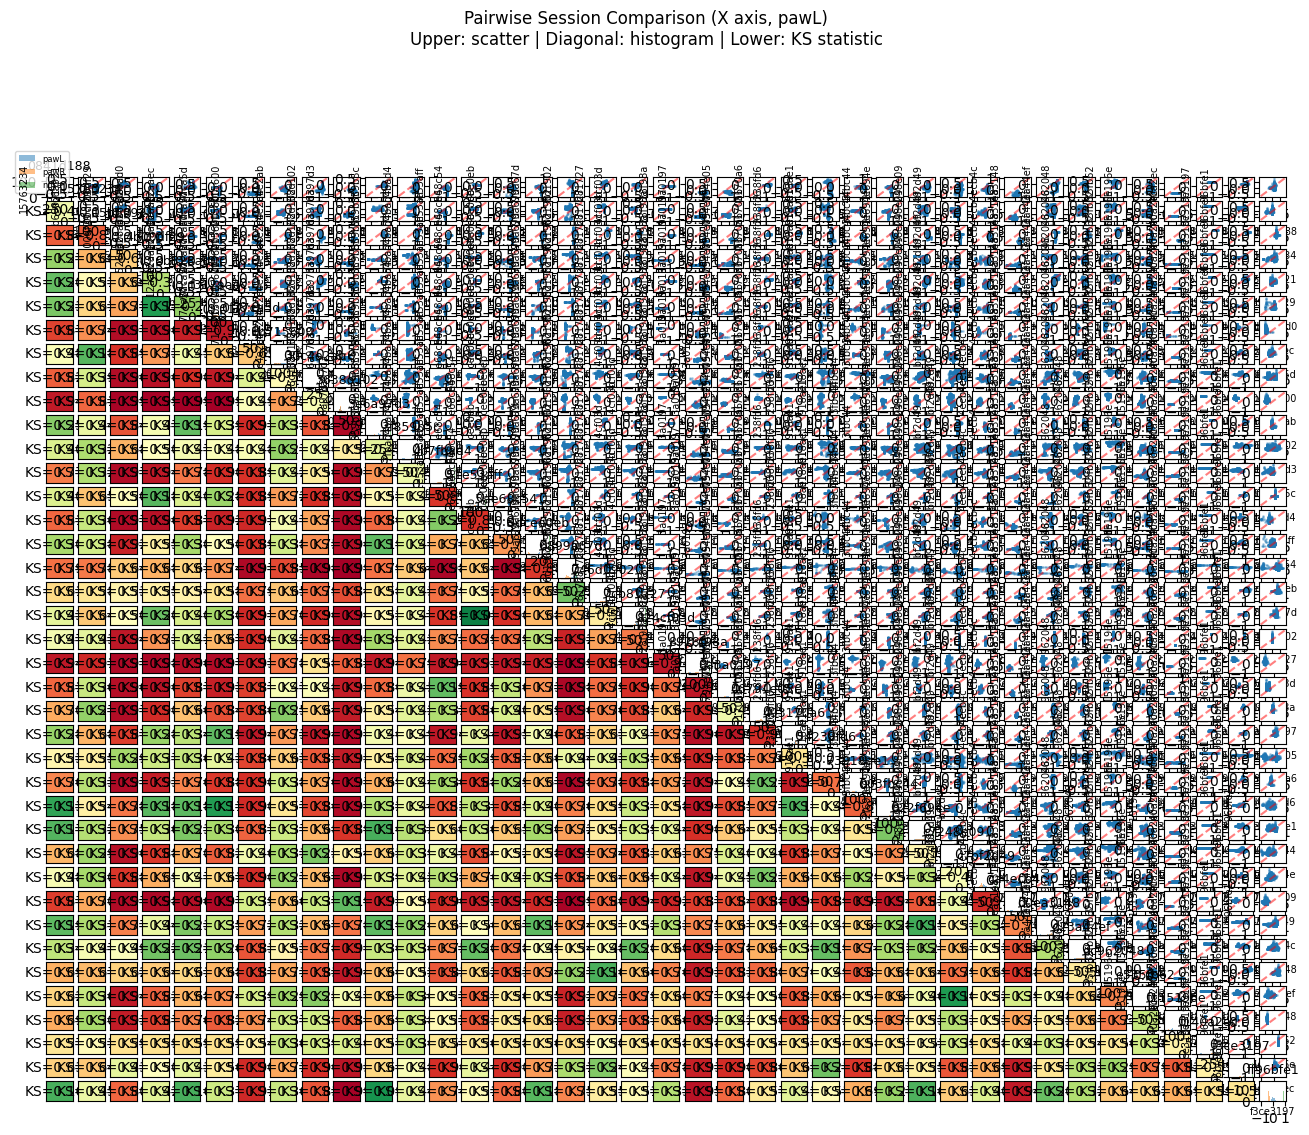

In [6]:
# Load data (with normalization for clustering)
all_3d_data_norm, all_2d_data, session_frame_counts = load_and_triangulate_all_sessions(
    all_file_paths, models_of_interest, views, keypoints, camera_params_dir,
    normalize=True, max_frames_per_session=max_frames_per_session, sessions_of_interest = target_sessions,
    use_vectorized=True
)
df_stats, df_diff = check_3d_space_consistency(
    all_3d_data_norm, 
    model_name=models_of_interest[1],  # Use one model for this check
    keypoints=keypoints
)



In [7]:
from lp3d_analysis.clustering.features import extract_features_all_sessions
all_features, session_labels_dict, feature_names = extract_features_all_sessions(
        all_3d_data_norm, keypoints
)

In [8]:
from lp3d_analysis.clustering.utils import pool_features_all_models_all_sessions
pooled_features, valid_mask, session_labels, model_labels, model_frame_counts = \
    pool_features_all_models_all_sessions(
        all_features, models_of_interest,
        max_frames_per_session=max_frames_per_session,
        subsample_factor=1
)

test_200_multiview_resnet50_new_labels_ensemble_median: 780000 frames
test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf: 780000 frames

Total pooled: 1560000 frames x 11 features
Valid (non-NaN): 1560000 frames


In [9]:

features_clean = pooled_features[valid_mask]
session_labels_clean = [s for s, v in zip(session_labels, valid_mask) if v]
model_labels_clean = [m for m, v in zip(model_labels, valid_mask) if v]

print(f"\nClean features shape: {features_clean.shape}")
print(f"Sessions: {len(set(session_labels_clean))}")
print(f"Models: {len(set(model_labels_clean))}")

# # This is what we had so far
# # Standardize
# scaler = StandardScaler()
# features_scaled = scaler.fit_transform(features_clean)

from sklearn.preprocessing import RobustScaler

# Replace StandardScaler with RobustScaler
scaler = RobustScaler()
features_scaled = scaler.fit_transform(features_clean)


Clean features shape: (1560000, 11)
Sessions: 39
Models: 2


In [10]:

# Reload the hierarchical clustering module

import lp3d_analysis.clustering.hierarchical_clustering
importlib.reload(lp3d_analysis.clustering.hierarchical_clustering)
from lp3d_analysis.clustering.hierarchical_clustering import run_hierarchical_clustering

print("\n" + "=" * 70)
print("PART 3: Hierarchical Clustering (on pooled data)")
print("=" * 70)

# Run hierarchical clustering on ALL pooled data
n_clusters = 10
labels, linkage_matrix = run_hierarchical_clustering(
    features_scaled,
    n_clusters=n_clusters,
    linkage_method='ward',
    max_samples_for_linkage=10000,  # Subsample size for dendrogram (default: 10000)
    memory_efficient=True,           # Enable fallback to KMeans if needed (default: True)
    random_state=42                  # Random seed for reproducibility (default: 42)

)


PART 3: Hierarchical Clustering (on pooled data)

Hierarchical Clustering: 1,560,000 samples × 11 features
📊 Computing dendrogram on 10,000 sampled points...


✓ Linkage matrix computed successfully on 10,000 samples

🔄 Clustering ALL 1,560,000 samples...

⚠ Memory error with hierarchical clustering
🔄 Falling back to MiniBatchKMeans...
🔄 Clustering with Birch...


/teamspace/studios/this_studio/lp3d-analysis/lp3d_analysis/clustering/hierarchical_clustering.py:151: UserWarning: AgglomerativeClustering failed due to memory constraints. Falling back to Birch clustering.
  warnings.warn(


✓ Birch clustering complete!

📈 Results: 10 clusters found
   Cluster 0: 202,135 samples (13.0%)
   Cluster 1: 12,903 samples (0.8%)
   Cluster 2: 1,258 samples (0.1%)
   Cluster 3: 1,331,017 samples (85.3%)
   Cluster 4: 256 samples (0.0%)
   Cluster 5: 2,522 samples (0.2%)
   Cluster 6: 5,404 samples (0.3%)
   Cluster 7: 186 samples (0.0%)
   Cluster 8: 1,201 samples (0.1%)
   Cluster 9: 3,118 samples (0.2%)

💡 Attempting to compute dendrogram from cluster centroids...
📊 Computing dendrogram from 10 cluster centroids...
✓ Centroid-based linkage matrix computed successfully



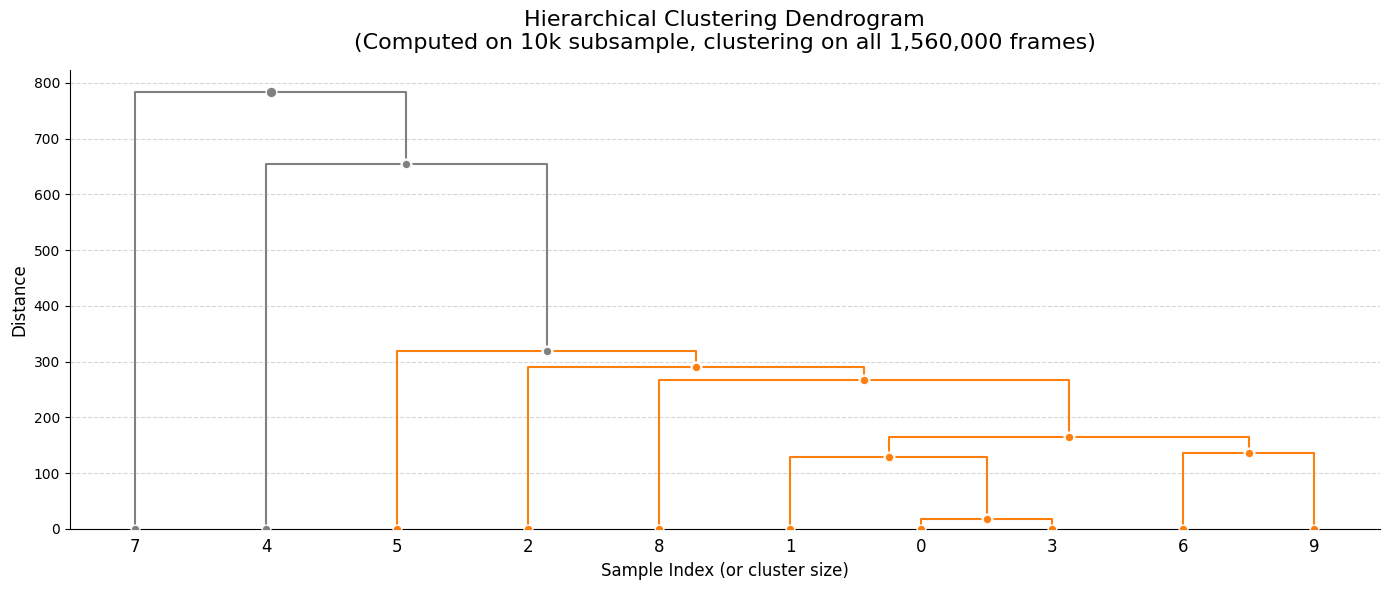

In [11]:
import importlib
import lp3d_analysis.clustering.plot
importlib.reload(lp3d_analysis.clustering.plot)
from lp3d_analysis.clustering.plot import plot_dendrogram, plot_enhanced_dendrogram

# # Plot dendrogram
# fig_dendro, ax = plot_dendrogram(
#     linkage_matrix,
#     title=f"Hierarchical Clustering Dendrogram\n(Computed on 10k subsample, clustering on all {len(features_scaled):,} frames)",
#     p=50
# )
# plt.show()


# Plot dendrogram
fig_dendro, ax = plot_enhanced_dendrogram(
    linkage_matrix,
    title=f"Hierarchical Clustering Dendrogram\n(Computed on 10k subsample, clustering on all {len(features_scaled):,} frames)",
    p=50
)
plt.show()

# fig_dendro, ax = plot_dendrogram(
#     linkage_matrix,
#     title=f"Hierarchical Clustering Dendrogram\n(Computed on 10k subsample, clustering on all {len(features_scaled):,} frames)",
# )
# plt.show()







✓ Radar plot saved to: /teamspace/studios/this_studio/outputs/ibl-mouse/plots/clustering/cluster_profiles.pdf


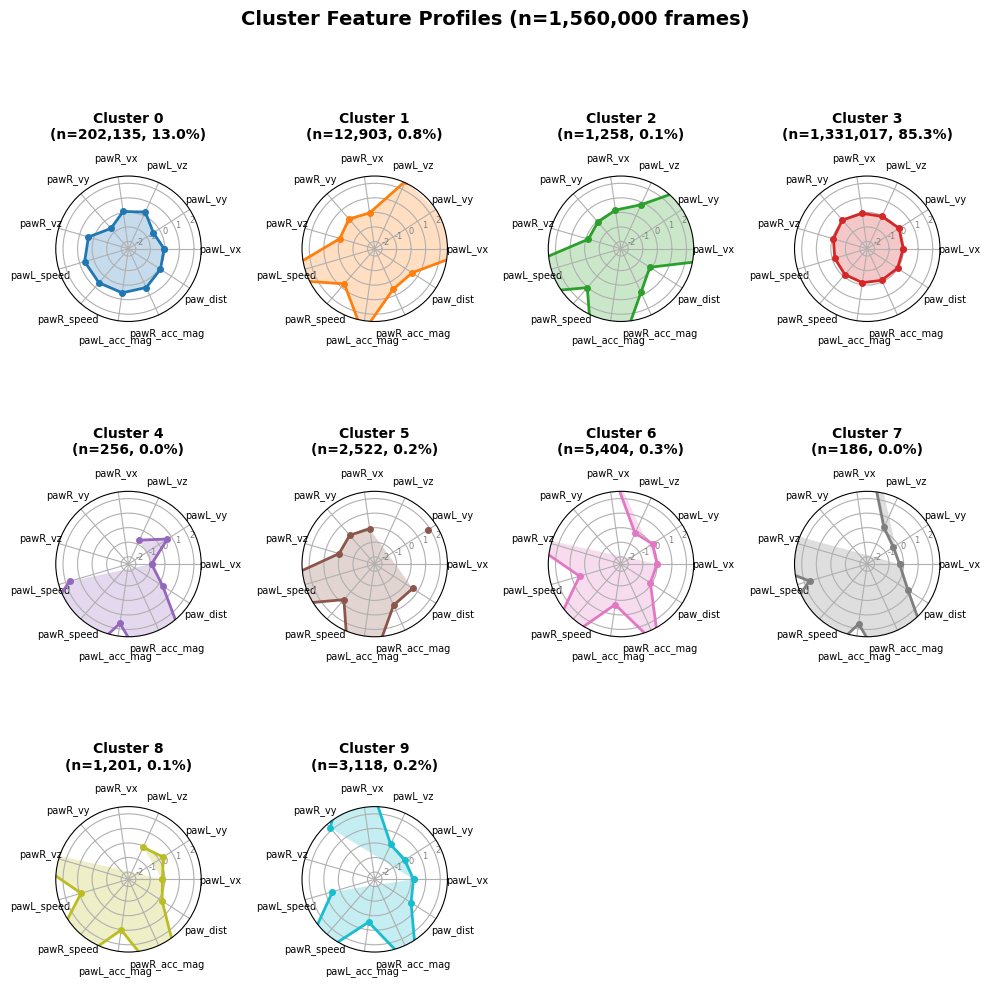

Cluster 0: n=202135, top features: [7 6 4]
Cluster 1: n=12903, top features: [0 1 6]
Cluster 2: n=1258, top features: [8 6 0]
Cluster 3: n=1331017, top features: [8 7 6]
Cluster 4: n=256, top features: [9 3 5]
Cluster 5: n=2522, top features: [8 6 0]
Cluster 6: n=5404, top features: [4 3 7]
Cluster 7: n=186, top features: [7 3 5]
Cluster 8: n=1201, top features: [9 7 3]
Cluster 9: n=3118, top features: [9 7 3]


In [14]:
from lp3d_analysis.clustering.plot import plot_cluster_radar_profiles


# Plot radar profiles for ALL clusters
fig, cluster_profiles = plot_cluster_radar_profiles(
    features=features_scaled,  # or features_clean
    labels=labels,
    feature_names=feature_names,
    title=f"Cluster Feature Profiles (n={len(labels):,} frames)",
    standardize=True,  # Set False if features_scaled is already standardized
    figsize=(10, 10),
    save_path="/teamspace/studios/this_studio/outputs/ibl-mouse/plots/clustering/cluster_profiles.pdf"
)
plt.show()


# Access the computed profiles for further analysis
for c, profile in cluster_profiles.items():
    print(f"Cluster {c}: n={profile['n']}, top features: {np.argsort(np.abs(profile['mean']))[-3:]}")


In [15]:
from lp3d_analysis.clustering.hierarchical_clustering import assign_cluster_names
# Run the new function
cluster_names = assign_cluster_names(features_clean, labels, feature_names)
print("\nCluster assignments (ALL models pooled):")
for cluster_id, name in cluster_names.items():
    n_points = np.sum(labels == cluster_id)
    print(f"  {name}: {n_points:,} points ({100*n_points/len(labels):.1f}%)")


Cluster assignments (ALL models pooled):
  C0_Vertical_Movement: 202,135 points (13.0%)
  C1_High_Acceleration+Vertical_Movement+Left_Paw_Dominant: 12,903 points (0.8%)
  C2_High_Acceleration+Running+Left_Paw_Dominant: 1,258 points (0.1%)
  C3_Stationary: 1,331,017 points (85.3%)
  C4_High_Acceleration+Running+Right_Paw_Dominant: 256 points (0.0%)
  C5_High_Acceleration+Running+Left_Paw_Dominant: 2,522 points (0.2%)
  C6_High_Acceleration+Vertical_Movement+Right_Paw_Dominant: 5,404 points (0.3%)
  C7_High_Acceleration+Vertical_Movement+Right_Paw_Dominant: 186 points (0.0%)
  C8_High_Acceleration+Vertical_Movement+Right_Paw_Dominant: 1,201 points (0.1%)
  C9_High_Acceleration+Running+Right_Paw_Dominant: 3,118 points (0.2%)


This is umap/tsne

In [14]:
# from lp3d_analysis.clustering.embedding import compute_embeddings, plot_embeddings_side_by_side, plot_embeddings_three_ways

# max_embed = len(features_scaled)
# embed_idx = np.random.choice(len(features_scaled), max_embed, replace=False)

# embedding_umap, embedding_tsne = compute_embeddings(
#     features_scaled[embed_idx],
#     umap_params={'n_components': 2, 'n_neighbors': 199, 'min_dist': 0.3, 'random_state': 42}, # used to be 50
#     tsne_params={'n_components': 2, 'perplexity': 30, 'random_state': 42}
# )

# # Plot embeddings
# fig_embed = plot_embeddings_side_by_side(
#     embedding_umap, embedding_tsne,
#     labels[embed_idx],
#     [session_labels_clean[i] for i in embed_idx],
#     cluster_names,
#     title="Multi-Session Clustering: UMAP vs t-SNE"
# )
# plt.show()

# # Plot with cluster, session, AND model coloring
# fig_embed = plot_embeddings_three_ways(
#     embedding_umap, embedding_tsne,
#     labels[embed_idx],
#     [session_labels_clean[i] for i in embed_idx],
#     [model_labels_clean[i] for i in embed_idx],
#     cluster_names,
#     model_short_names
# )
# plt.show()


In [16]:
import lp3d_analysis.clustering.utils
importlib.reload(lp3d_analysis.clustering.utils)
from lp3d_analysis.clustering.utils import compute_reprojection_errors_all_sessions, analyze_reprojection_by_cluster_pooled, identify_paw_moving_clusters
from lp3d_analysis.clustering.plot import plot_reprojection_by_cluster

# Compute reprojection errors
reproj_errors = compute_reprojection_errors_all_sessions(
    all_3d_data_raw, all_2d_data, camera_params_dir, views, keypoints
)

# For reprojection analysis, we need to align errors with the pooled labels
# This requires matching frames across models
df_errors = analyze_reprojection_by_cluster_pooled(
    reproj_errors, labels, session_labels_clean, model_labels_clean,
    valid_mask, keypoints, models_of_interest, model_short_names,
    keypoints_of_interest=['pawL', 'pawR']
)


Median Reprojection Error by Model and Cluster:
model    MVT+++EKS       ResNet50      
keypoint      pawL  pawR     pawL  pawR
cluster                                
0             0.74  0.69     1.26  1.24
1             1.01  1.05     2.36  1.40
2             1.87  1.03    11.78  1.79
3             0.60  0.65     0.82  1.05
4             6.59  1.85     2.20  9.65
5             1.92  0.96    13.62  1.47
6             0.76  0.71     0.99  2.50
7              NaN   NaN     2.26  7.43
8             1.06  1.28     1.32  9.14
9             1.59  1.34     1.46  7.02


ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (10,) and arg 1 with shape (9,).

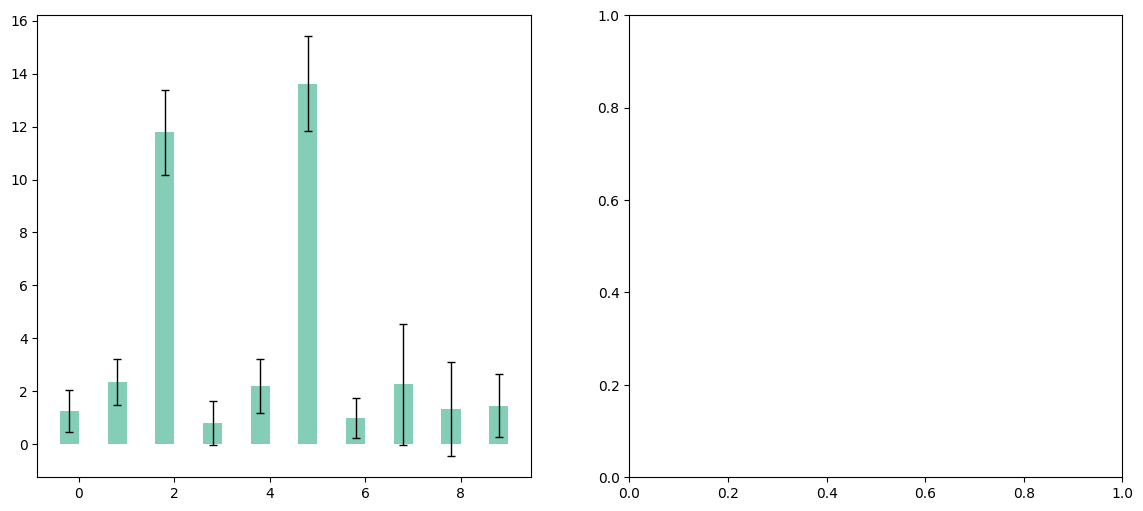

In [17]:
print("\nMedian Reprojection Error by Model and Cluster:")
print(df_errors.pivot_table(
    values='median_error', 
    index='cluster', 
    columns=['model', 'keypoint'],
    aggfunc='first'
).round(2))

# Plot reprojection errors
fig_reproj = plot_reprojection_by_cluster(df_errors, cluster_names)
plt.show()

# Identify paw-moving clusters
paw_moving_clusters = identify_paw_moving_clusters(
    features_clean, labels, feature_names, threshold_percentile=75
)

print(f"\nPaw-moving clusters (high velocity): {paw_moving_clusters}")
for c in paw_moving_clusters:
    print(f"  {cluster_names[c]}")
    

In [18]:
def plot_cluster_statistics_by_model(
    cluster_labels: np.ndarray,
    model_labels: List[str],
    reproj_errors: Dict,
    session_labels: List[str],
    valid_mask: np.ndarray,
    keypoints: List[str],
    models_of_interest: List[str],
    model_short_names: Dict[str, str],
    cluster_names: Dict[int, str],
    keypoints_of_interest: List[str] = ['pawL', 'pawR'],
    figsize: Tuple[int, int] = (18, 20),
    subsample_factor: int = 1,
):
    """
    Create combined visualization showing:
    1. Bar plot of points per cluster per model (separated by keypoint for consistency)
    2. Box-whisker plot of reprojection error distribution per cluster per model
    
    Args:
        cluster_labels: Cluster assignments for pooled (clean) data
        model_labels: Model name for each frame in pooled data (model_labels_clean)
        reproj_errors: dict[model][session] -> (T, K, n_views) array
        session_labels: Session name for each frame in pooled data (session_labels_clean)
        valid_mask: Boolean mask used to filter NaN rows
        keypoints: List of all keypoint names
        models_of_interest: List of model names to analyze
        model_short_names: Dict mapping full model name to short display name
        cluster_names: Dict mapping cluster ID to descriptive name
        keypoints_of_interest: Which keypoints to show reprojection errors for
        figsize: Figure size
        subsample_factor: Subsampling factor used during pooling
        
    Returns:
        fig: matplotlib figure
        stats_df: DataFrame with point counts per model per cluster
    """
    from scipy import stats as scipy_stats
    
    model_labels_arr = np.array(model_labels)
    session_labels_arr = np.array(session_labels)
    
    unique_clusters = np.unique(cluster_labels)
    n_clusters = len(unique_clusters)
    n_keypoints = len(keypoints_of_interest)
    kp_indices = {kp: keypoints.index(kp) for kp in keypoints_of_interest}
    
    # ============================================================
    # STEP 1: Compute points per cluster per model
    # ============================================================
    points_per_cluster = {}
    for model_name in models_of_interest:
        model_mask = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        
        points_per_cluster[model_name] = []
        for c in unique_clusters:
            n_points = np.sum(model_cluster_labels == c)
            points_per_cluster[model_name].append(n_points)
    
    # ============================================================
    # STEP 2: Collect reprojection errors per cluster per model per keypoint
    # ============================================================
    reproj_per_cluster_all = {
        model_name: {kp: {} for kp in keypoints_of_interest} 
        for model_name in models_of_interest
    }
    
    for model_name in models_of_interest:
        if model_name not in reproj_errors:
            continue
        
        model_mask = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        model_session_labels = session_labels_arr[model_mask]
        
        unique_sessions = list(dict.fromkeys(model_session_labels))
        
        # Build aligned errors for this model
        session_errors_dict = {}
        for session_name in unique_sessions:
            if session_name not in reproj_errors[model_name]:
                continue
            
            session_errors = reproj_errors[model_name][session_name]
            session_errors_subsampled = session_errors[::subsample_factor]
            
            session_mask = model_session_labels == session_name
            session_cluster_labels = model_cluster_labels[session_mask]
            
            n_session_frames = len(session_cluster_labels)
            
            if n_session_frames > 0 and len(session_errors_subsampled) >= n_session_frames:
                session_errors_dict[session_name] = (
                    session_errors_subsampled[:n_session_frames],
                    session_cluster_labels
                )
        
        # Collect errors per cluster per keypoint
        for kp_name, kp_idx in kp_indices.items():
            for c in unique_clusters:
                all_errors = []
                for session_name, (sess_errors, sess_clusters) in session_errors_dict.items():
                    cluster_mask = sess_clusters == c
                    if cluster_mask.any():
                        kp_errors = sess_errors[cluster_mask, kp_idx, :]
                        kp_errors_mean_views = np.nanmean(kp_errors, axis=1)
                        kp_errors_clean = kp_errors_mean_views[~np.isnan(kp_errors_mean_views)]
                        all_errors.extend(kp_errors_clean)
                
                reproj_per_cluster_all[model_name][kp_name][c] = np.array(all_errors)
    
    # ============================================================
    # STEP 3: Create plots
    # ============================================================
    fig, axes = plt.subplots(n_keypoints + 1, 1, figsize=figsize)
    if n_keypoints + 1 == 1:
        axes = [axes]
    
    bar_width = 0.8 / len(models_of_interest)
    x = np.arange(n_clusters)
    model_names_plot = [m for m in models_of_interest if m in points_per_cluster]
    colors = plt.cm.Set2(np.linspace(0, 1, len(model_names_plot)))
    
    # ============================================================
    # Plot 1: Points per cluster (BAR PLOT) - LOG SCALE
    # ============================================================
    ax1 = axes[0]
    for i, model_name in enumerate(model_names_plot):
        offset = (i - len(model_names_plot)/2 + 0.5) * bar_width
        # Add 1 to avoid log(0) issues
        counts = np.array(points_per_cluster[model_name]) + 1
        ax1.bar(x + offset, counts, bar_width, 
                label=model_short_names.get(model_name, model_name), 
                color=colors[i], alpha=0.8)
    
    ax1.set_xlabel('Cluster')
    ax1.set_ylabel('Number of Points (log scale)')
    ax1.set_title('Points per Cluster by Model (Log Scale)')
    ax1.set_xticks(x)
    xlabels = [cluster_names.get(c, f'C{c}').split('_')[0] for c in unique_clusters]
    ax1.set_xticklabels(xlabels, rotation=45, ha='right')
    ax1.legend(fontsize=9)
    ax1.grid(axis='y', alpha=0.3)
    ax1.set_yscale('log')
    
    # Add count labels on bars (showing actual counts, not +1)
    for i, model_name in enumerate(model_names_plot):
        offset = (i - len(model_names_plot)/2 + 0.5) * bar_width
        for j, count in enumerate(points_per_cluster[model_name]):
            if count > 0:
                ax1.text(j + offset, count + 1, f'{count}', ha='center', va='bottom', 
                        fontsize=7, rotation=90)
    
    # ============================================================
    # Plots 2+: Reprojection error per cluster (BOX-WHISKER PLOT) - one per keypoint
    # ============================================================
    for kp_idx, kp_name in enumerate(keypoints_of_interest):
        ax = axes[kp_idx + 1]
        
        box_width = 0.8 / len(model_names_plot)
        positions_all = []
        data_all = []
        colors_all = []
        
        for i, model_name in enumerate(model_names_plot):
            if model_name not in reproj_per_cluster_all:
                continue
            
            for j, c in enumerate(unique_clusters):
                errors = reproj_per_cluster_all[model_name][kp_name].get(c, np.array([]))
                if len(errors) > 0:
                    data_all.append(errors)
                    offset = (i - len(model_names_plot)/2 + 0.5) * box_width
                    positions_all.append(j + offset)
                    colors_all.append(colors[i])
        
        if data_all:
            bp = ax.boxplot(data_all, positions=positions_all, widths=box_width*0.8,
                           patch_artist=True, showfliers=False)
            
            for patch, color in zip(bp['boxes'], colors_all):
                patch.set_facecolor(color)
                patch.set_alpha(0.7)
            
            for element in ['whiskers', 'caps', 'medians']:
                plt.setp(bp[element], color='black', linewidth=1)
            plt.setp(bp['medians'], color='red', linewidth=1.5)
        
        # Add legend
        legend_patches = [plt.Rectangle((0,0),1,1, facecolor=colors[i], alpha=0.7, 
                                        label=model_short_names.get(m, m)) 
                         for i, m in enumerate(model_names_plot)]
        ax.legend(handles=legend_patches, fontsize=9)
        
        ax.set_xlabel('Cluster')
        ax.set_ylabel('Reprojection Error (px)')
        ax.set_title(f'Reprojection Error Distribution - {kp_name}')
        ax.set_xticks(x)
        ax.set_xticklabels(xlabels, rotation=45, ha='right')
        ax.grid(axis='y', alpha=0.3)
    
    fig.suptitle('Cluster Statistics by Model (Pooled Hierarchical Clustering)', fontsize=14, y=1.02)
    plt.tight_layout()
    
    # ============================================================
    # Create summary DataFrame
    # ============================================================
    stats_records = []
    for model_name in model_names_plot:
        for j, c in enumerate(unique_clusters):
            record = {
                'model': model_short_names.get(model_name, model_name),
                'model_full': model_name,
                'cluster': c,
                'cluster_name': cluster_names.get(c, f'C{c}'),
                'n_points': points_per_cluster[model_name][j],
            }
            stats_records.append(record)
    
    stats_df = pd.DataFrame(stats_records)
    
    return fig, stats_df

In [19]:
def plot_cluster_statistics_by_model(
    cluster_labels: np.ndarray,
    model_labels: List[str],
    reproj_errors: Dict,
    session_labels: List[str],
    valid_mask: np.ndarray,
    keypoints: List[str],
    models_of_interest: List[str],
    model_short_names: Dict[str, str],
    cluster_names: Dict[int, str],
    keypoints_of_interest: List[str] = ['pawL', 'pawR'],
    figsize: Tuple[int, int] = (18, 20),
    subsample_factor: int = 1,
    save_pdf: bool = False,
    pdf_filename: str = "cluster_statistics.pdf",
):
    from scipy import stats as scipy_stats
    import matplotlib.patches as mpatches

    # -------------------------
    # Color & label definitions (consistent with other functions)
    # -------------------------
    model_color_map = {
        'test_200_multiview_resnet50_new_labels_ensemble_median':             '#d62728',
        'MVT_3d_aug_patch_median_new':     '#7b2d8b',
        'test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf': '#2ca02c',
        'resnet50_anipose_new':            '#ff7f0e',
    }
    # Fallback: assign colors from Set2 for any model not in the map
    fallback_colors = plt.cm.Set2(np.linspace(0, 1, len(models_of_interest)))
    def get_color(model_name, idx):
        return model_color_map.get(model_name, fallback_colors[idx])

    model_labels_arr   = np.array(model_labels)
    session_labels_arr = np.array(session_labels)
    unique_clusters    = np.unique(cluster_labels)
    n_clusters         = len(unique_clusters)
    n_keypoints        = len(keypoints_of_interest)
    kp_indices         = {kp: keypoints.index(kp) for kp in keypoints_of_interest}

    # ============================================================
    # STEP 1: Points per cluster per model
    # ============================================================
    points_per_cluster = {}
    for model_name in models_of_interest:
        model_mask = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        points_per_cluster[model_name] = [
            np.sum(model_cluster_labels == c) for c in unique_clusters
        ]

    # ============================================================
    # STEP 2: Reprojection errors per cluster per model per keypoint
    # ============================================================
    reproj_per_cluster_all = {
        model_name: {kp: {} for kp in keypoints_of_interest}
        for model_name in models_of_interest
    }

    for model_name in models_of_interest:
        if model_name not in reproj_errors:
            continue

        model_mask           = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        model_session_labels = session_labels_arr[model_mask]
        unique_sessions      = list(dict.fromkeys(model_session_labels))

        session_errors_dict = {}
        for session_name in unique_sessions:
            if session_name not in reproj_errors[model_name]:
                continue
            session_errors            = reproj_errors[model_name][session_name]
            session_errors_subsampled = session_errors[::subsample_factor]
            session_mask              = model_session_labels == session_name
            session_cluster_labels    = model_cluster_labels[session_mask]
            n_session_frames          = len(session_cluster_labels)
            if n_session_frames > 0 and len(session_errors_subsampled) >= n_session_frames:
                session_errors_dict[session_name] = (
                    session_errors_subsampled[:n_session_frames],
                    session_cluster_labels
                )

        for kp_name, kp_idx in kp_indices.items():
            for c in unique_clusters:
                all_errors = []
                for session_name, (sess_errors, sess_clusters) in session_errors_dict.items():
                    cluster_mask = sess_clusters == c
                    if cluster_mask.any():
                        kp_errors            = sess_errors[cluster_mask, kp_idx, :]
                        kp_errors_mean_views = np.nanmean(kp_errors, axis=1)
                        kp_errors_clean      = kp_errors_mean_views[~np.isnan(kp_errors_mean_views)]
                        all_errors.extend(kp_errors_clean)
                reproj_per_cluster_all[model_name][kp_name][c] = np.array(all_errors)

    # ============================================================
    # STEP 3: Layout
    # ============================================================
    fig, axes = plt.subplots(n_keypoints + 1, 1, figsize=figsize,
                             gridspec_kw={'hspace': 0.45})
    if n_keypoints + 1 == 1:
        axes = [axes]

    bar_width        = 0.8 / len(models_of_interest)
    x                = np.arange(n_clusters)
    model_names_plot = [m for m in models_of_interest if m in points_per_cluster]
    xlabels          = [cluster_names.get(c, f'C{c}').split('_')[0] for c in unique_clusters]

    # ============================================================
    # Plot 1: Bar plot — log scale, colored bars, white-ish style
    # ============================================================
    ax1 = axes[0]

    for i, model_name in enumerate(model_names_plot):
        color  = get_color(model_name, i)
        offset = (i - len(model_names_plot) / 2 + 0.5) * bar_width
        counts = np.array(points_per_cluster[model_name]) + 1  # avoid log(0)
        ax1.bar(x + offset, counts, bar_width,
                label=model_short_names.get(model_name, model_name),
                facecolor='white', edgecolor=color, linewidth=1.3, alpha=1.0)

        # Count labels
        for j, count in enumerate(points_per_cluster[model_name]):
            if count > 0:
                ax1.text(j + offset, count + 1, f'{count}',
                         ha='center', va='bottom', fontsize=7,
                         rotation=90, color=color)

    ax1.set_ylabel('Number of Points (log scale)', fontsize=11)
    ax1.set_title('Points per Cluster by Model', fontsize=12, fontweight='bold', pad=8)
    ax1.set_xticks(x)
    ax1.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=9)
    ax1.set_yscale('log')
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
    ax1.set_axisbelow(True)

    # Legend
    legend_handles = [
        mpatches.Patch(facecolor='white',
                       edgecolor=get_color(m, i),
                       linewidth=1.5,
                       label=model_short_names.get(m, m))
        for i, m in enumerate(model_names_plot)
    ]
    ax1.legend(handles=legend_handles, fontsize=9, frameon=True,
               framealpha=0.9, edgecolor='lightgray',
               bbox_to_anchor=(1.01, 1), loc='upper left')

    # ============================================================
    # Plots 2+: Boxplots — white fill, colored outline, red median
    # ============================================================
    for kp_i, kp_name in enumerate(keypoints_of_interest):
        ax        = axes[kp_i + 1]
        box_width = 0.8 / len(model_names_plot)

        boxplot_data      = []
        boxplot_positions = []
        boxplot_colors    = []

        for i, model_name in enumerate(model_names_plot):
            if model_name not in reproj_per_cluster_all:
                continue
            color = get_color(model_name, i)

            for j, c in enumerate(unique_clusters):
                errors = reproj_per_cluster_all[model_name][kp_name].get(c, np.array([]))
                if len(errors) > 0:
                    offset = (i - len(model_names_plot) / 2 + 0.5) * box_width
                    boxplot_data.append(errors)
                    boxplot_positions.append(j + offset)
                    boxplot_colors.append(color)

        if boxplot_data:
            bp = ax.boxplot(
                boxplot_data,
                positions=boxplot_positions,
                widths=box_width * 0.82,
                patch_artist=True,
                showfliers=False,
                zorder=2,
                medianprops=dict(color='black', linewidth=2.0),
                boxprops=dict(facecolor='white', linewidth=1.2),
                whiskerprops=dict(linewidth=1.0),
                capprops=dict(linewidth=1.0),
                flierprops=dict(marker='', linestyle='none'),
            )

            # Per-box color for outline, whiskers, caps
            for idx, color in enumerate(boxplot_colors):
                bp['boxes'][idx].set_edgecolor(color)
                bp['whiskers'][idx * 2].set_color(color)
                bp['whiskers'][idx * 2 + 1].set_color(color)
                bp['caps'][idx * 2].set_color(color)
                bp['caps'][idx * 2 + 1].set_color(color)

        ax.set_ylabel('Reprojection Error (px)', fontsize=11)
        ax.set_title(f'Reprojection Error — {kp_name}',
                     fontsize=12, fontweight='bold', pad=8)
        ax.set_xticks(x)
        ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
        ax.set_axisbelow(True)

        legend_handles = [
            mpatches.Patch(facecolor='white',
                           edgecolor=get_color(m, i),
                           linewidth=1.5,
                           label=model_short_names.get(m, m))
            for i, m in enumerate(model_names_plot)
        ]
        ax.legend(handles=legend_handles, fontsize=9, frameon=True,
                  framealpha=0.9, edgecolor='lightgray',
                  bbox_to_anchor=(1.01, 1), loc='upper left')

    fig.suptitle('Cluster Statistics by Model', fontsize=14,
                 fontweight='bold', y=1.01)
    plt.tight_layout()

    # ============================================================
    # Save PDF
    # ============================================================
    if save_pdf:
        save_dir = "/teamspace/studios/this_studio/outputs/ibl-mouse/plots/clustering"
        os.makedirs(save_dir, exist_ok=True)
        full_path = os.path.join(save_dir, pdf_filename)
        fig.savefig(full_path, format='pdf', bbox_inches='tight', dpi=300)
        print(f"Saved: {full_path}")

    # ============================================================
    # Summary DataFrame
    # ============================================================
    stats_records = []
    for model_name in model_names_plot:
        for j, c in enumerate(unique_clusters):
            stats_records.append({
                'model':        model_short_names.get(model_name, model_name),
                'model_full':   model_name,
                'cluster':      c,
                'cluster_name': cluster_names.get(c, f'C{c}'),
                'n_points':     points_per_cluster[model_name][j],
            })

    stats_df = pd.DataFrame(stats_records)
    return fig, stats_df

/tmp/ipykernel_41284/3327738213.py:221: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


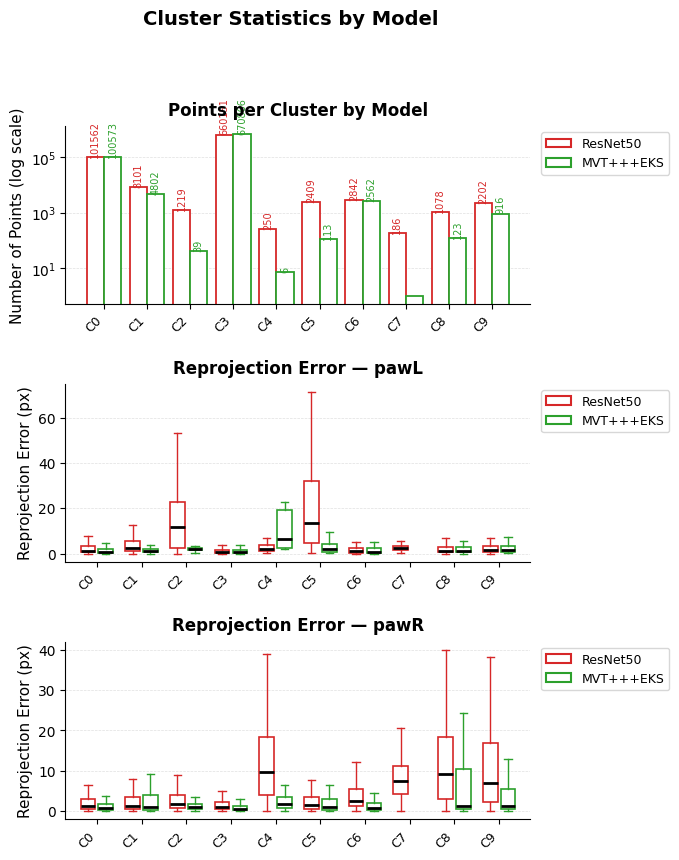


Points per Model per Cluster:
model                                               MVT+++EKS  ResNet50
cluster_name                                                           
C0_Vertical_Movement                                   100573    101562
C1_High_Acceleration+Vertical_Movement+Left_Paw...       4802      8101
C2_High_Acceleration+Running+Left_Paw_Dominant             39      1219
C3_Stationary                                          670866    660151
C4_High_Acceleration+Running+Right_Paw_Dominant             6       250
C5_High_Acceleration+Running+Left_Paw_Dominant            113      2409
C6_High_Acceleration+Vertical_Movement+Right_Pa...       2562      2842
C7_High_Acceleration+Vertical_Movement+Right_Pa...          0       186
C8_High_Acceleration+Vertical_Movement+Right_Pa...        123      1078
C9_High_Acceleration+Running+Right_Paw_Dominant           916      2202


In [20]:
fig_stats, stats_df = plot_cluster_statistics_by_model(
    cluster_labels=labels,
    model_labels=model_labels_clean,
    reproj_errors=reproj_errors,
    session_labels=session_labels_clean,
    valid_mask=valid_mask,
    keypoints=keypoints,
    models_of_interest=models_of_interest,
    model_short_names=model_short_names,
    cluster_names=cluster_names,
    keypoints_of_interest=['pawL', 'pawR'],
    figsize=(6, 9),
    save_pdf=False,
    pdf_filename="cluster_statistics.pdf"
)
plt.show()

# Print summary table
print("\nPoints per Model per Cluster:")
print(stats_df.pivot_table(
    values='n_points', 
    index='cluster_name', 
    columns='model',
    aggfunc='first'
))

In [21]:
def analyze_frames_per_cluster_by_session(
    cluster_labels: np.ndarray,
    model_labels: List[str],
    session_labels: List[str],
    models_of_interest: List[str],
    model_short_names: Dict[str, str],
    cluster_names: Dict[int, str],
    clusters_of_interest: Optional[List[int]] = None,
    show_frame_indices: bool = True,
    max_frames_to_show: int = 10,
):
    """
    Analyze which frames from each session are in each cluster, broken down by model.
    
    Args:
        cluster_labels: Cluster assignments for pooled (clean) data
        model_labels: Model name for each frame in pooled data (model_labels_clean)
        session_labels: Session name for each frame in pooled data (session_labels_clean)
        models_of_interest: List of model names to analyze
        model_short_names: Dict mapping full model name to short display name
        cluster_names: Dict mapping cluster ID to descriptive name
        clusters_of_interest: Which clusters to analyze (None = all)
        show_frame_indices: Whether to print frame indices
        max_frames_to_show: Max number of frame indices to print per session
        
    Returns:
        frames_per_cluster: Nested dict [model][cluster][session] -> frame indices (local to session)
        summary_df: DataFrame with counts per model/cluster/session
    """
    model_labels_arr = np.array(model_labels)
    session_labels_arr = np.array(session_labels)
    
    unique_clusters = np.unique(cluster_labels)
    if clusters_of_interest is None:
        clusters_of_interest = list(unique_clusters)
    
    frames_per_cluster = {}
    summary_records = []
    
    for model_name in models_of_interest:
        # Get mask for this model
        model_mask = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        model_session_labels = session_labels_arr[model_mask]
        
        # Get unique sessions for this model (in order they appear)
        unique_sessions = list(dict.fromkeys(model_session_labels))
        
        frames_per_cluster[model_name] = {}
        
        print(f"\n{'='*70}")
        print(f"MODEL: {model_short_names.get(model_name, model_name)}")
        print(f"{'='*70}")
        print(f"Sessions: {len(unique_sessions)}")
        print(f"Total frames: {len(model_cluster_labels)}")
        
        for c in clusters_of_interest:
            cluster_name = cluster_names.get(c, f'Cluster {c}')
            cluster_mask = model_cluster_labels == c
            n_cluster_frames = np.sum(cluster_mask)
            
            frames_per_cluster[model_name][c] = {}
            
            print(f"\n  {'-'*60}")
            print(f"  CLUSTER {c}: {cluster_name}")
            print(f"  Total frames in cluster: {n_cluster_frames}")
            print(f"  {'-'*60}")
            
            # For each session, find which frames (local indices) are in this cluster
            session_start_idx = 0
            for session_name in unique_sessions:
                session_mask = model_session_labels == session_name
                n_session_frames = np.sum(session_mask)
                
                # Get indices within this model's data where session matches
                session_indices = np.where(session_mask)[0]
                
                # Find which of these are in the cluster
                in_cluster_mask = model_cluster_labels[session_indices] == c
                frames_in_cluster = np.where(in_cluster_mask)[0]  # Local to session
                
                n_frames = len(frames_in_cluster)
                frames_per_cluster[model_name][c][session_name] = frames_in_cluster
                
                # Record for summary
                summary_records.append({
                    'model': model_short_names.get(model_name, model_name),
                    'model_full': model_name,
                    'cluster': c,
                    'cluster_name': cluster_name,
                    'session': session_name,
                    'n_frames_in_cluster': n_frames,
                    'n_session_frames': n_session_frames,
                    'pct_of_session': 100 * n_frames / n_session_frames if n_session_frames > 0 else 0,
                })
                
                if n_frames > 0:
                    # Shorten session name for display
                    session_short = session_name.split('.')[-1][:12] if '.' in session_name else session_name[:20]
                    
                    print(f"\n    Session: {session_short}...")
                    print(f"      Frames in cluster: {n_frames} / {n_session_frames} ({100*n_frames/n_session_frames:.1f}%)")
                    
                    if show_frame_indices:
                        if len(frames_in_cluster) <= max_frames_to_show * 2:
                            print(f"      Frame indices: {frames_in_cluster.tolist()}")
                        else:
                            print(f"      First {max_frames_to_show}: {frames_in_cluster[:max_frames_to_show].tolist()}")
                            print(f"      Last {max_frames_to_show}:  {frames_in_cluster[-max_frames_to_show:].tolist()}")
    
    summary_df = pd.DataFrame(summary_records)
    
    return frames_per_cluster, summary_df

# Analyze all clusters
frames_per_cluster, summary_df = analyze_frames_per_cluster_by_session(
    cluster_labels=labels,
    model_labels=model_labels_clean,
    session_labels=session_labels_clean,
    models_of_interest=models_of_interest,
    model_short_names=model_short_names,
    cluster_names=cluster_names,
    clusters_of_interest=None,  # or specify e.g. [0, 1, 2]
    show_frame_indices=True,
    max_frames_to_show=10,
)

# View summary table - frames per session per cluster
print("\n\nSummary: Frames per Session per Cluster")
pivot = summary_df.pivot_table(
    values='n_frames_in_cluster',
    index=['model', 'session'],
    columns='cluster_name',
    aggfunc='first',
    fill_value=0
)
print(pivot)

# Or view percentage of each session in each cluster
print("\n\nPercentage of Session in Each Cluster")
pivot_pct = summary_df.pivot_table(
    values='pct_of_session',
    index=['model', 'session'],
    columns='cluster_name',
    aggfunc='first',
    fill_value=0
).round(1)
print(pivot_pct)


MODEL: ResNet50
Sessions: 39
Total frames: 780000

  ------------------------------------------------------------
  CLUSTER 0: C0_Vertical_Movement
  Total frames in cluster: 101562
  ------------------------------------------------------------

    Session: 0841d188-8ef...
      Frames in cluster: 2973 / 20000 (14.9%)
      First 10: [90, 91, 96, 98, 99, 104, 105, 106, 107, 112]
      Last 10:  [19974, 19975, 19977, 19978, 19982, 19986, 19989, 19990, 19991, 19992]

    Session: 15763234-d21...
      Frames in cluster: 2736 / 20000 (13.7%)
      First 10: [1, 2, 4, 9, 13, 15, 31, 32, 267, 345]
      Last 10:  [19964, 19966, 19973, 19975, 19984, 19986, 19987, 19990, 19991, 19997]

    Session: 15b69921-d47...
      Frames in cluster: 2680 / 20000 (13.4%)
      First 10: [440, 446, 447, 569, 570, 571, 572, 573, 574, 576]
      Last 10:  [19989, 19990, 19991, 19992, 19993, 19994, 19995, 19997, 19998, 19999]

    Session: 4b00df29-376...
      Frames in cluster: 2161 / 20000 (10.8%)
     


    Session: f115196e-8df...
      Frames in cluster: 1847 / 20000 (9.2%)
      First 10: [481, 1338, 1340, 1346, 1347, 1348, 1349, 1379, 1386, 1392]
      Last 10:  [19760, 19767, 19769, 19774, 19779, 19780, 19799, 19802, 19808, 19811]

    Session: f140a2ec-fd4...
      Frames in cluster: 1833 / 20000 (9.2%)
      First 10: [237, 3503, 3596, 3597, 3609, 3626, 3627, 3629, 3630, 3635]
      Last 10:  [19974, 19975, 19976, 19977, 19978, 19979, 19986, 19990, 19991, 19993]

    Session: f3ce3197-d53...
      Frames in cluster: 1989 / 20000 (9.9%)
      First 10: [25, 38, 48, 49, 50, 51, 52, 53, 54, 55]
      Last 10:  [19761, 19762, 19805, 19806, 19897, 19898, 19901, 19906, 19907, 19909]

    Session: ff96bfe1-d92...
      Frames in cluster: 1752 / 20000 (8.8%)
      First 10: [45, 46, 47, 48, 49, 50, 51, 53, 56, 58]
      Last 10:  [19751, 19754, 19789, 19792, 19793, 19794, 19795, 19810, 19811, 19812]

  ------------------------------------------------------------
  CLUSTER 1: C1_High_A

In [23]:
def query_frame_cluster_assignment(
    frame_idx: int,
    session_name: str,
    cluster_labels: np.ndarray,
    model_labels: List[str],
    session_labels: List[str],
    models_of_interest: List[str],
    model_short_names: Dict[str, str],
    cluster_names: Dict[int, str],
):
    """
    Query which cluster a specific frame belongs to for each model.
    
    Args:
        frame_idx: The frame index (local to the session) to query
        session_name: The session name (or partial match)
        cluster_labels: Cluster assignments for pooled (clean) data
        model_labels: Model name for each frame in pooled data (model_labels_clean)
        session_labels: Session name for each frame in pooled data (session_labels_clean)
        models_of_interest: List of model names to analyze
        model_short_names: Dict mapping full model name to short display name
        cluster_names: Dict mapping cluster ID to descriptive name
        
    Returns:
        results: Dict with cluster assignment per model
    """
    model_labels_arr = np.array(model_labels)
    session_labels_arr = np.array(session_labels)
    
    # Find matching session (allow partial match)
    unique_sessions = list(set(session_labels))
    matching_sessions = [s for s in unique_sessions if session_name in s]
    
    if len(matching_sessions) == 0:
        print(f"No session found matching '{session_name}'")
        print(f"Available sessions: {unique_sessions}")
        return None
    elif len(matching_sessions) > 1:
        print(f"Multiple sessions match '{session_name}':")
        for s in matching_sessions:
            print(f"  - {s}")
        print("Please provide a more specific session name.")
        return None
    
    full_session_name = matching_sessions[0]
    print(f"Session: {full_session_name}")
    print(f"Frame: {frame_idx}")
    print(f"\n{'='*60}")
    
    results = {}
    cluster_ids = []
    
    for model_name in models_of_interest:
        # Get data for this model
        model_mask = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        model_session_labels = session_labels_arr[model_mask]
        
        # Find frames from this session for this model
        session_mask = model_session_labels == full_session_name
        session_indices = np.where(session_mask)[0]
        
        if len(session_indices) == 0:
            print(f"{model_short_names.get(model_name, model_name):20s}: Session not found for this model")
            results[model_name] = None
            continue
        
        if frame_idx >= len(session_indices):
            print(f"{model_short_names.get(model_name, model_name):20s}: Frame {frame_idx} out of range (max: {len(session_indices)-1})")
            results[model_name] = None
            continue
        
        # Get the cluster for this frame
        # session_indices[frame_idx] gives us the index in model_cluster_labels
        cluster_id = model_cluster_labels[session_indices[frame_idx]]
        cluster_name = cluster_names.get(cluster_id, f'Cluster {cluster_id}')
        
        results[model_name] = {
            'cluster_id': cluster_id,
            'cluster_name': cluster_name,
        }
        cluster_ids.append(cluster_id)
        
        print(f"{model_short_names.get(model_name, model_name):20s}: Cluster {cluster_id} ({cluster_name})")
    
    # Check agreement
    print(f"\n{'='*60}")
    valid_clusters = [c for c in cluster_ids if c is not None]
    if len(valid_clusters) > 1:
        if len(set(valid_clusters)) == 1:
            print(f"✓ AGREEMENT: All models assign frame {frame_idx} to the same cluster")
        else:
            print(f"✗ DISAGREEMENT: Models assign frame {frame_idx} to different clusters")
    
    return results


def query_frame_range_agreement(
    frame_start: int,
    frame_end: int,
    session_name: str,
    cluster_labels: np.ndarray,
    model_labels: List[str],
    session_labels: List[str],
    models_of_interest: List[str],
    model_short_names: Dict[str, str],
    cluster_names: Dict[int, str],
):
    """
    Query cluster assignments for a range of frames and compute agreement statistics.
    
    Args:
        frame_start: Start frame index (inclusive)
        frame_end: End frame index (exclusive)
        session_name: The session name (or partial match)
        ... (same as query_frame_cluster_assignment)
        
    Returns:
        agreement_df: DataFrame with cluster assignments per frame per model
        agreement_rate: Percentage of frames where all models agree
    """
    model_labels_arr = np.array(model_labels)
    session_labels_arr = np.array(session_labels)
    
    # Find matching session
    unique_sessions = list(set(session_labels))
    matching_sessions = [s for s in unique_sessions if session_name in s]
    
    if len(matching_sessions) != 1:
        print(f"Session matching issue. Found: {matching_sessions}")
        return None, None
    
    full_session_name = matching_sessions[0]
    
    # Build cluster assignments for each model
    model_assignments = {}
    for model_name in models_of_interest:
        model_mask = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        model_session_labels = session_labels_arr[model_mask]
        
        session_mask = model_session_labels == full_session_name
        session_indices = np.where(session_mask)[0]
        
        if len(session_indices) == 0:
            continue
        
        # Get clusters for frame range
        assignments = []
        for frame_idx in range(frame_start, min(frame_end, len(session_indices))):
            cluster_id = model_cluster_labels[session_indices[frame_idx]]
            assignments.append(cluster_id)
        
        model_assignments[model_short_names.get(model_name, model_name)] = assignments
    
    # Create DataFrame
    records = []
    for i, frame_idx in enumerate(range(frame_start, frame_end)):
        record = {'frame': frame_idx}
        clusters_this_frame = []
        for model_short, assignments in model_assignments.items():
            if i < len(assignments):
                cluster_id = assignments[i]
                record[model_short] = cluster_id
                record[f'{model_short}_name'] = cluster_names.get(cluster_id, f'C{cluster_id}')
                clusters_this_frame.append(cluster_id)
        
        # Check agreement
        if len(clusters_this_frame) > 1:
            record['agree'] = len(set(clusters_this_frame)) == 1
        else:
            record['agree'] = None
        
        records.append(record)
    
    agreement_df = pd.DataFrame(records)
    
    # Compute agreement rate
    valid_agree = agreement_df['agree'].dropna()
    agreement_rate = 100 * valid_agree.sum() / len(valid_agree) if len(valid_agree) > 0 else 0
    
    print(f"Session: {full_session_name}")
    print(f"Frame range: {frame_start} - {frame_end}")
    print(f"Agreement rate: {agreement_rate:.1f}%")
    print(f"\nDisagreement frames:")
    disagreements = agreement_df[agreement_df['agree'] == False]
    if len(disagreements) > 0:
        print(disagreements.to_string(index=False))
    else:
        print("  None - all frames agree!")
    
    return agreement_df, agreement_rate

In [24]:
# Query frame 2545 in a specific session
result = query_frame_cluster_assignment(
    frame_idx=2723,
    session_name='1b71',  # partial match is OK
    cluster_labels=labels,
    model_labels=model_labels_clean,
    session_labels=session_labels_clean,
    models_of_interest=models_of_interest,
    model_short_names=model_short_names,
    cluster_names=cluster_names,
)

Session: _iblrig.downsampled.1b715600-0cbc-442c-bd00-5b0ac2865de1
Frame: 2723

ResNet50            : Cluster 8 (C8_High_Acceleration+Vertical_Movement+Right_Paw_Dominant)
MVT+++EKS           : Cluster 3 (C3_Stationary)

✗ DISAGREEMENT: Models assign frame 2723 to different clusters


In [25]:
def query_frame_range_agreement(
    frame_start: int,
    frame_end: int,
    session_name: str,
    cluster_labels: np.ndarray,
    model_labels: List[str],
    session_labels: List[str],
    models_of_interest: List[str],
    model_short_names: Dict[str, str],
    cluster_names: Dict[int, str],
):
    """
    Query cluster assignments for a range of frames and compute agreement statistics.
    
    Args:
        frame_start: Start frame index (inclusive)
        frame_end: End frame index (exclusive)
        session_name: The session name (or partial match)
        ... (same as query_frame_cluster_assignment)
        
    Returns:
        agreement_df: DataFrame with cluster assignments per frame per model
        agreement_rate: Percentage of frames where all models agree
    """
    model_labels_arr = np.array(model_labels)
    session_labels_arr = np.array(session_labels)
    
    # Find matching session
    unique_sessions = list(set(session_labels))
    matching_sessions = [s for s in unique_sessions if session_name in s]
    
    if len(matching_sessions) != 1:
        print(f"Session matching issue. Found: {matching_sessions}")
        return None, None
    
    full_session_name = matching_sessions[0]
    
    # Build cluster assignments for each model
    model_assignments = {}
    for model_name in models_of_interest:
        model_mask = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        model_session_labels = session_labels_arr[model_mask]
        
        session_mask = model_session_labels == full_session_name
        session_indices = np.where(session_mask)[0]
        
        if len(session_indices) == 0:
            continue
        
        # Get clusters for frame range
        assignments = []
        for frame_idx in range(frame_start, min(frame_end, len(session_indices))):
            cluster_id = model_cluster_labels[session_indices[frame_idx]]
            assignments.append(cluster_id)
        
        model_assignments[model_short_names.get(model_name, model_name)] = assignments
    
    # Create DataFrame
    records = []
    for i, frame_idx in enumerate(range(frame_start, frame_end)):
        record = {'frame': frame_idx}
        clusters_this_frame = []
        for model_short, assignments in model_assignments.items():
            if i < len(assignments):
                cluster_id = assignments[i]
                record[model_short] = cluster_id
                record[f'{model_short}_name'] = cluster_names.get(cluster_id, f'C{cluster_id}')
                clusters_this_frame.append(cluster_id)
        
        # Check agreement
        if len(clusters_this_frame) > 1:
            record['agree'] = len(set(clusters_this_frame)) == 1
        else:
            record['agree'] = None
        
        records.append(record)
    
    agreement_df = pd.DataFrame(records)
    
    # Compute agreement rate
    valid_agree = agreement_df['agree'].dropna()
    agreement_rate = 100 * valid_agree.sum() / len(valid_agree) if len(valid_agree) > 0 else 0
    
    print(f"Session: {full_session_name}")
    print(f"Frame range: {frame_start} - {frame_end}")
    print(f"Agreement rate: {agreement_rate:.1f}%")
    print(f"\nDisagreement frames:")
    disagreements = agreement_df[agreement_df['agree'] == False]
    if len(disagreements) > 0:
        print(disagreements.to_string(index=False))
    else:
        print("  None - all frames agree!")
    
    return agreement_df, agreement_rate

In [26]:
# Check agreement for frames 2500-2600
agreement_df, agreement_rate = query_frame_range_agreement(
    frame_start=2500,
    frame_end=2600,
    session_name='8928f98a',
    cluster_labels=labels,
    model_labels=model_labels_clean,
    session_labels=session_labels_clean,
    models_of_interest=models_of_interest,
    model_short_names=model_short_names,
    cluster_names=cluster_names,
)

# View full comparison
# print(agreement_df[['frame', 'Supervised-200', 'MVT-3D', 'agree']].head(20))

Session: _iblrig.downsampled.8928f98a-b411-497e-aa4b-aa752434686d
Frame range: 2500 - 2600
Agreement rate: 100.0%

Disagreement frames:
  None - all frames agree!


mean speed at each frame for each paw 

In [27]:
from typing import Dict, List, Tuple, Optional
import numpy as np
import pandas as pd

def compute_average_paw_speed_per_cluster(
    cluster_labels: np.ndarray,
    features_clean: np.ndarray,
    feature_names: List[str],
    model_labels_clean: List[str] = None,
    session_labels_clean: List[str] = None,
    models_of_interest: List[str] = None,
    model_short_names: Dict[str, str] = None,
) -> Tuple[pd.DataFrame, Dict]:
    """
    Compute average paw speeds (left and right) for each cluster.
    
    Args:
        cluster_labels: Cluster assignments for pooled (clean) data, shape (n_frames,)
        features_clean: Pooled features after removing NaN rows, shape (n_frames, n_features)
        feature_names: List of feature names corresponding to columns in features_clean
        model_labels_clean: Optional - model name for each frame (for per-model breakdown)
        session_labels_clean: Optional - session name for each frame (for per-session breakdown)
        models_of_interest: Optional - list of models to analyze (if model_labels provided)
        model_short_names: Optional - dict mapping full model names to short display names
        
    Returns:
        summary_df: DataFrame with average speeds per cluster (and optionally per model)
        detailed_stats: Dict with detailed statistics including std, min, max, etc.
    """
    feat_idx = {name: i for i, name in enumerate(feature_names)}
    
    pawL_speed_idx = feat_idx.get('pawL_speed')
    pawR_speed_idx = feat_idx.get('pawR_speed')
    
    if pawL_speed_idx is None or pawR_speed_idx is None:
        raise ValueError(f"Could not find pawL_speed or pawR_speed in feature_names: {feature_names}")
    
    pawL_speeds = features_clean[:, pawL_speed_idx]
    pawR_speeds = features_clean[:, pawR_speed_idx]
    
    unique_clusters = np.unique(cluster_labels)
    
    results = []
    detailed_stats = {}
    
    if model_labels_clean is None:
        for cluster_id in unique_clusters:
            mask = cluster_labels == cluster_id
            n_frames = np.sum(mask)
            
            pawL_cluster = pawL_speeds[mask]
            pawR_cluster = pawR_speeds[mask]
            
            stats = {
                'cluster': cluster_id,
                'n_frames': n_frames,
                'pawL_speed_mean': np.mean(pawL_cluster),
                'pawL_speed_std': np.std(pawL_cluster),
                'pawL_speed_median': np.median(pawL_cluster),
                'pawL_speed_min': np.min(pawL_cluster),
                'pawL_speed_max': np.max(pawL_cluster),
                'pawR_speed_mean': np.mean(pawR_cluster),
                'pawR_speed_std': np.std(pawR_cluster),
                'pawR_speed_median': np.median(pawR_cluster),
                'pawR_speed_min': np.min(pawR_cluster),
                'pawR_speed_max': np.max(pawR_cluster),
            }
            results.append(stats)
            detailed_stats[cluster_id] = {
                'pawL_speeds': pawL_cluster,
                'pawR_speeds': pawR_cluster,
            }
    else:
        model_labels_arr = np.array(model_labels_clean)
        
        if models_of_interest is None:
            models_of_interest = list(set(model_labels_clean))
        
        for model_name in models_of_interest:
            model_mask = model_labels_arr == model_name
            model_cluster_labels = cluster_labels[model_mask]
            model_pawL = pawL_speeds[model_mask]
            model_pawR = pawR_speeds[model_mask]
            
            display_name = model_short_names.get(model_name, model_name) if model_short_names else model_name
            
            detailed_stats[model_name] = {}
            
            for cluster_id in unique_clusters:
                cluster_mask = model_cluster_labels == cluster_id
                n_frames = np.sum(cluster_mask)
                
                if n_frames == 0:
                    continue
                
                pawL_cluster = model_pawL[cluster_mask]
                pawR_cluster = model_pawR[cluster_mask]
                
                stats = {
                    'model': display_name,
                    'model_full': model_name,
                    'cluster': cluster_id,
                    'n_frames': n_frames,
                    'pawL_speed_mean': np.mean(pawL_cluster),
                    'pawL_speed_std': np.std(pawL_cluster),
                    'pawL_speed_median': np.median(pawL_cluster),
                    'pawR_speed_mean': np.mean(pawR_cluster),
                    'pawR_speed_std': np.std(pawR_cluster),
                    'pawR_speed_median': np.median(pawR_cluster),
                }
                results.append(stats)
                
                detailed_stats[model_name][cluster_id] = {
                    'pawL_speeds': pawL_cluster,
                    'pawR_speeds': pawR_cluster,
                }
    
    summary_df = pd.DataFrame(results)
    
    return summary_df, detailed_stats


def print_paw_speed_summary(summary_df: pd.DataFrame, detailed_stats: Dict = None):
    """Pretty print the paw speed summary."""
    print("=" * 80)
    print("AVERAGE PAW SPEED PER CLUSTER")
    print("=" * 80)
    
    if 'model' in summary_df.columns:
        for model in summary_df['model'].unique():
            model_df = summary_df[summary_df['model'] == model]
            print(f"\n{model}:")
            print("-" * 60)
            for _, row in model_df.iterrows():
                print(f"  Cluster {int(row['cluster']):2d}: "
                      f"pawL={row['pawL_speed_mean']:.4f} ± {row['pawL_speed_std']:.4f}, "
                      f"pawR={row['pawR_speed_mean']:.4f} ± {row['pawR_speed_std']:.4f} "
                      f"(n={int(row['n_frames'])})")
    else:
        for _, row in summary_df.iterrows():
            print(f"Cluster {int(row['cluster']):2d}: "
                  f"pawL={row['pawL_speed_mean']:.4f} ± {row['pawL_speed_std']:.4f}, "
                  f"pawR={row['pawR_speed_mean']:.4f} ± {row['pawR_speed_std']:.4f} "
                  f"(n={int(row['n_frames'])})")

In [28]:
# Basic usage (all data combined):
summary_df, detailed_stats = compute_average_paw_speed_per_cluster(
    cluster_labels=labels,
    features_clean=features_clean,
    feature_names=feature_names,
)
print_paw_speed_summary(summary_df)

# With per-model breakdown:
summary_df, detailed_stats = compute_average_paw_speed_per_cluster(
    cluster_labels=labels,
    features_clean=features_clean,
    feature_names=feature_names,
    model_labels_clean=model_labels_clean,
    models_of_interest=models_of_interest,
    model_short_names=model_short_names,
)
print_paw_speed_summary(summary_df)

# Access the raw speed values for a specific cluster:
# detailed_stats[cluster_id]['pawL_speeds']  # numpy array of all pawL speeds in that cluster
# Or with model breakdown:
# detailed_stats[model_name][cluster_id]['pawL_speeds']

AVERAGE PAW SPEED PER CLUSTER
Cluster  0: pawL=3.9826 ± 4.6689, pawR=3.4228 ± 3.7665 (n=202135)
Cluster  1: pawL=20.3345 ± 10.8734, pawR=3.7699 ± 5.3425 (n=12903)
Cluster  2: pawL=41.1329 ± 12.5536, pawR=4.9678 ± 6.2137 (n=1258)
Cluster  3: pawL=0.7880 ± 1.9510, pawR=0.7908 ± 2.1276 (n=1331017)
Cluster  4: pawL=8.1766 ± 14.9039, pawR=75.4337 ± 28.2328 (n=256)
Cluster  5: pawL=37.0024 ± 14.9071, pawR=3.9133 ± 5.2596 (n=2522)
Cluster  6: pawL=3.2828 ± 3.3101, pawR=21.9711 ± 8.3670 (n=5404)
Cluster  7: pawL=7.8604 ± 9.3782, pawR=87.1192 ± 26.6564 (n=186)
Cluster  8: pawL=4.9822 ± 6.9065, pawR=29.6619 ± 12.1177 (n=1201)
Cluster  9: pawL=3.5337 ± 5.0075, pawR=20.9715 ± 10.6989 (n=3118)
AVERAGE PAW SPEED PER CLUSTER

ResNet50:
------------------------------------------------------------
  Cluster  0: pawL=4.2803 ± 5.3704, pawR=3.6332 ± 4.3066 (n=101562)
  Cluster  1: pawL=22.3511 ± 12.4717, pawR=4.1111 ± 6.0365 (n=8101)
  Cluster  2: pawL=41.1425 ± 12.5392, pawR=5.0045 ± 6.2676 (n=1219)
  Cl

Combine clusters for Average 

In [29]:
from typing import Dict, List, Tuple, Optional, Union
import numpy as np
import pandas as pd

def compute_average_paw_speed_per_cluster(
    cluster_labels: np.ndarray,
    features_clean: np.ndarray,
    feature_names: List[str],
    model_labels_clean: List[str] = None,
    session_labels_clean: List[str] = None,
    models_of_interest: List[str] = None,
    model_short_names: Dict[str, str] = None,
    clusters_of_interest: List[int] = None,
    combine_clusters: bool = False,
) -> Tuple[pd.DataFrame, Dict]:
    """
    Compute average paw speeds (left and right) for each cluster.
    
    Args:
        cluster_labels: Cluster assignments for pooled (clean) data, shape (n_frames,)
        features_clean: Pooled features after removing NaN rows, shape (n_frames, n_features)
        feature_names: List of feature names corresponding to columns in features_clean
        model_labels_clean: Optional - model name for each frame (for per-model breakdown)
        session_labels_clean: Optional - session name for each frame (for per-session breakdown)
        models_of_interest: Optional - list of models to analyze (if model_labels provided)
        model_short_names: Optional - dict mapping full model names to short display names
        clusters_of_interest: Optional - list of cluster IDs to analyze. If None, all clusters.
        combine_clusters: If True and clusters_of_interest is provided, combine all specified
                         clusters into one group and compute aggregate statistics.
        
    Returns:
        summary_df: DataFrame with average speeds per cluster (and optionally per model)
        detailed_stats: Dict with detailed statistics including std, min, max, etc.
    """
    feat_idx = {name: i for i, name in enumerate(feature_names)}
    
    pawL_speed_idx = feat_idx.get('pawL_speed')
    pawR_speed_idx = feat_idx.get('pawR_speed')
    
    if pawL_speed_idx is None or pawR_speed_idx is None:
        raise ValueError(f"Could not find pawL_speed or pawR_speed in feature_names: {feature_names}")
    
    pawL_speeds = features_clean[:, pawL_speed_idx]
    pawR_speeds = features_clean[:, pawR_speed_idx]
    
    # Determine which clusters to analyze
    if clusters_of_interest is None:
        unique_clusters = np.unique(cluster_labels)
    else:
        unique_clusters = np.array(clusters_of_interest)
    
    results = []
    detailed_stats = {}
    
    if model_labels_clean is None:
        # No per-model breakdown
        if combine_clusters and clusters_of_interest is not None:
            # Combine all specified clusters into one
            mask = np.isin(cluster_labels, clusters_of_interest)
            n_frames = np.sum(mask)
            
            pawL_combined = pawL_speeds[mask]
            pawR_combined = pawR_speeds[mask]
            
            cluster_label = f"combined_{'+'.join(map(str, clusters_of_interest))}"
            
            stats = {
                'cluster': cluster_label,
                'clusters_included': clusters_of_interest,
                'n_frames': n_frames,
                'pawL_speed_mean': np.mean(pawL_combined),
                'pawL_speed_std': np.std(pawL_combined),
                'pawL_speed_median': np.median(pawL_combined),
                'pawL_speed_min': np.min(pawL_combined),
                'pawL_speed_max': np.max(pawL_combined),
                'pawR_speed_mean': np.mean(pawR_combined),
                'pawR_speed_std': np.std(pawR_combined),
                'pawR_speed_median': np.median(pawR_combined),
                'pawR_speed_min': np.min(pawR_combined),
                'pawR_speed_max': np.max(pawR_combined),
            }
            results.append(stats)
            detailed_stats[cluster_label] = {
                'pawL_speeds': pawL_combined,
                'pawR_speeds': pawR_combined,
                'cluster_labels': cluster_labels[mask],  # original cluster IDs for each frame
            }
        else:
            # Analyze each cluster separately
            for cluster_id in unique_clusters:
                mask = cluster_labels == cluster_id
                n_frames = np.sum(mask)
                
                if n_frames == 0:
                    continue
                
                pawL_cluster = pawL_speeds[mask]
                pawR_cluster = pawR_speeds[mask]
                
                stats = {
                    'cluster': cluster_id,
                    'n_frames': n_frames,
                    'pawL_speed_mean': np.mean(pawL_cluster),
                    'pawL_speed_std': np.std(pawL_cluster),
                    'pawL_speed_median': np.median(pawL_cluster),
                    'pawL_speed_min': np.min(pawL_cluster),
                    'pawL_speed_max': np.max(pawL_cluster),
                    'pawR_speed_mean': np.mean(pawR_cluster),
                    'pawR_speed_std': np.std(pawR_cluster),
                    'pawR_speed_median': np.median(pawR_cluster),
                    'pawR_speed_min': np.min(pawR_cluster),
                    'pawR_speed_max': np.max(pawR_cluster),
                }
                results.append(stats)
                detailed_stats[cluster_id] = {
                    'pawL_speeds': pawL_cluster,
                    'pawR_speeds': pawR_cluster,
                }
    else:
        # Per-model breakdown
        model_labels_arr = np.array(model_labels_clean)
        
        if models_of_interest is None:
            models_of_interest = list(set(model_labels_clean))
        
        for model_name in models_of_interest:
            model_mask = model_labels_arr == model_name
            model_cluster_labels = cluster_labels[model_mask]
            model_pawL = pawL_speeds[model_mask]
            model_pawR = pawR_speeds[model_mask]
            
            display_name = model_short_names.get(model_name, model_name) if model_short_names else model_name
            
            detailed_stats[model_name] = {}
            
            if combine_clusters and clusters_of_interest is not None:
                # Combine specified clusters for this model
                combined_mask = np.isin(model_cluster_labels, clusters_of_interest)
                n_frames = np.sum(combined_mask)
                
                if n_frames == 0:
                    continue
                
                pawL_combined = model_pawL[combined_mask]
                pawR_combined = model_pawR[combined_mask]
                
                cluster_label = f"combined_{'+'.join(map(str, clusters_of_interest))}"
                
                stats = {
                    'model': display_name,
                    'model_full': model_name,
                    'cluster': cluster_label,
                    'clusters_included': clusters_of_interest,
                    'n_frames': n_frames,
                    'pawL_speed_mean': np.mean(pawL_combined),
                    'pawL_speed_std': np.std(pawL_combined),
                    'pawL_speed_median': np.median(pawL_combined),
                    'pawR_speed_mean': np.mean(pawR_combined),
                    'pawR_speed_std': np.std(pawR_combined),
                    'pawR_speed_median': np.median(pawR_combined),
                }
                results.append(stats)
                
                detailed_stats[model_name][cluster_label] = {
                    'pawL_speeds': pawL_combined,
                    'pawR_speeds': pawR_combined,
                    'cluster_labels': model_cluster_labels[combined_mask],
                }
            else:
                # Analyze each cluster separately for this model
                for cluster_id in unique_clusters:
                    cluster_mask = model_cluster_labels == cluster_id
                    n_frames = np.sum(cluster_mask)
                    
                    if n_frames == 0:
                        continue
                    
                    pawL_cluster = model_pawL[cluster_mask]
                    pawR_cluster = model_pawR[cluster_mask]
                    
                    stats = {
                        'model': display_name,
                        'model_full': model_name,
                        'cluster': cluster_id,
                        'n_frames': n_frames,
                        'pawL_speed_mean': np.mean(pawL_cluster),
                        'pawL_speed_std': np.std(pawL_cluster),
                        'pawL_speed_median': np.median(pawL_cluster),
                        'pawR_speed_mean': np.mean(pawR_cluster),
                        'pawR_speed_std': np.std(pawR_cluster),
                        'pawR_speed_median': np.median(pawR_cluster),
                    }
                    results.append(stats)
                    
                    detailed_stats[model_name][cluster_id] = {
                        'pawL_speeds': pawL_cluster,
                        'pawR_speeds': pawR_cluster,
                    }
    
    summary_df = pd.DataFrame(results)
    
    return summary_df, detailed_stats


def print_paw_speed_summary(summary_df: pd.DataFrame, detailed_stats: Dict = None):
    """Pretty print the paw speed summary."""
    print("=" * 80)
    print("AVERAGE PAW SPEED PER CLUSTER")
    print("=" * 80)
    
    if 'model' in summary_df.columns:
        for model in summary_df['model'].unique():
            model_df = summary_df[summary_df['model'] == model]
            print(f"\n{model}:")
            print("-" * 60)
            for _, row in model_df.iterrows():
                cluster_str = row['cluster']
                print(f"  Cluster {cluster_str}: "
                      f"pawL={row['pawL_speed_mean']:.4f} ± {row['pawL_speed_std']:.4f}, "
                      f"pawR={row['pawR_speed_mean']:.4f} ± {row['pawR_speed_std']:.4f} "
                      f"(n={int(row['n_frames'])})")
    else:
        for _, row in summary_df.iterrows():
            cluster_str = row['cluster']
            print(f"Cluster {cluster_str}: "
                  f"pawL={row['pawL_speed_mean']:.4f} ± {row['pawL_speed_std']:.4f}, "
                  f"pawR={row['pawR_speed_mean']:.4f} ± {row['pawR_speed_std']:.4f} "
                  f"(n={int(row['n_frames'])})")

In [33]:
# 1. Get stats for ALL clusters separately
summary_df, detailed_stats = compute_average_paw_speed_per_cluster(
    cluster_labels=labels,
    features_clean=features_clean,
    feature_names=feature_names,
)
print_paw_speed_summary(summary_df)

# 2. Get stats for only clusters 4 and 7 (separately)
summary_df, detailed_stats = compute_average_paw_speed_per_cluster(
    cluster_labels=labels,
    features_clean=features_clean,
    feature_names=feature_names,
    clusters_of_interest=[0, 3],
)
print_paw_speed_summary(summary_df)

# 3. COMBINE clusters 4 and 7 into one group
summary_df, detailed_stats = compute_average_paw_speed_per_cluster(
    cluster_labels=labels,
    features_clean=features_clean,
    feature_names=feature_names,
    clusters_of_interest=[0, 3],
    combine_clusters=True,  # <-- This combines them!
)
print_paw_speed_summary(summary_df)

# 4. Combined clusters with per-model breakdown
summary_df, detailed_stats = compute_average_paw_speed_per_cluster(
    cluster_labels=labels,
    features_clean=features_clean,
    feature_names=feature_names,
    model_labels_clean=model_labels_clean,
    models_of_interest=models_of_interest,
    model_short_names=model_short_names,
    clusters_of_interest=[0, 3],
    combine_clusters=True,
)
print_paw_speed_summary(summary_df)

AVERAGE PAW SPEED PER CLUSTER
Cluster 0.0: pawL=3.9826 ± 4.6689, pawR=3.4228 ± 3.7665 (n=202135)
Cluster 1.0: pawL=20.3345 ± 10.8734, pawR=3.7699 ± 5.3425 (n=12903)
Cluster 2.0: pawL=41.1329 ± 12.5536, pawR=4.9678 ± 6.2137 (n=1258)
Cluster 3.0: pawL=0.7880 ± 1.9510, pawR=0.7908 ± 2.1276 (n=1331017)
Cluster 4.0: pawL=8.1766 ± 14.9039, pawR=75.4337 ± 28.2328 (n=256)
Cluster 5.0: pawL=37.0024 ± 14.9071, pawR=3.9133 ± 5.2596 (n=2522)
Cluster 6.0: pawL=3.2828 ± 3.3101, pawR=21.9711 ± 8.3670 (n=5404)
Cluster 7.0: pawL=7.8604 ± 9.3782, pawR=87.1192 ± 26.6564 (n=186)
Cluster 8.0: pawL=4.9822 ± 6.9065, pawR=29.6619 ± 12.1177 (n=1201)
Cluster 9.0: pawL=3.5337 ± 5.0075, pawR=20.9715 ± 10.6989 (n=3118)
AVERAGE PAW SPEED PER CLUSTER
Cluster 0.0: pawL=3.9826 ± 4.6689, pawR=3.4228 ± 3.7665 (n=202135)
Cluster 3.0: pawL=0.7880 ± 1.9510, pawR=0.7908 ± 2.1276 (n=1331017)
AVERAGE PAW SPEED PER CLUSTER
Cluster combined_0+3: pawL=1.2092 ± 2.7105, pawR=1.1378 ± 2.5677 (n=1533152)
AVERAGE PAW SPEED PER CLUSTE

In [38]:
def plot_cluster_statistics_by_model(
    cluster_labels: np.ndarray,
    model_labels: List[str],
    reproj_errors: Dict,
    session_labels: List[str],
    valid_mask: np.ndarray,
    keypoints: List[str],
    models_of_interest: List[str],
    model_short_names: Dict[str, str],
    cluster_names: Dict[int, str],
    features_clean: np.ndarray = None,  # NEW: for paw speed
    feature_names: List[str] = None,     # NEW: for paw speed
    keypoints_of_interest: List[str] = ['pawL', 'pawR'],
    figsize: Tuple[int, int] = (18, 24),  # Increased height for extra plot
    subsample_factor: int = 1,
    save_pdf: bool = False,
    pdf_filename: str = "cluster_statistics.pdf",
):
    """
    Plot cluster statistics including:
    1. Points per cluster by model
    2. Average 3D paw speed per cluster (all frames combined, not per-model)
    3. Reprojection error boxplots per keypoint
    
    Args:
        cluster_labels: Cluster assignments for pooled (clean) data
        model_labels: Model name for each frame in pooled data
        reproj_errors: dict[model][session] -> (T, K, n_views) array
        session_labels: Session name for each frame in pooled data
        valid_mask: Boolean mask used to filter NaN rows
        keypoints: List of all keypoint names
        models_of_interest: List of model names to analyze
        model_short_names: Dict mapping full model name to short display name
        cluster_names: Dict mapping cluster ID to descriptive name
        features_clean: Pooled features (for computing paw speeds)
        feature_names: List of feature names (must include 'pawL_speed', 'pawR_speed')
        keypoints_of_interest: Keypoints to show reprojection errors for
        figsize: Figure size
        subsample_factor: Subsampling factor for reprojection errors
        save_pdf: Whether to save as PDF
        pdf_filename: PDF filename
    """
    from scipy import stats as scipy_stats
    import matplotlib.patches as mpatches

    # -------------------------
    # Color & label definitions
    # -------------------------
    model_color_map = {
        'test_200_multiview_resnet50_new_labels_ensemble_median':             '#d62728',
        'MVT_3d_aug_patch_median_new':     '#7b2d8b',
        'test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf': '#2ca02c',
        'resnet50_anipose_new':            '#ff7f0e',
    }
    fallback_colors = plt.cm.Set2(np.linspace(0, 1, len(models_of_interest)))
    def get_color(model_name, idx):
        return model_color_map.get(model_name, fallback_colors[idx])

    model_labels_arr   = np.array(model_labels)
    session_labels_arr = np.array(session_labels)
    unique_clusters    = np.unique(cluster_labels)
    n_clusters         = len(unique_clusters)
    n_keypoints        = len(keypoints_of_interest)
    kp_indices         = {kp: keypoints.index(kp) for kp in keypoints_of_interest}

    # ============================================================
    # STEP 1: Points per cluster per model
    # ============================================================
    points_per_cluster = {}
    for model_name in models_of_interest:
        model_mask = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        points_per_cluster[model_name] = [
            np.sum(model_cluster_labels == c) for c in unique_clusters
        ]

    # ============================================================
    # STEP 2: Paw speeds per cluster (ALL frames combined, not per-model)
    # ============================================================
    paw_speeds_per_cluster = {'pawL': {}, 'pawR': {}}
    if features_clean is not None and feature_names is not None:
        feat_idx = {name: i for i, name in enumerate(feature_names)}
        pawL_speed_idx = feat_idx.get('pawL_speed')
        pawR_speed_idx = feat_idx.get('pawR_speed')
        
        if pawL_speed_idx is not None and pawR_speed_idx is not None:
            pawL_speeds = features_clean[:, pawL_speed_idx]
            pawR_speeds = features_clean[:, pawR_speed_idx]
            
            for c in unique_clusters:
                mask = cluster_labels == c
                paw_speeds_per_cluster['pawL'][c] = {
                    'mean': np.mean(pawL_speeds[mask]),
                    'std': np.std(pawL_speeds[mask]),
                    'n': np.sum(mask),
                }
                paw_speeds_per_cluster['pawR'][c] = {
                    'mean': np.mean(pawR_speeds[mask]),
                    'std': np.std(pawR_speeds[mask]),
                    'n': np.sum(mask),
                }

    # ============================================================
    # STEP 3: Reprojection errors per cluster per model per keypoint
    # ============================================================
    reproj_per_cluster_all = {
        model_name: {kp: {} for kp in keypoints_of_interest}
        for model_name in models_of_interest
    }

    for model_name in models_of_interest:
        if model_name not in reproj_errors:
            continue

        model_mask           = model_labels_arr == model_name
        model_cluster_labels = cluster_labels[model_mask]
        model_session_labels = session_labels_arr[model_mask]
        unique_sessions      = list(dict.fromkeys(model_session_labels))

        session_errors_dict = {}
        for session_name in unique_sessions:
            if session_name not in reproj_errors[model_name]:
                continue
            session_errors            = reproj_errors[model_name][session_name]
            session_errors_subsampled = session_errors[::subsample_factor]
            session_mask              = model_session_labels == session_name
            session_cluster_labels    = model_cluster_labels[session_mask]
            n_session_frames          = len(session_cluster_labels)
            if n_session_frames > 0 and len(session_errors_subsampled) >= n_session_frames:
                session_errors_dict[session_name] = (
                    session_errors_subsampled[:n_session_frames],
                    session_cluster_labels
                )

        for kp_name, kp_idx in kp_indices.items():
            for c in unique_clusters:
                all_errors = []
                for session_name, (sess_errors, sess_clusters) in session_errors_dict.items():
                    cluster_mask = sess_clusters == c
                    if cluster_mask.any():
                        kp_errors            = sess_errors[cluster_mask, kp_idx, :]
                        kp_errors_mean_views = np.nanmean(kp_errors, axis=1)
                        kp_errors_clean      = kp_errors_mean_views[~np.isnan(kp_errors_mean_views)]
                        all_errors.extend(kp_errors_clean)
                reproj_per_cluster_all[model_name][kp_name][c] = np.array(all_errors)

    # ============================================================
    # STEP 4: Layout - add extra row for paw speeds
    # ============================================================
    has_speed_data = len(paw_speeds_per_cluster['pawL']) > 0
    n_rows = n_keypoints + 1 + (1 if has_speed_data else 0)  # +1 for speed plot
    
    fig, axes = plt.subplots(n_rows, 1, figsize=figsize,
                             gridspec_kw={'hspace': 0.45})
    if n_rows == 1:
        axes = [axes]

    bar_width        = 0.8 / len(models_of_interest)
    x                = np.arange(n_clusters)
    model_names_plot = [m for m in models_of_interest if m in points_per_cluster]
    xlabels          = [cluster_names.get(c, f'C{c}').split('_')[0] for c in unique_clusters]

    # ============================================================
    # Plot 1: Bar plot — Points per cluster (log scale)
    # ============================================================
    ax1 = axes[0]

    for i, model_name in enumerate(model_names_plot):
        color  = get_color(model_name, i)
        offset = (i - len(model_names_plot) / 2 + 0.5) * bar_width
        counts = np.array(points_per_cluster[model_name]) + 1
        ax1.bar(x + offset, counts, bar_width,
                label=model_short_names.get(model_name, model_name),
                facecolor='white', edgecolor=color, linewidth=1.3, alpha=1.0)

        for j, count in enumerate(points_per_cluster[model_name]):
            if count > 0:
                ax1.text(j + offset, count + 1, f'{count}',
                         ha='center', va='bottom', fontsize=7,
                         rotation=90, color=color)

    ax1.set_ylabel('Number of Points (log scale)', fontsize=11)
    ax1.set_title('Points per Cluster by Model', fontsize=12, fontweight='bold', pad=8)
    ax1.set_xticks(x)
    ax1.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=9)
    ax1.set_yscale('log')
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
    ax1.set_axisbelow(True)

    legend_handles = [
        mpatches.Patch(facecolor='white',
                       edgecolor=get_color(m, i),
                       linewidth=1.5,
                       label=model_short_names.get(m, m))
        for i, m in enumerate(model_names_plot)
    ]
    ax1.legend(handles=legend_handles, fontsize=9, frameon=True,
               framealpha=0.9, edgecolor='lightgray',
               bbox_to_anchor=(1.01, 1), loc='upper left')

    # ============================================================
    # Plot 2: Bar plot — Average 3D Paw Speed per Cluster (ALL frames)
    # ============================================================
    # if has_speed_data:
    #     ax_speed = axes[1]
        
    #     # Two bars per cluster: pawL and pawR
    #     paw_bar_width = 0.35
        
    #     pawL_means = [paw_speeds_per_cluster['pawL'][c]['mean'] for c in unique_clusters]
    #     pawL_stds = [paw_speeds_per_cluster['pawL'][c]['std'] for c in unique_clusters]
    #     pawR_means = [paw_speeds_per_cluster['pawR'][c]['mean'] for c in unique_clusters]
    #     pawR_stds = [paw_speeds_per_cluster['pawR'][c]['std'] for c in unique_clusters]
        
    #     # Colors for paws
    #     pawL_color = '#1f77b4'  # blue
    #     pawR_color = '#ff7f0e'  # orange
        
    #     # Bar plots with error bars
    #     bars_L = ax_speed.bar(x - paw_bar_width/2, pawL_means, paw_bar_width,
    #                           yerr=pawL_stds, capsize=3,
    #                           label='Left Paw', 
    #                           facecolor='white', edgecolor=pawL_color, 
    #                           linewidth=1.5, error_kw={'ecolor': pawL_color, 'elinewidth': 1})
        
    #     bars_R = ax_speed.bar(x + paw_bar_width/2, pawR_means, paw_bar_width,
    #                           yerr=pawR_stds, capsize=3,
    #                           label='Right Paw',
    #                           facecolor='white', edgecolor=pawR_color,
    #                           linewidth=1.5, error_kw={'ecolor': pawR_color, 'elinewidth': 1})
        
    #     # Add value labels on bars
    #     for j, (mean_L, mean_R) in enumerate(zip(pawL_means, pawR_means)):
    #         ax_speed.text(j - paw_bar_width/2, mean_L + pawL_stds[j] + 0.01, 
    #                      f'{mean_L:.3f}', ha='center', va='bottom', 
    #                      fontsize=7, color=pawL_color, rotation=90)
    #         ax_speed.text(j + paw_bar_width/2, mean_R + pawR_stds[j] + 0.01, 
    #                      f'{mean_R:.3f}', ha='center', va='bottom', 
    #                      fontsize=7, color=pawR_color, rotation=90)
        
    #     ax_speed.set_ylabel('3D Speed (normalized units/frame)', fontsize=11)
    #     ax_speed.set_title('Average 3D Paw Speed per Cluster (All Frames)', 
    #                       fontsize=12, fontweight='bold', pad=8)
    #     ax_speed.set_xticks(x)
    #     ax_speed.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=9)
    #     ax_speed.spines['top'].set_visible(False)
    #     ax_speed.spines['right'].set_visible(False)
    #     ax_speed.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
    #     ax_speed.set_axisbelow(True)
        
    #     # Legend for paws
    #     speed_legend_handles = [
    #         mpatches.Patch(facecolor='white', edgecolor=pawL_color, 
    #                       linewidth=1.5, label='Left Paw (pawL)'),
    #         mpatches.Patch(facecolor='white', edgecolor=pawR_color, 
    #                       linewidth=1.5, label='Right Paw (pawR)'),
    #     ]
    #     ax_speed.legend(handles=speed_legend_handles, fontsize=9, frameon=True,
    #                    framealpha=0.9, edgecolor='lightgray',
    #                    bbox_to_anchor=(1.01, 1), loc='upper left')
        
    #     # Adjust starting index for reprojection plots
    #     reproj_start_idx = 2
    # else:
    #     reproj_start_idx = 1
        # ============================================================
    # Plot 2: Bar plot — Average 3D Paw Speed per Cluster (ALL frames)
    # Style: matches "Points per Cluster" plot exactly
    # ============================================================
    if has_speed_data:
        ax_speed = axes[1]
        
        # Two bars per cluster: pawL and pawR (side by side like models in plot 1)
        paw_bar_width = 0.35
        
        pawL_means = [paw_speeds_per_cluster['pawL'][c]['mean'] for c in unique_clusters]
        pawR_means = [paw_speeds_per_cluster['pawR'][c]['mean'] for c in unique_clusters]
        
        # Colors for paws
        pawL_color = '#1f77b4'  # blue
        pawR_color = '#ff7f0e'  # orange
        
        # Bar plots - white fill, colored edge, NO error bars
        ax_speed.bar(x - paw_bar_width/2, pawL_means, paw_bar_width,
                    facecolor='white', edgecolor=pawL_color, linewidth=1.3, alpha=1.0)
        
        ax_speed.bar(x + paw_bar_width/2, pawR_means, paw_bar_width,
                    facecolor='white', edgecolor=pawR_color, linewidth=1.3, alpha=1.0)
        
        # Value labels on top of bars (rotated, like in points per cluster)
        for j, (mean_L, mean_R) in enumerate(zip(pawL_means, pawR_means)):
            ax_speed.text(j - paw_bar_width/2, mean_L, f'{mean_L:.3f}',
                        ha='center', va='bottom', fontsize=7,
                        rotation=90, color=pawL_color)
            ax_speed.text(j + paw_bar_width/2, mean_R, f'{mean_R:.3f}',
                        ha='center', va='bottom', fontsize=7,
                        rotation=90, color=pawR_color)
        
        ax_speed.set_ylabel('3D Speed (normalized units/frame)', fontsize=11)
        ax_speed.set_title('Average 3D Paw Speed per Cluster (All Frames)', 
                        fontsize=12, fontweight='bold', pad=8)
        ax_speed.set_xticks(x)
        ax_speed.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=9)
        ax_speed.spines['top'].set_visible(False)
        ax_speed.spines['right'].set_visible(False)
        ax_speed.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
        ax_speed.set_axisbelow(True)
        
        # Legend (same style as points per cluster)
        speed_legend_handles = [
            mpatches.Patch(facecolor='white', edgecolor=pawL_color, 
                        linewidth=1.5, label='Left Paw (pawL)'),
            mpatches.Patch(facecolor='white', edgecolor=pawR_color, 
                        linewidth=1.5, label='Right Paw (pawR)'),
        ]
        ax_speed.legend(handles=speed_legend_handles, fontsize=9, frameon=True,
                    framealpha=0.9, edgecolor='lightgray',
                    bbox_to_anchor=(1.01, 1), loc='upper left')
        
        reproj_start_idx = 2
    else:
        reproj_start_idx = 1

    # ============================================================
    # Plots 3+: Boxplots — Reprojection errors
    # ============================================================
    for kp_i, kp_name in enumerate(keypoints_of_interest):
        ax        = axes[reproj_start_idx + kp_i]
        box_width = 0.8 / len(model_names_plot)

        boxplot_data      = []
        boxplot_positions = []
        boxplot_colors    = []

        for i, model_name in enumerate(model_names_plot):
            if model_name not in reproj_per_cluster_all:
                continue
            color = get_color(model_name, i)

            for j, c in enumerate(unique_clusters):
                errors = reproj_per_cluster_all[model_name][kp_name].get(c, np.array([]))
                if len(errors) > 0:
                    offset = (i - len(model_names_plot) / 2 + 0.5) * box_width
                    boxplot_data.append(errors)
                    boxplot_positions.append(j + offset)
                    boxplot_colors.append(color)

        if boxplot_data:
            bp = ax.boxplot(
                boxplot_data,
                positions=boxplot_positions,
                widths=box_width * 0.82,
                patch_artist=True,
                showfliers=False,
                zorder=2,
                medianprops=dict(color='black', linewidth=2.0),
                boxprops=dict(facecolor='white', linewidth=1.2),
                whiskerprops=dict(linewidth=1.0),
                capprops=dict(linewidth=1.0),
                flierprops=dict(marker='', linestyle='none'),
            )

            for idx, color in enumerate(boxplot_colors):
                bp['boxes'][idx].set_edgecolor(color)
                bp['whiskers'][idx * 2].set_color(color)
                bp['whiskers'][idx * 2 + 1].set_color(color)
                bp['caps'][idx * 2].set_color(color)
                bp['caps'][idx * 2 + 1].set_color(color)

        ax.set_ylabel('Reprojection Error (px)', fontsize=11)
        ax.set_title(f'Reprojection Error — {kp_name}',
                     fontsize=12, fontweight='bold', pad=8)
        ax.set_xticks(x)
        ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
        ax.set_axisbelow(True)

        legend_handles = [
            mpatches.Patch(facecolor='white',
                           edgecolor=get_color(m, i),
                           linewidth=1.5,
                           label=model_short_names.get(m, m))
            for i, m in enumerate(model_names_plot)
        ]
        ax.legend(handles=legend_handles, fontsize=9, frameon=True,
                  framealpha=0.9, edgecolor='lightgray',
                  bbox_to_anchor=(1.01, 1), loc='upper left')

    fig.suptitle('Cluster Statistics by Model', fontsize=14,
                 fontweight='bold', y=1.01)
    plt.tight_layout()

    # ============================================================
    # Save PDF
    # ============================================================
    if save_pdf:
        save_dir = "/teamspace/studios/this_studio/outputs/ibl-mouse/plots/clustering"
        os.makedirs(save_dir, exist_ok=True)
        full_path = os.path.join(save_dir, pdf_filename)
        fig.savefig(full_path, format='pdf', bbox_inches='tight', dpi=300)
        print(f"Saved: {full_path}")

    # ============================================================
    # Summary DataFrame - now includes paw speeds
    # ============================================================
    stats_records = []
    for model_name in model_names_plot:
        for j, c in enumerate(unique_clusters):
            record = {
                'model':        model_short_names.get(model_name, model_name),
                'model_full':   model_name,
                'cluster':      c,
                'cluster_name': cluster_names.get(c, f'C{c}'),
                'n_points':     points_per_cluster[model_name][j],
            }
            # Add paw speed stats (same for all models since it's combined)
            if has_speed_data:
                record['pawL_speed_mean'] = paw_speeds_per_cluster['pawL'][c]['mean']
                record['pawL_speed_std'] = paw_speeds_per_cluster['pawL'][c]['std']
                record['pawR_speed_mean'] = paw_speeds_per_cluster['pawR'][c]['mean']
                record['pawR_speed_std'] = paw_speeds_per_cluster['pawR'][c]['std']
            stats_records.append(record)

    stats_df = pd.DataFrame(stats_records)
    return fig, stats_df

/tmp/ipykernel_41284/834746327.py:395: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: /teamspace/studios/this_studio/outputs/ibl-mouse/plots/clustering/cluster_statistics.pdf


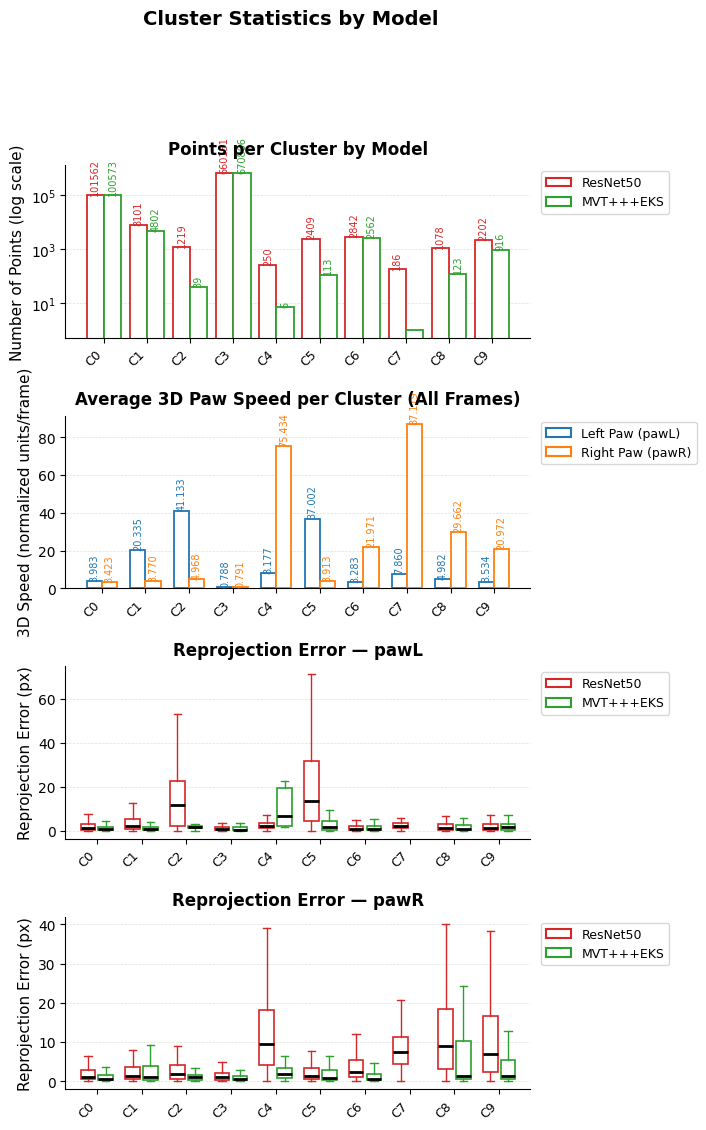

In [39]:
fig_stats, stats_df = plot_cluster_statistics_by_model(
    cluster_labels=labels,
    model_labels=model_labels_clean,
    reproj_errors=reproj_errors,
    session_labels=session_labels_clean,
    valid_mask=valid_mask,
    keypoints=keypoints,
    models_of_interest=models_of_interest,
    model_short_names=model_short_names,
    figsize=(6, 12),
    cluster_names=cluster_names,
    features_clean=features_clean,      # NEW
    feature_names=feature_names,         # NEW
    keypoints_of_interest=['pawL', 'pawR'],
    save_pdf=True,
)

# Trying to get physical units for the 3D speed 

Feature names: ['pawL_vx', 'pawL_vy', 'pawL_vz', 'pawR_vx', 'pawR_vy', 'pawR_vz', 'pawL_speed', 'pawR_speed', 'pawL_acc_mag', 'pawR_acc_mag', 'paw_dist']
test_200_multiview_resnet50_new_labels_ensemble_median: 780000 frames
test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf: 780000 frames

Total pooled: 1560000 frames x 11 features
Valid (non-NaN): 1560000 frames
Raw features shape: (1560000, 11)
Matches cluster labels: True

AVERAGE 3D PAW SPEED PER CLUSTER (mm/s)
 cluster                                              cluster_name  n_frames  pawL_speed_mean_mm_s  pawL_speed_std_mm_s  pawL_speed_median_mm_s  pawR_speed_mean_mm_s  pawR_speed_std_mm_s  pawR_speed_median_mm_s
       0                                      C0_Vertical_Movement    202135              1.025518             1.518768                0.572202              0.883046             1.120813                0.531558
       1  C1_High_Acceleration+Vertical_Movement+Left_Paw_Dominant     12903              5.3

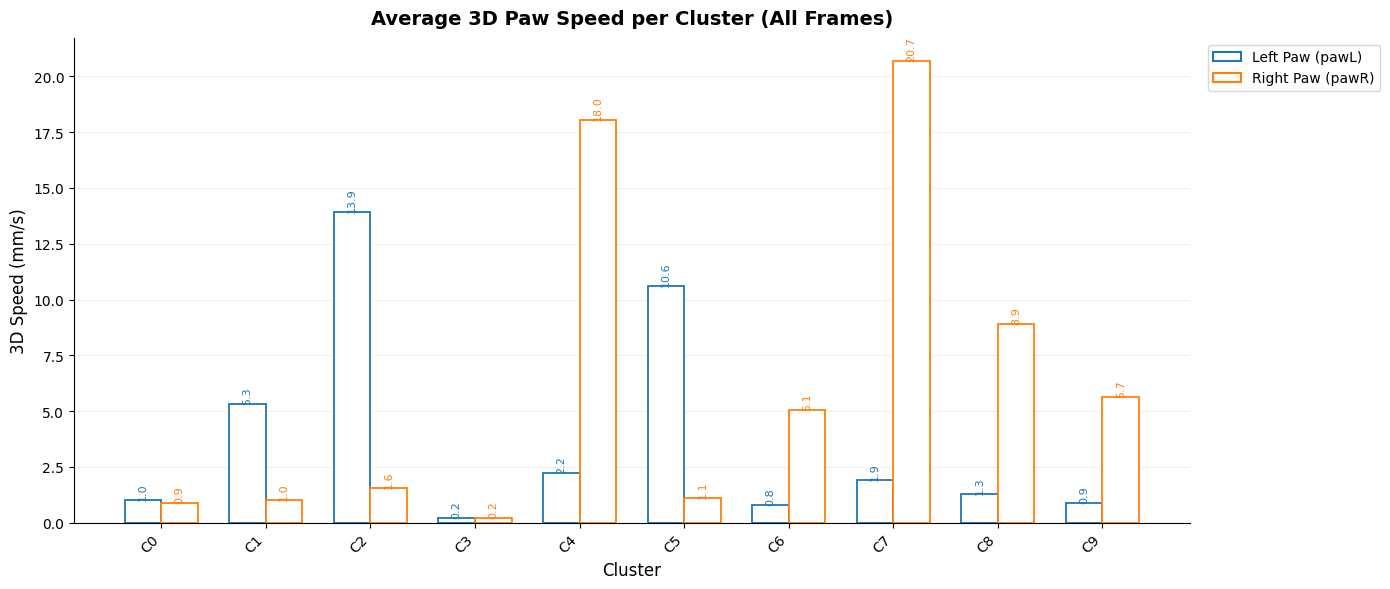

In [40]:
# ============================================================
# STEP 1: Extract features from RAW (non-normalized) 3D data
# ============================================================
from lp3d_analysis.clustering.features import extract_features_all_sessions

# Extract features from raw 3D data (not normalized)
# This gives speeds in mm/s (assuming dt=1/60 for 60fps)
all_features_raw, session_labels_dict_raw, feature_names_raw = extract_features_all_sessions(
    all_3d_data_raw,  # Use raw data, not all_3d_data_norm
    keypoints,
    dt=1.0/60.0  # 60 fps -> speed will be in mm/s
)

print(f"Feature names: {feature_names_raw}")


# ============================================================
# STEP 2: Pool raw features to align with cluster labels
# ============================================================
from lp3d_analysis.clustering.utils import pool_features_all_models_all_sessions

# Pool raw features with same parameters as original clustering
pooled_features_raw, valid_mask_raw, session_labels_raw, model_labels_raw, model_frame_counts_raw = \
    pool_features_all_models_all_sessions(
        all_features_raw, 
        models_of_interest,
        max_frames_per_session=max_frames_per_session,
        subsample_factor=1,
    )

# Apply the same valid mask to get clean features
features_clean_raw = pooled_features_raw[valid_mask_raw]

print(f"Raw features shape: {features_clean_raw.shape}")
print(f"Matches cluster labels: {len(features_clean_raw) == len(labels)}")


# ============================================================
# STEP 3: Compute average paw speed per cluster (physical units)
# ============================================================
def compute_paw_speed_per_cluster_physical(
    cluster_labels: np.ndarray,
    features_clean_raw: np.ndarray,
    feature_names: List[str],
    cluster_names: Dict[int, str] = None,
) -> pd.DataFrame:
    """
    Compute average paw speeds in physical units (mm/s) per cluster.
    
    Args:
        cluster_labels: Cluster assignments
        features_clean_raw: Features extracted from RAW (non-normalized) 3D data
        feature_names: Feature names (must include 'pawL_speed', 'pawR_speed')
        cluster_names: Optional dict mapping cluster ID to name
    
    Returns:
        DataFrame with speed statistics per cluster
    """
    feat_idx = {name: i for i, name in enumerate(feature_names)}
    
    pawL_speed_idx = feat_idx.get('pawL_speed')
    pawR_speed_idx = feat_idx.get('pawR_speed')
    
    if pawL_speed_idx is None or pawR_speed_idx is None:
        raise ValueError(f"Could not find pawL_speed or pawR_speed in feature_names")
    
    pawL_speeds = features_clean_raw[:, pawL_speed_idx]
    pawR_speeds = features_clean_raw[:, pawR_speed_idx]
    
    unique_clusters = np.unique(cluster_labels)
    
    results = []
    for c in unique_clusters:
        mask = cluster_labels == c
        n_frames = np.sum(mask)
        
        pawL_cluster = pawL_speeds[mask]
        pawR_cluster = pawR_speeds[mask]
        
        results.append({
            'cluster': c,
            'cluster_name': cluster_names.get(c, f'C{c}') if cluster_names else f'C{c}',
            'n_frames': n_frames,
            'pawL_speed_mean_mm_s': np.mean(pawL_cluster),
            'pawL_speed_std_mm_s': np.std(pawL_cluster),
            'pawL_speed_median_mm_s': np.median(pawL_cluster),
            'pawR_speed_mean_mm_s': np.mean(pawR_cluster),
            'pawR_speed_std_mm_s': np.std(pawR_cluster),
            'pawR_speed_median_mm_s': np.median(pawR_cluster),
        })
    
    return pd.DataFrame(results)


# Compute speeds in physical units
speed_df = compute_paw_speed_per_cluster_physical(
    cluster_labels=labels,
    features_clean_raw=features_clean_raw,
    feature_names=feature_names_raw,
    cluster_names=cluster_names,
)

print("\n" + "="*80)
print("AVERAGE 3D PAW SPEED PER CLUSTER (mm/s)")
print("="*80)
print(speed_df.to_string(index=False))


# ============================================================
# STEP 4: Plot paw speeds in physical units (mm/s)
# ============================================================
def plot_paw_speed_per_cluster_physical(
    cluster_labels: np.ndarray,
    features_clean_raw: np.ndarray,
    feature_names: List[str],
    cluster_names: Dict[int, str] = None,
    figsize: Tuple[int, int] = (14, 6),
    save_pdf: bool = False,
    pdf_filename: str = "paw_speed_physical.pdf",
):
    """
    Plot average 3D paw speed per cluster in physical units (mm/s).
    Style matches the "Points per Cluster" histogram plot.
    """
    import matplotlib.patches as mpatches
    
    feat_idx = {name: i for i, name in enumerate(feature_names)}
    pawL_speeds = features_clean_raw[:, feat_idx['pawL_speed']]
    pawR_speeds = features_clean_raw[:, feat_idx['pawR_speed']]
    
    unique_clusters = np.unique(cluster_labels)
    n_clusters = len(unique_clusters)
    x = np.arange(n_clusters)
    
    # Compute means per cluster
    pawL_means = []
    pawR_means = []
    for c in unique_clusters:
        mask = cluster_labels == c
        pawL_means.append(np.mean(pawL_speeds[mask]))
        pawR_means.append(np.mean(pawR_speeds[mask]))
    
    # X-axis labels
    xlabels = [cluster_names.get(c, f'C{c}').split('_')[0] if cluster_names else f'C{c}' 
               for c in unique_clusters]
    
    # Colors
    pawL_color = '#1f77b4'  # blue
    pawR_color = '#ff7f0e'  # orange
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    paw_bar_width = 0.35
    
    # Bar plots - white fill, colored edge (matches Points per Cluster style)
    ax.bar(x - paw_bar_width/2, pawL_means, paw_bar_width,
           facecolor='white', edgecolor=pawL_color, linewidth=1.3, alpha=1.0)
    
    ax.bar(x + paw_bar_width/2, pawR_means, paw_bar_width,
           facecolor='white', edgecolor=pawR_color, linewidth=1.3, alpha=1.0)
    
    # Value labels on top of bars (rotated)
    for j, (mean_L, mean_R) in enumerate(zip(pawL_means, pawR_means)):
        ax.text(j - paw_bar_width/2, mean_L, f'{mean_L:.1f}',
               ha='center', va='bottom', fontsize=8,
               rotation=90, color=pawL_color)
        ax.text(j + paw_bar_width/2, mean_R, f'{mean_R:.1f}',
               ha='center', va='bottom', fontsize=8,
               rotation=90, color=pawR_color)
    
    ax.set_ylabel('3D Speed (mm/s)', fontsize=12)
    ax.set_xlabel('Cluster', fontsize=12)
    ax.set_title('Average 3D Paw Speed per Cluster (All Frames)', 
                fontsize=14, fontweight='bold', pad=10)
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
    ax.set_axisbelow(True)
    
    # Legend
    legend_handles = [
        mpatches.Patch(facecolor='white', edgecolor=pawL_color, 
                      linewidth=1.5, label='Left Paw (pawL)'),
        mpatches.Patch(facecolor='white', edgecolor=pawR_color, 
                      linewidth=1.5, label='Right Paw (pawR)'),
    ]
    ax.legend(handles=legend_handles, fontsize=10, frameon=True,
             framealpha=0.9, edgecolor='lightgray',
             bbox_to_anchor=(1.01, 1), loc='upper left')
    
    plt.tight_layout()
    
    # Save PDF
    if save_pdf:
        save_dir = "/teamspace/studios/this_studio/outputs/ibl-mouse/plots/clustering"
        os.makedirs(save_dir, exist_ok=True)
        full_path = os.path.join(save_dir, pdf_filename)
        fig.savefig(full_path, format='pdf', bbox_inches='tight', dpi=300)
        print(f"Saved: {full_path}")
    
    return fig, speed_df


# Plot
fig_speed, speed_df = plot_paw_speed_per_cluster_physical(
    cluster_labels=labels,
    features_clean_raw=features_clean_raw,
    feature_names=feature_names_raw,
    cluster_names=cluster_names,
    save_pdf=True,
    pdf_filename="paw_speed_physical_mm_s.pdf",
)
plt.show()

In [14]:
import umap
from sklearn.preprocessing import StandardScaler
from scipy.ndimage import label, gaussian_filter, maximum_filter, generate_binary_structure
from skimage.segmentation import watershed
import matplotlib.pyplot as plt
import numpy as np

def watershed_clustering_on_umap(embedding, bandwidth=1.0, grid_size=500):
    """
    Density-based clustering on 2D UMAP embedding.
    Uses scipy maximum_filter for local maxima + skimage watershed.
    """
    x_min, x_max = embedding[:, 0].min() - 1, embedding[:, 0].max() + 1
    y_min, y_max = embedding[:, 1].min() - 1, embedding[:, 1].max() + 1
    
    density, x_edges, y_edges = np.histogram2d(
        embedding[:, 0], embedding[:, 1],
        bins=grid_size, range=[[x_min, x_max], [y_min, y_max]]
    )
    density_smooth = gaussian_filter(density, sigma=bandwidth)
    
    min_distance = max(int(bandwidth * 3), 1)
    size = 2 * min_distance + 1
    local_max = (maximum_filter(density_smooth, size=size) == density_smooth)
    local_max &= (density_smooth > density_smooth.max() * 0.01)
    
    struct = generate_binary_structure(2, 2)
    markers, n_markers = label(local_max, structure=struct)
    
    if n_markers == 0:
        cluster_labels = np.ones(len(embedding), dtype=int)
        return cluster_labels, density_smooth, np.ones_like(density_smooth, dtype=int)
    
    labels_grid = watershed(-density_smooth, markers, mask=density_smooth > 0)
    
    x_bins = np.digitize(embedding[:, 0], x_edges[:-1]) - 1
    y_bins = np.digitize(embedding[:, 1], y_edges[:-1]) - 1
    x_bins = np.clip(x_bins, 0, grid_size - 1)
    y_bins = np.clip(y_bins, 0, grid_size - 1)
    
    cluster_labels = labels_grid[x_bins, y_bins]

    return cluster_labels, density_smooth, labels_grid



# K-means Clustering in Feature Space 

ResNet50: 100000 valid frames
MVT+++EKS: 100000 valid frames

Total pooled: 200000 frames x 11 features

Running K-means with 10 clusters in FEATURE SPACE...
K-means clustering complete. Cluster sizes:
  Cluster 0: 4541 points
  Cluster 1: 148370 points
  Cluster 2: 3971 points
  Cluster 3: 145 points
  Cluster 4: 1561 points
  Cluster 5: 3352 points
  Cluster 6: 2397 points
  Cluster 7: 184 points
  Cluster 8: 35149 points
  Cluster 9: 330 points

Running UMAP for visualization (this may take a few minutes)...


/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding shape: (200000, 2)


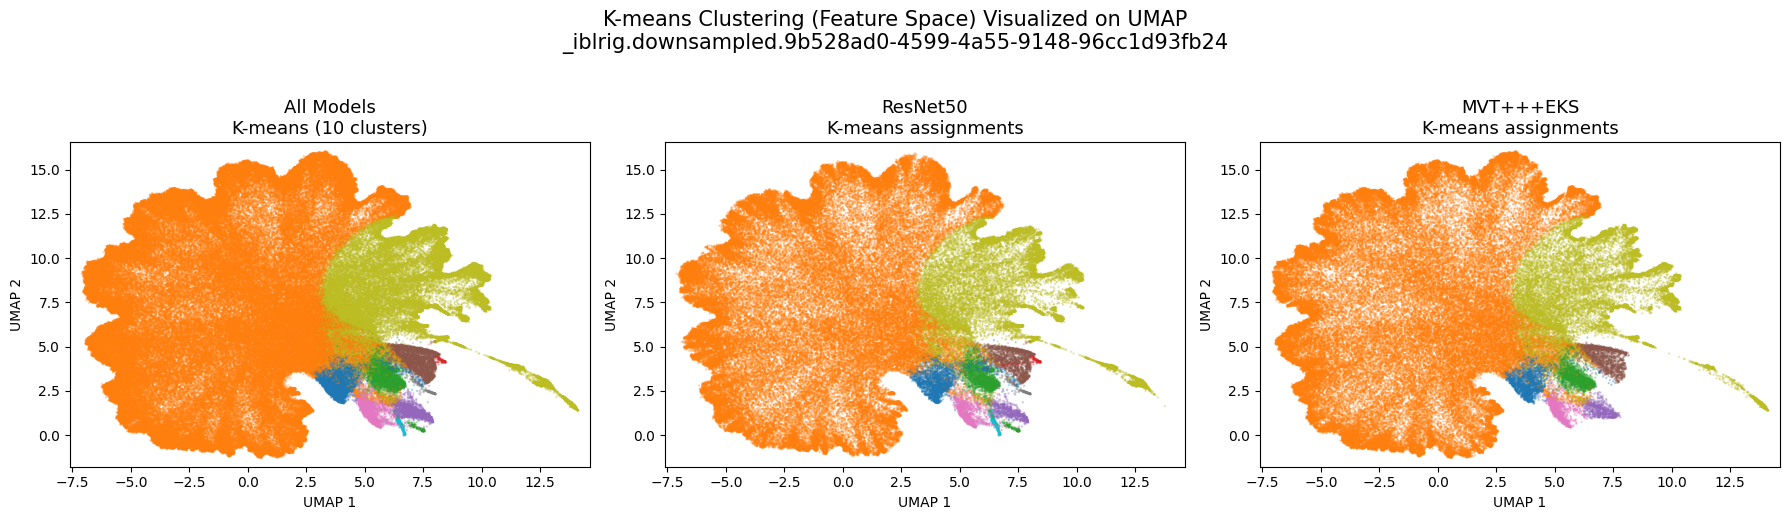

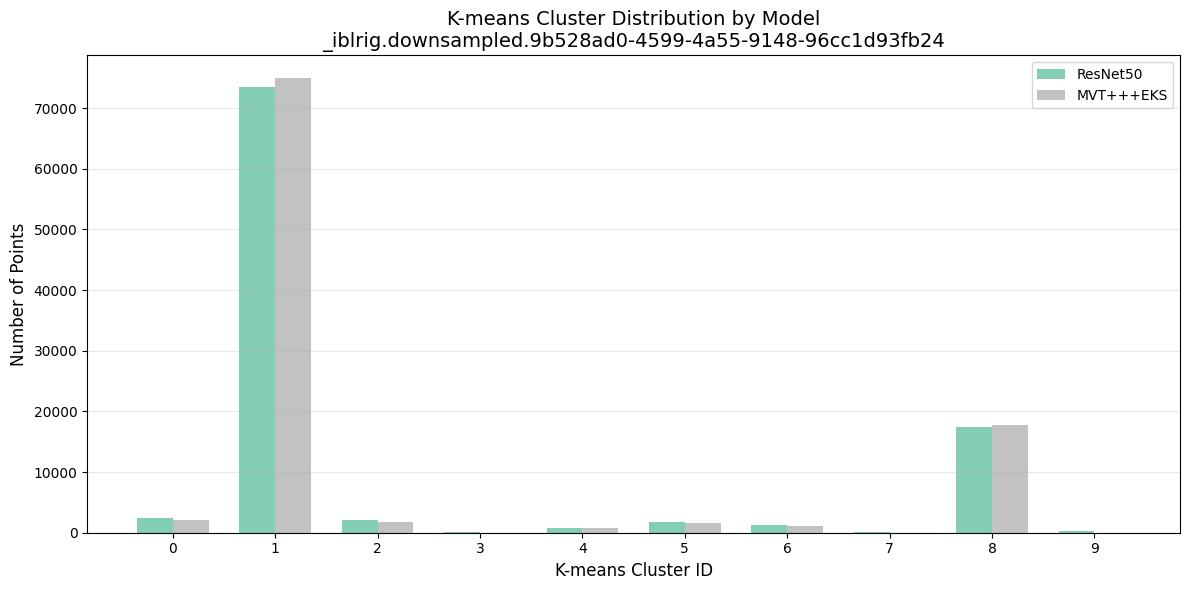


K-MEANS CLUSTER DISTRIBUTION SUMMARY

Cluster 0:
  ResNet50            :   2503 points (  2.5%)
  MVT+++EKS           :   2038 points (  2.0%)

Cluster 1:
  ResNet50            :  73435 points ( 73.4%)
  MVT+++EKS           :  74935 points ( 74.9%)

Cluster 2:
  ResNet50            :   2153 points (  2.2%)
  MVT+++EKS           :   1818 points (  1.8%)

Cluster 3:
  ResNet50            :    145 points (  0.1%)
  MVT+++EKS           :      0 points (  0.0%)

Cluster 4:
  ResNet50            :    817 points (  0.8%)
  MVT+++EKS           :    744 points (  0.7%)

Cluster 5:
  ResNet50            :   1777 points (  1.8%)
  MVT+++EKS           :   1575 points (  1.6%)

Cluster 6:
  ResNet50            :   1222 points (  1.2%)
  MVT+++EKS           :   1175 points (  1.2%)

Cluster 7:
  ResNet50            :    184 points (  0.2%)
  MVT+++EKS           :      0 points (  0.0%)

Cluster 8:
  ResNet50            :  17434 points ( 17.4%)
  MVT+++EKS           :  17715 points ( 17.7%)

Cluster

In [18]:
# ============================================================
# K-MEANS IN FEATURE SPACE, THEN VISUALIZE ON UMAP
# ============================================================

import umap
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

frames_per_model = 100000

# ============================================================
# STEP 1: Pool all features from all models
# ============================================================
pooled_features = []
pooled_model_ids = []
model_frame_counts = {}

for model_name in models_of_interest:
    if model_name not in all_features:
        continue
    feats = all_features[model_name]
    valid_mask = ~np.any(np.isnan(feats), axis=1)
    feats_clean = feats[valid_mask][:frames_per_model]
    
    pooled_features.append(feats_clean)
    pooled_model_ids.extend([model_name] * len(feats_clean))
    model_frame_counts[model_name] = len(feats_clean)
    print(f"{model_short_names[model_name]}: {len(feats_clean)} valid frames")

pooled_features = np.concatenate(pooled_features, axis=0)
pooled_model_ids = np.array(pooled_model_ids)
print(f"\nTotal pooled: {pooled_features.shape[0]} frames x {pooled_features.shape[1]} features")

# ============================================================
# STEP 2: Standardize features
# ============================================================
scaler = StandardScaler()
pooled_scaled = scaler.fit_transform(pooled_features)

# ============================================================
# STEP 3: K-MEANS CLUSTERING IN FEATURE SPACE
# ============================================================
n_kmeans_clusters = 10  # adjust as needed

print(f"\nRunning K-means with {n_kmeans_clusters} clusters in FEATURE SPACE...")
kmeans = KMeans(n_clusters=n_kmeans_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(pooled_scaled)

print(f"K-means clustering complete. Cluster sizes:")
for c in range(n_kmeans_clusters):
    print(f"  Cluster {c}: {np.sum(kmeans_labels == c)} points")

# ============================================================
# STEP 4: RUN UMAP FOR VISUALIZATION ONLY
# ============================================================
print("\nRunning UMAP for visualization (this may take a few minutes)...")
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=199,
    min_dist=0.3,
    random_state=42,
)
pooled_embedding = reducer.fit_transform(pooled_scaled)
print(f"UMAP embedding shape: {pooled_embedding.shape}")

# ============================================================
# STEP 5: Split labels and embeddings back to each model
# ============================================================
kmeans_labels_by_model = {}
embeddings_by_model = {}
offset = 0

for model_name in models_of_interest:
    if model_name not in model_frame_counts:
        continue
    n = model_frame_counts[model_name]
    kmeans_labels_by_model[model_name] = kmeans_labels[offset:offset + n]
    embeddings_by_model[model_name] = pooled_embedding[offset:offset + n]
    offset += n

# ============================================================
# STEP 6: Axis limits for consistent plots
# ============================================================
x_lim = (pooled_embedding[:, 0].min() - 0.5, pooled_embedding[:, 0].max() + 0.5)
y_lim = (pooled_embedding[:, 1].min() - 0.5, pooled_embedding[:, 1].max() + 0.5)

# ============================================================
# STEP 7: VISUALIZE K-MEANS CLUSTERS ON UMAP
# ============================================================
fig, axes = plt.subplots(1, len(models_of_interest) + 1, figsize=(6*(len(models_of_interest)+1), 5))

cmap = plt.cm.tab10 if n_kmeans_clusters <= 10 else plt.cm.tab20

# First plot: All models together
ax = axes[0]
scatter = ax.scatter(pooled_embedding[:, 0], pooled_embedding[:, 1],
                    c=kmeans_labels, cmap=cmap, s=0.5, alpha=0.3,
                    vmin=0, vmax=n_kmeans_clusters-1)
ax.set_title(f'All Models\nK-means ({n_kmeans_clusters} clusters)', fontsize=13)
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_xlim(x_lim)
ax.set_ylim(y_lim)

# Per-model plots
for idx, model_name in enumerate(models_of_interest):
    ax = axes[idx + 1]
    if model_name not in embeddings_by_model:
        ax.set_title(f"{model_short_names[model_name]}\n(no data)")
        continue
    
    embedding = embeddings_by_model[model_name]
    labels = kmeans_labels_by_model[model_name]
    
    ax.scatter(embedding[:, 0], embedding[:, 1],
              c=labels, cmap=cmap, s=0.5, alpha=0.3,
              vmin=0, vmax=n_kmeans_clusters-1)
    ax.set_title(f"{model_short_names[model_name]}\nK-means assignments", fontsize=13)
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_xlim(x_lim)
    ax.set_ylim(y_lim)

fig.suptitle(f'K-means Clustering (Feature Space) Visualized on UMAP\n{target_session}', fontsize=15, y=1.03)
fig.tight_layout()
plt.show()

# ============================================================
# STEP 8: BAR PLOT - Cluster distribution per model
# ============================================================
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(n_kmeans_clusters)
bar_width = 0.35
model_names_plot = [m for m in models_of_interest if m in kmeans_labels_by_model]
colors = plt.cm.Set2(np.linspace(0, 1, len(model_names_plot)))

for i, model_name in enumerate(model_names_plot):
    labels = kmeans_labels_by_model[model_name]
    counts = [np.sum(labels == c) for c in range(n_kmeans_clusters)]
    offset_bar = (i - len(model_names_plot)/2 + 0.5) * bar_width
    ax.bar(x + offset_bar, counts, bar_width, 
           label=model_short_names[model_name], color=colors[i], alpha=0.8)

ax.set_xlabel('K-means Cluster ID', fontsize=12)
ax.set_ylabel('Number of Points', fontsize=12)
ax.set_title(f'K-means Cluster Distribution by Model\n{target_session}', fontsize=14)
ax.set_xticks(x)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# STEP 9: Print summary
# ============================================================
print("\n" + "="*70)
print("K-MEANS CLUSTER DISTRIBUTION SUMMARY")
print("="*70)
for c in range(n_kmeans_clusters):
    print(f"\nCluster {c}:")
    for model_name in model_names_plot:
        labels = kmeans_labels_by_model[model_name]
        n_pts = np.sum(labels == c)
        pct = 100 * n_pts / model_frame_counts[model_name]
        print(f"  {model_short_names[model_name]:20s}: {n_pts:6d} points ({pct:5.1f}%)")

1. Watershed clustering once on pooled embedding
2. Shared cluster IDs across models
3. Bar plot of mean reproj error per cluster per model
4. Bar plot of points per cluster per model

In [19]:
import umap
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.ndimage import label, gaussian_filter, maximum_filter, generate_binary_structure
from skimage.segmentation import watershed
import matplotlib.pyplot as plt
import numpy as np

We run this only if we didn't run the clustering above

In [20]:
# # ============================================================
# # POOLED UMAP: fit ONE UMAP on all models' features together
# # SHARED CLUSTERING: run watershed ONCE on the entire pooled embedding
# # ============================================================

# frames_per_model = 100000

# # 1. Pool all features (remove NaN rows per model)
# pooled_features = []
# pooled_model_ids = []
# model_frame_counts = {}

# for model_name in models_of_interest:
#     if model_name not in all_features:
#         continue
#     feats = all_features[model_name]
#     valid_mask = ~np.any(np.isnan(feats), axis=1)
#     feats_clean = feats[valid_mask]
    
#     # Take only first N frames per model
#     feats_clean = feats_clean[:frames_per_model]
    
#     pooled_features.append(feats_clean)
#     pooled_model_ids.extend([model_name] * len(feats_clean))
#     model_frame_counts[model_name] = len(feats_clean)
#     print(f"{model_short_names[model_name]}: {len(feats_clean)} valid frames")

# pooled_features = np.concatenate(pooled_features, axis=0)
# pooled_model_ids = np.array(pooled_model_ids)
# print(f"\nTotal pooled: {pooled_features.shape[0]} frames x {pooled_features.shape[1]} features")

# # 2. Standardize the entire pool together
# scaler = StandardScaler()
# pooled_scaled = scaler.fit_transform(pooled_features)

# # 3. Run ONE UMAP on the entire pool
# print("Running UMAP on pooled data...")
# reducer = umap.UMAP(
#     n_components=2,
#     n_neighbors=199,
#     min_dist=0.3,
#     random_state=42,
# )
# pooled_embedding = reducer.fit_transform(pooled_scaled)
# print(f"UMAP embedding shape: {pooled_embedding.shape}")

In [31]:
# 4. Run SHARED watershed clustering on the ENTIRE pooled embedding
print("\nRunning SHARED watershed clustering on pooled embedding...")
shared_cluster_labels, shared_density, shared_labels_grid = watershed_clustering_on_umap(
    pooled_embedding, bandwidth=13.0, grid_size=500 # was 14 but need to decrease , used 13 for 15763
)
n_shared_clusters = len(np.unique(shared_cluster_labels[shared_cluster_labels > 0]))
print(f"Shared clustering: {n_shared_clusters} clusters across all models")

# 5. Split the embedding AND cluster labels back by model
umap_results = {}
cluster_labels_by_model = {}
offset = 0
for model_name in models_of_interest:
    if model_name not in model_frame_counts:
        continue
    n = model_frame_counts[model_name]
    umap_results[model_name] = {
        'embedding': pooled_embedding[offset:offset + n],
        'features_clean': pooled_features[offset:offset + n],
    }
    cluster_labels_by_model[model_name] = shared_cluster_labels[offset:offset + n]
    umap_results[model_name]['cluster_labels'] = cluster_labels_by_model[model_name]
    
    n_points = np.sum(cluster_labels_by_model[model_name] > 0)
    print(f"{model_short_names[model_name]}: {n_points} points assigned to clusters")
    offset += n

# 6. Shared axis limits for all plots
x_lim = (pooled_embedding[:, 0].min() - 0.5, pooled_embedding[:, 0].max() + 0.5)
y_lim = (pooled_embedding[:, 1].min() - 0.5, pooled_embedding[:, 1].max() + 0.5)


Running SHARED watershed clustering on pooled embedding...
Shared clustering: 11 clusters across all models
ResNet50: 100000 points assigned to clusters
MVT+++EKS: 100000 points assigned to clusters


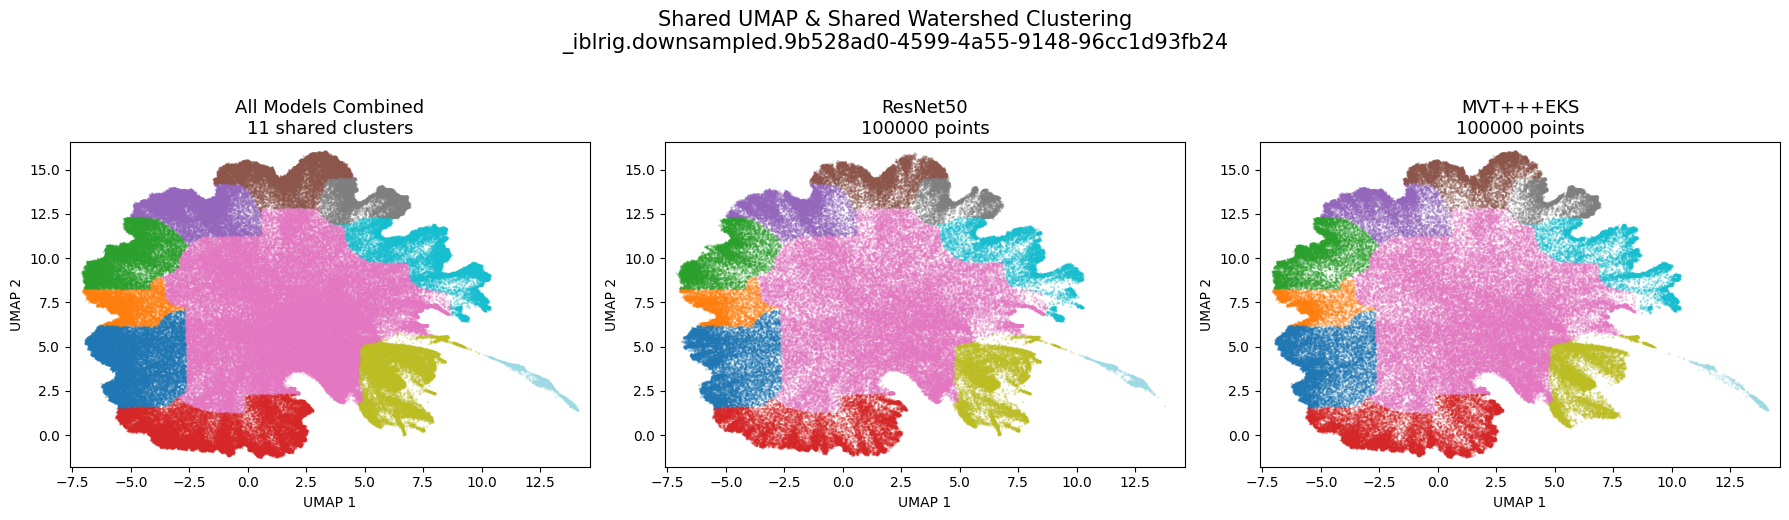

In [32]:
# ============================================================
# VISUALIZATION: Shared clusters split by model (same cluster = same color)
# ============================================================

unique_clusters = np.unique(shared_cluster_labels[shared_cluster_labels > 0])
n_clusters = len(unique_clusters)

fig, axes = plt.subplots(1, len(models_of_interest) + 1, figsize=(6*(len(models_of_interest)+1), 5))

# Use consistent colormap for all models
cmap = plt.cm.tab20 if n_clusters > 10 else plt.cm.tab10

# First plot: All models together
ax = axes[0]
scatter = ax.scatter(pooled_embedding[:, 0], pooled_embedding[:, 1],
                    c=shared_cluster_labels, cmap=cmap, s=0.5, alpha=0.3,
                    vmin=unique_clusters.min() if len(unique_clusters) > 0 else 0, 
                    vmax=unique_clusters.max() if len(unique_clusters) > 0 else 1)
ax.set_title(f'All Models Combined\n{n_clusters} shared clusters', fontsize=13)
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_xlim(x_lim)
ax.set_ylim(y_lim)

# Per-model plots
for idx, model_name in enumerate(models_of_interest):
    ax = axes[idx + 1]
    if model_name not in umap_results:
        ax.set_title(f"{model_short_names[model_name]}\n(no data)")
        continue
    
    res = umap_results[model_name]
    embedding = res['embedding']
    cluster_labels = res['cluster_labels']
    
    ax.scatter(embedding[:, 0], embedding[:, 1],
               c=cluster_labels, cmap=cmap, s=0.5, alpha=0.3,
               vmin=unique_clusters.min() if len(unique_clusters) > 0 else 0, 
               vmax=unique_clusters.max() if len(unique_clusters) > 0 else 1)
    ax.set_title(f"{model_short_names[model_name]}\n{np.sum(cluster_labels > 0)} points", fontsize=13)
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_xlim(x_lim)
    ax.set_ylim(y_lim)

fig.suptitle(f'Shared UMAP & Shared Watershed Clustering\n{target_session}', fontsize=15, y=1.03)
fig.tight_layout()
plt.show()

In [33]:
# ============================================================
# REPROJECTION ERROR: compare reprojected 2D vs original 2D
# ============================================================

def compute_reprojection_error_vs_original(
    points_3d, 
    original_2d_by_view,  # dict: view -> {'x': (T, K), 'y': (T, K)}
    camera_group, 
    views,
    keypoints,
):
    """
    Compute reprojection error by comparing:
    - 3D points reprojected to each view
    - Original 2D predictions for that view
    
    Returns: (T, K, n_views) array of per-keypoint, per-view errors in pixels
    """
    T, K, _ = points_3d.shape
    n_views = len(views)
    
    reproj_errors = np.full((T, K, n_views), np.nan)
    
    for v_idx, view in enumerate(views):
        # Get camera for this view
        cam_names = [c.name for c in camera_group.cameras]
        if view not in cam_names:
            print(f"  Warning: view {view} not in camera group")
            continue
        cam_idx = cam_names.index(view)
        camera = camera_group.cameras[cam_idx]
        
        # Reproject 3D -> 2D for this view
        pts_3d_flat = points_3d.reshape(-1, 3)  # (T*K, 3)
        pts_2d_reproj = camera.project(pts_3d_flat)  # (T*K, 2)
        pts_2d_reproj = pts_2d_reproj.reshape(T, K, 2)  # (T, K, 2)
        
        # Get original 2D predictions
        orig_x = original_2d_by_view[view]['x']  # (T, K)
        orig_y = original_2d_by_view[view]['y']  # (T, K)
        
        # Compute Euclidean distance
        dx = pts_2d_reproj[:, :, 0] - orig_x
        dy = pts_2d_reproj[:, :, 1] - orig_y
        error = np.sqrt(dx**2 + dy**2)  # (T, K)
        
        reproj_errors[:, :, v_idx] = error
    
    return reproj_errors

In [34]:
# ============================================================
# Load original 2D predictions for each model
# ============================================================

original_2d_sources = {
    'test_200_multiview_resnet50_new_labels_ensemble_median': 
        'test_200_multiview_resnet50_new_labels_ensemble_median',
    # 'test_200_multiview_resnet50_new_labels_ensemble_median_anipose': 
    #     'test_200_multiview_resnet50_new_labels_ensemble_median',
    'test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf': 
        'test_200_MVT_3d_aug_patch_masking_new_labels_eks_multiview_varinf',
}

original_2d_data = {}

for model_name in models_of_interest:
    source_model = original_2d_sources.get(model_name, model_name)
    
    if source_model in original_2d_data:
        original_2d_data[model_name] = original_2d_data[source_model]
        continue
    
    original_2d_data[model_name] = {}
    
    session_data = all_file_paths.get(target_session, {})
    
    for view in views:
        if view not in session_data:
            continue
        if source_model not in session_data[view]:
            print(f"  Warning: {source_model} not found for {view}")
            continue
        
        csv_path = session_data[view][source_model]
        
        if 'reprojected' in csv_path:
            csv_path = csv_path.replace('videos_new_reprojected', 'videos_new')
        
        pred = load_2d_predictions(csv_path, keypoints)
        original_2d_data[model_name][view] = {
            'x': pred['x'],
            'y': pred['y'],
            'likelihood': pred['likelihood'],
        }
    
    print(f"Loaded original 2D for {model_short_names[model_name]}")

Loaded original 2D for ResNet50
Loaded original 2D for MVT+++EKS


In [35]:
# ============================================================
# Compute reprojection error for each model
# ============================================================

reproj_errors_all = {}  # model -> (T, K, n_views) array

for model_name in models_of_interest:
    if model_name not in all_3d_data:
        continue
    if target_session not in all_3d_data[model_name]:
        continue
    
    points_3d = all_3d_data[model_name][target_session]
    T = points_3d.shape[0]
    
    orig_2d = original_2d_data.get(model_name, {})
    if len(orig_2d) < 2:
        print(f"  Skipping {model_short_names[model_name]}: missing original 2D")
        continue
    
    min_T = min(T, orig_2d[views[0]]['x'].shape[0])
    points_3d_trimmed = points_3d[:min_T]
    orig_2d_trimmed = {}
    for v in views:
        orig_2d_trimmed[v] = {
            'x': orig_2d[v]['x'][:min_T],
            'y': orig_2d[v]['y'][:min_T],
        }
    
    calib_file = None
    for f in os.listdir(camera_params_dir):
        if target_session.replace('_iblrig.downsampled.', '').replace('_iblrig_.downsampled.', '') in f:
            calib_file = os.path.join(camera_params_dir, f)
            break
    
    if calib_file is None:
        print(f"  No calibration file for {target_session}")
        continue
    
    camera_group = CameraGroup.load(calib_file)
    
    print(f"\nComputing reprojection error for {model_short_names[model_name]}...")
    errors = compute_reprojection_error_vs_original(
        points_3d_trimmed, orig_2d_trimmed, camera_group, views, keypoints
    )
    reproj_errors_all[model_name] = errors
    
    valid = ~np.isnan(errors)
    if valid.any():
        print(f"  Mean reproj error: {np.nanmean(errors):.2f} px")
        print(f"  95th percentile: {np.nanpercentile(errors, 95):.2f} px")


Computing reprojection error for ResNet50...
  Mean reproj error: 0.78 px
  95th percentile: 2.20 px

Computing reprojection error for MVT+++EKS...
  Mean reproj error: 0.53 px
  95th percentile: 1.39 px


In [36]:
# ============================================================
# Per-frame mean reprojection error (average across keypoints and views)
# ============================================================

reproj_per_frame = {}

for model_name in reproj_errors_all:
    errors = reproj_errors_all[model_name]  # (T, K, n_views)
    mean_error = np.nanmean(errors, axis=(1, 2))  # (T,)
    reproj_per_frame[model_name] = mean_error
    
    print(f"{model_short_names[model_name]}: mean={np.nanmean(mean_error):.2f} px, "
          f"median={np.nanmedian(mean_error):.2f} px, "
          f"95th={np.nanpercentile(mean_error, 95):.2f} px")

ResNet50: mean=0.78 px, median=0.60 px, 95th=1.47 px
MVT+++EKS: mean=0.53 px, median=0.53 px, 95th=0.79 px


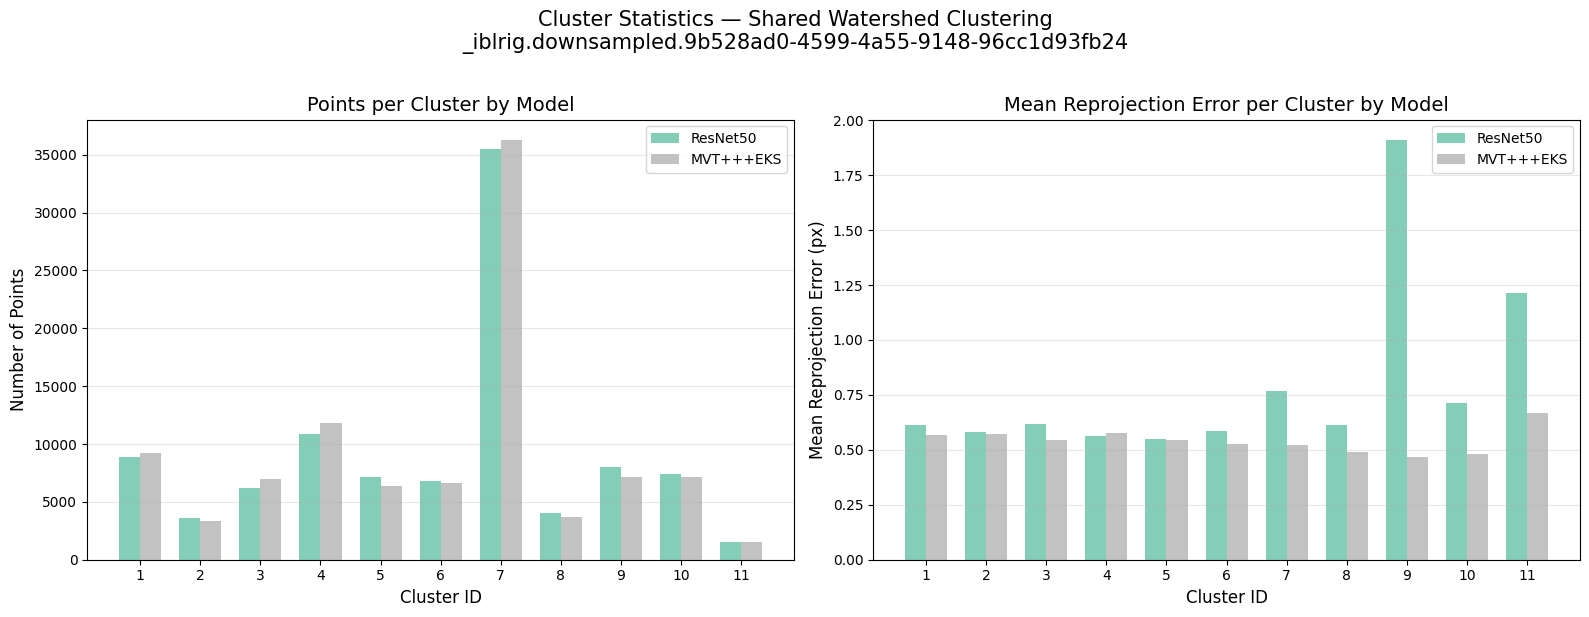

In [37]:
# ============================================================
# BAR PLOTS: Points per cluster & Reprojection error per cluster
# ============================================================

unique_clusters = np.unique(shared_cluster_labels[shared_cluster_labels > 0])
n_clusters = len(unique_clusters)

# Compute points per cluster per model
points_per_cluster = {model_name: [] for model_name in models_of_interest if model_name in cluster_labels_by_model}
for model_name in points_per_cluster:
    labels = cluster_labels_by_model[model_name]
    for c in unique_clusters:
        points_per_cluster[model_name].append(np.sum(labels == c))

# Compute mean reprojection error per cluster per model
reproj_per_cluster = {model_name: [] for model_name in models_of_interest if model_name in reproj_per_frame}

for model_name in reproj_per_cluster:
    if model_name not in cluster_labels_by_model:
        continue
    
    labels = cluster_labels_by_model[model_name]
    
    reproj = reproj_per_frame.get(model_name, None)
    if reproj is None:
        reproj_per_cluster[model_name] = [np.nan] * n_clusters
        continue
    
    # Align reprojection errors with clustering frames
    feats = all_features[model_name]
    valid_mask = ~np.any(np.isnan(feats), axis=1)
    valid_indices = np.where(valid_mask)[0][:frames_per_model]
    
    # Trim reprojection to match
    reproj_aligned = reproj[valid_indices] if len(valid_indices) <= len(reproj) else reproj[:len(valid_indices)]
    
    # Ensure same length
    min_len = min(len(labels), len(reproj_aligned))
    labels_trimmed = labels[:min_len]
    reproj_trimmed = reproj_aligned[:min_len]
    
    for c in unique_clusters:
        mask = labels_trimmed == c
        if mask.any():
            reproj_per_cluster[model_name].append(np.nanmean(reproj_trimmed[mask]))
        else:
            reproj_per_cluster[model_name].append(np.nan)

# Create bar plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar width and positions
bar_width = 0.35
x = np.arange(n_clusters)
model_names_plot = [m for m in models_of_interest if m in points_per_cluster]
colors = plt.cm.Set2(np.linspace(0, 1, len(model_names_plot)))

# Plot 1: Points per cluster
ax1 = axes[0]
for i, model_name in enumerate(model_names_plot):
    offset = (i - len(model_names_plot)/2 + 0.5) * bar_width
    ax1.bar(x + offset, points_per_cluster[model_name], bar_width, 
            label=model_short_names[model_name], color=colors[i], alpha=0.8)

ax1.set_xlabel('Cluster ID', fontsize=12)
ax1.set_ylabel('Number of Points', fontsize=12)
ax1.set_title('Points per Cluster by Model', fontsize=14)
ax1.set_xticks(x)
ax1.set_xticklabels([str(c) for c in unique_clusters])
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Reprojection error per cluster
ax2 = axes[1]
for i, model_name in enumerate(model_names_plot):
    if model_name not in reproj_per_cluster:
        continue
    offset = (i - len(model_names_plot)/2 + 0.5) * bar_width
    ax2.bar(x + offset, reproj_per_cluster[model_name], bar_width,
            label=model_short_names[model_name], color=colors[i], alpha=0.8)

ax2.set_xlabel('Cluster ID', fontsize=12)
ax2.set_ylabel('Mean Reprojection Error (px)', fontsize=12)
ax2.set_title('Mean Reprojection Error per Cluster by Model', fontsize=14)
ax2.set_xticks(x)
ax2.set_xticklabels([str(c) for c in unique_clusters])
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.3)

fig.suptitle(f'Cluster Statistics — Shared Watershed Clustering\n{target_session}', fontsize=15, y=1.02)
fig.tight_layout()
plt.show()

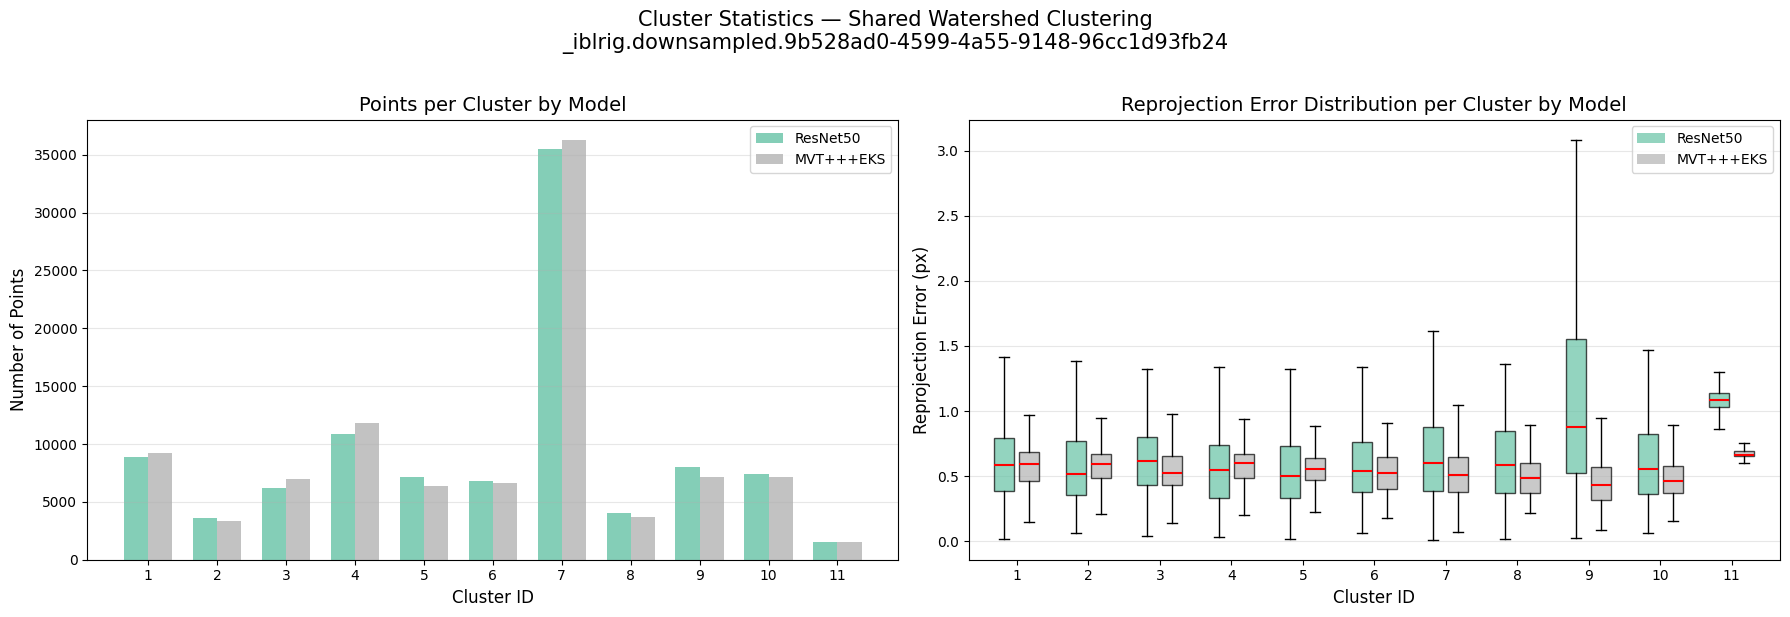

In [38]:
# ============================================================
# BAR PLOT for Points + BOX-WHISKER PLOT for Reprojection Error
# ============================================================

unique_clusters = np.unique(shared_cluster_labels[shared_cluster_labels > 0])
n_clusters = len(unique_clusters)

# Compute points per cluster per model
points_per_cluster = {model_name: [] for model_name in models_of_interest if model_name in cluster_labels_by_model}
for model_name in points_per_cluster:
    labels = cluster_labels_by_model[model_name]
    for c in unique_clusters:
        points_per_cluster[model_name].append(np.sum(labels == c))

# Collect reprojection errors per cluster per model (keep all values, not just mean)
reproj_per_cluster_all = {model_name: {} for model_name in models_of_interest if model_name in reproj_per_frame}

for model_name in reproj_per_cluster_all:
    if model_name not in cluster_labels_by_model:
        continue
    
    labels = cluster_labels_by_model[model_name]
    
    reproj = reproj_per_frame.get(model_name, None)
    if reproj is None:
        continue
    
    # Align reprojection errors with clustering frames
    feats = all_features[model_name]
    valid_mask = ~np.any(np.isnan(feats), axis=1)
    valid_indices = np.where(valid_mask)[0][:frames_per_model]
    
    # Trim reprojection to match
    reproj_aligned = reproj[valid_indices] if len(valid_indices) <= len(reproj) else reproj[:len(valid_indices)]
    
    # Ensure same length
    min_len = min(len(labels), len(reproj_aligned))
    labels_trimmed = labels[:min_len]
    reproj_trimmed = reproj_aligned[:min_len]
    
    # Store ALL reprojection values per cluster (not just mean)
    for c in unique_clusters:
        mask = labels_trimmed == c
        if mask.any():
            reproj_values = reproj_trimmed[mask]
            reproj_values = reproj_values[~np.isnan(reproj_values)]  # remove NaNs
            reproj_per_cluster_all[model_name][c] = reproj_values
        else:
            reproj_per_cluster_all[model_name][c] = np.array([])

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Bar width and positions
bar_width = 0.35
x = np.arange(n_clusters)
model_names_plot = [m for m in models_of_interest if m in points_per_cluster]
colors = plt.cm.Set2(np.linspace(0, 1, len(model_names_plot)))

# ============================================================
# Plot 1: Points per cluster (BAR PLOT - same as before)
# ============================================================
ax1 = axes[0]
for i, model_name in enumerate(model_names_plot):
    offset = (i - len(model_names_plot)/2 + 0.5) * bar_width
    ax1.bar(x + offset, points_per_cluster[model_name], bar_width, 
            label=model_short_names[model_name], color=colors[i], alpha=0.8)

ax1.set_xlabel('Cluster ID', fontsize=12)
ax1.set_ylabel('Number of Points', fontsize=12)
ax1.set_title('Points per Cluster by Model', fontsize=14)
ax1.set_xticks(x)
ax1.set_xticklabels([str(c) for c in unique_clusters])
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

# ============================================================
# Plot 2: Reprojection error per cluster (BOX-WHISKER PLOT)
# ============================================================
ax2 = axes[1]

# Prepare data for box plot
box_width = 0.35
positions_all = []
data_all = []
colors_all = []
labels_for_legend = []

for i, model_name in enumerate(model_names_plot):
    if model_name not in reproj_per_cluster_all:
        continue
    
    for j, c in enumerate(unique_clusters):
        if c in reproj_per_cluster_all[model_name] and len(reproj_per_cluster_all[model_name][c]) > 0:
            data_all.append(reproj_per_cluster_all[model_name][c])
            # Position: cluster index + offset for each model
            offset = (i - len(model_names_plot)/2 + 0.5) * box_width
            positions_all.append(j + offset)
            colors_all.append(colors[i])

# Create box plot
bp = ax2.boxplot(data_all, positions=positions_all, widths=box_width*0.8,
                  patch_artist=True, showfliers=False)  # showfliers=False to hide outliers

# Color the boxes
for patch, color in zip(bp['boxes'], colors_all):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Style the other elements
for element in ['whiskers', 'caps', 'medians']:
    plt.setp(bp[element], color='black', linewidth=1)
plt.setp(bp['medians'], color='red', linewidth=1.5)

# Add legend manually
legend_patches = [plt.Rectangle((0,0),1,1, facecolor=colors[i], alpha=0.7, 
                                  label=model_short_names[m]) 
                  for i, m in enumerate(model_names_plot) if m in reproj_per_cluster_all]
ax2.legend(handles=legend_patches, fontsize=10)

ax2.set_xlabel('Cluster ID', fontsize=12)
ax2.set_ylabel('Reprojection Error (px)', fontsize=12)
ax2.set_title('Reprojection Error Distribution per Cluster by Model', fontsize=14)
ax2.set_xticks(x)
ax2.set_xticklabels([str(c) for c in unique_clusters])
ax2.grid(axis='y', alpha=0.3)

fig.suptitle(f'Cluster Statistics — Shared Watershed Clustering\n{target_session}', fontsize=15, y=1.02)
fig.tight_layout()
plt.show()

In [80]:
# ============================================================
# SUMMARY TABLE: Cluster statistics per model
# ============================================================

print("\n" + "="*80)
print("CLUSTER STATISTICS SUMMARY")
print("="*80)

for c_idx, c in enumerate(unique_clusters):
    print(f"\nCluster {c}:")
    for model_name in model_names_plot:
        n_pts = points_per_cluster[model_name][c_idx]
        reproj = reproj_per_cluster[model_name][c_idx] if model_name in reproj_per_cluster else np.nan
        pct = 100 * n_pts / model_frame_counts[model_name]
        print(f"  {model_short_names[model_name]:20s}: {n_pts:6d} points ({pct:5.1f}%), reproj error = {reproj:.2f} px")


CLUSTER STATISTICS SUMMARY

Cluster 1:
  ResNet50            :  13563 points ( 13.6%), reproj error = 0.48 px
  MVT+++EKS           :  12356 points ( 12.4%), reproj error = 0.43 px

Cluster 2:
  ResNet50            :   9591 points (  9.6%), reproj error = 0.51 px
  MVT+++EKS           :  10297 points ( 10.3%), reproj error = 0.41 px

Cluster 3:
  ResNet50            :   4311 points (  4.3%), reproj error = 0.66 px
  MVT+++EKS           :   3660 points (  3.7%), reproj error = 0.66 px

Cluster 4:
  ResNet50            :   5041 points (  5.0%), reproj error = 0.56 px
  MVT+++EKS           :   4122 points (  4.1%), reproj error = 0.42 px

Cluster 5:
  ResNet50            :   5465 points (  5.5%), reproj error = 1.89 px
  MVT+++EKS           :   4615 points (  4.6%), reproj error = 0.91 px

Cluster 6:
  ResNet50            :  18899 points ( 18.9%), reproj error = 0.94 px
  MVT+++EKS           :  19031 points ( 19.0%), reproj error = 0.64 px

Cluster 7:
  ResNet50            :  20239 point

In [81]:
# ============================================================
# ANALYZE CLUSTERS 6-10: Extract frame numbers and understand behaviors
# ============================================================

clusters_of_interest = [6, 7, 8, 9, 10,11,12,13,14,15]

# Store frame indices per cluster per model
frames_per_cluster = {}

for model_name in models_of_interest:
    if model_name not in cluster_labels_by_model:
        continue
    
    labels = cluster_labels_by_model[model_name]
    frames_per_cluster[model_name] = {}
    
    print(f"\n{'='*60}")
    print(f"{model_short_names[model_name]}")
    print(f"{'='*60}")
    
    for c in clusters_of_interest:
        # Get frame indices where cluster == c
        frame_indices = np.where(labels == c)[0]
        frames_per_cluster[model_name][c] = frame_indices
        
        print(f"\nCluster {c}: {len(frame_indices)} frames")
        if len(frame_indices) > 0:
            print(f"  First 20 frames: {frame_indices[:20].tolist()}")
            print(f"  Last 20 frames:  {frame_indices[-20:].tolist()}")


ResNet50

Cluster 6: 18899 frames
  First 20 frames: [3, 4, 5, 6, 7, 8, 10, 15, 19, 20, 51, 65, 67, 84, 111, 112, 113, 114, 115, 116]
  Last 20 frames:  [99796, 99797, 99801, 99802, 99855, 99858, 99859, 99860, 99861, 99862, 99864, 99907, 99947, 99949, 99950, 99958, 99959, 99960, 99961, 99966]

Cluster 7: 20239 frames
  First 20 frames: [1, 2, 11, 12, 14, 16, 17, 18, 24, 26, 27, 28, 29, 30, 34, 35, 36, 37, 38, 39]
  Last 20 frames:  [99931, 99937, 99938, 99939, 99940, 99941, 99942, 99943, 99944, 99946, 99948, 99951, 99952, 99953, 99954, 99955, 99956, 99957, 99964, 99965]

Cluster 8: 9690 frames
  First 20 frames: [139, 165, 166, 336, 348, 361, 398, 402, 528, 572, 781, 784, 785, 786, 787, 788, 789, 790, 791, 792]
  Last 20 frames:  [99469, 99470, 99471, 99472, 99473, 99474, 99475, 99476, 99477, 99478, 99479, 99480, 99481, 99482, 99483, 99484, 99485, 99486, 99487, 99488]

Cluster 9: 2611 frames
  First 20 frames: [221, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240,

In [82]:
# ============================================================
# BEHAVIORAL ANALYSIS: What do clusters 6-10 represent?
# ============================================================

# Get the features for frames in each cluster
print("\n" + "="*80)
print("BEHAVIORAL PROFILE FOR CLUSTERS OF INTEREST")
print("="*80)

for model_name in models_of_interest:
    if model_name not in cluster_labels_by_model:
        continue
    
    labels = cluster_labels_by_model[model_name]
    
    # Get the features used for clustering (aligned with labels)
    feats = all_features[model_name]
    valid_mask = ~np.any(np.isnan(feats), axis=1)
    valid_indices = np.where(valid_mask)[0][:frames_per_model]
    feats_clean = feats[valid_indices]
    
    # Ensure same length
    min_len = min(len(labels), len(feats_clean))
    labels = labels[:min_len]
    feats_clean = feats_clean[:min_len]
    
    print(f"\n{'='*60}")
    print(f"{model_short_names[model_name]}")
    print(f"{'='*60}")
    
    for c in clusters_of_interest:
        mask = labels == c
        if not mask.any():
            print(f"\nCluster {c}: No frames")
            continue
        
        cluster_feats = feats_clean[mask]
        
        print(f"\nCluster {c} ({mask.sum()} frames):")
        print(f"  Feature statistics (mean ± std):")
        
        for f_idx, f_name in enumerate(feature_names):
            mean_val = np.mean(cluster_feats[:, f_idx])
            std_val = np.std(cluster_feats[:, f_idx])
            print(f"    {f_name:15s}: {mean_val:8.3f} ± {std_val:8.3f}")


BEHAVIORAL PROFILE FOR CLUSTERS OF INTEREST

ResNet50

Cluster 6 (18899 frames):
  Feature statistics (mean ± std):
    pawL_vx        :    0.065 ±    0.152
    pawL_vy        :   -0.032 ±    0.093
    pawL_vz        :    0.240 ±    0.358
    pawR_vx        :    0.063 ±    0.219
    pawR_vy        :   -0.158 ±    0.273
    pawR_vz        :    0.192 ±    0.314
    pawL_speed     :    0.351 ±    0.316
    pawR_speed     :    0.389 ±    0.368
    pawL_acc_mag   :   12.346 ±   10.201
    pawR_acc_mag   :   19.045 ±   29.546
    paw_dist       :    0.287 ±    0.044

Cluster 7 (20239 frames):
  Feature statistics (mean ± std):
    pawL_vx        :   -0.187 ±    0.340
    pawL_vy        :    0.076 ±    0.204
    pawL_vz        :   -0.369 ±    0.652
    pawR_vx        :   -0.020 ±    1.313
    pawR_vy        :    0.235 ±    1.010
    pawR_vz        :   -0.243 ±    0.961
    pawL_speed     :    0.662 ±    0.566
    pawR_speed     :    1.205 ±    1.527
    pawL_acc_mag   :   23.254 ±   28.362
 

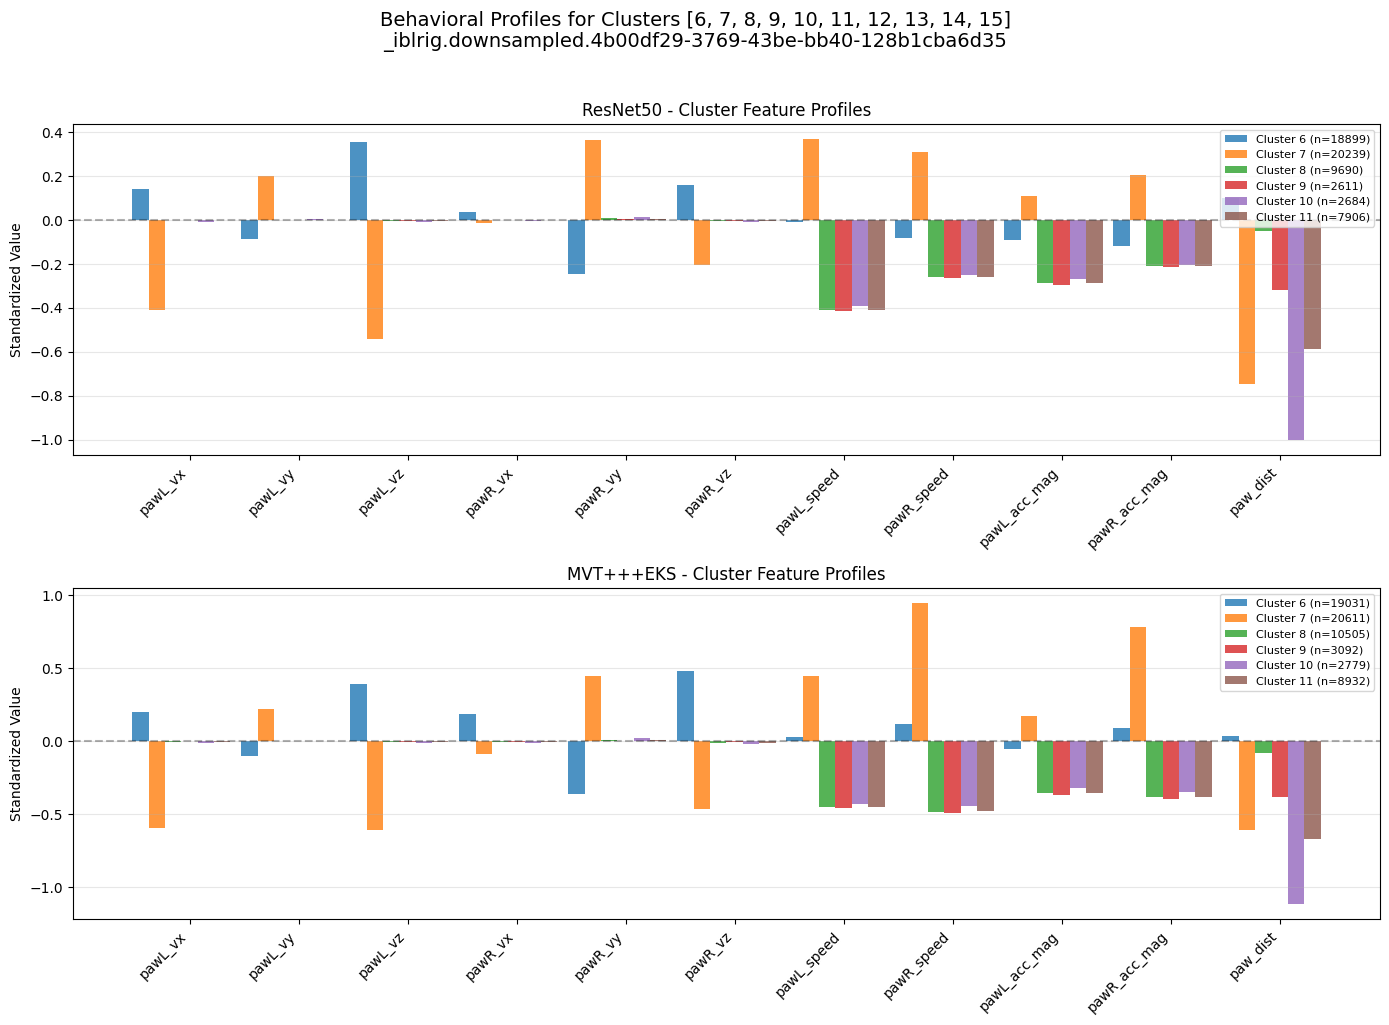

In [83]:
# ============================================================
# VISUAL COMPARISON: Cluster feature profiles (FIXED)
# ============================================================

fig, axes = plt.subplots(len(models_of_interest), 1, figsize=(14, 5*len(models_of_interest)))
if len(models_of_interest) == 1:
    axes = [axes]

for ax, model_name in zip(axes, models_of_interest):
    if model_name not in cluster_labels_by_model:
        continue
    
    labels = cluster_labels_by_model[model_name]
    
    # Get features
    feats = all_features[model_name]
    valid_mask = ~np.any(np.isnan(feats), axis=1)
    valid_indices = np.where(valid_mask)[0][:frames_per_model]
    feats_clean = feats[valid_indices]
    
    min_len = min(len(labels), len(feats_clean))
    labels = labels[:min_len]
    feats_clean = feats_clean[:min_len]
    
    # Get actual number of features
    n_features = feats_clean.shape[1]
    
    # Create feature names if they don't match
    if feature_names is None or len(feature_names) != n_features:
        actual_feature_names = [f'Feature_{i}' for i in range(n_features)]
        print(f"Warning: feature_names length mismatch. Using generic names. "
              f"(feature_names={len(feature_names) if feature_names else 'None'}, actual={n_features})")
    else:
        actual_feature_names = feature_names
    
    # Standardize for comparison
    feats_std = (feats_clean - feats_clean.mean(axis=0)) / (feats_clean.std(axis=0) + 1e-8)
    
    # Compute mean profile for each cluster
    cluster_profiles = []
    cluster_labels_plot = []
    
    for c in clusters_of_interest:
        mask = labels == c
        if mask.any():
            cluster_profiles.append(feats_std[mask].mean(axis=0))
            cluster_labels_plot.append(f"Cluster {c} (n={mask.sum()})")
    
    if cluster_profiles:
        profiles = np.array(cluster_profiles)
        
        x = np.arange(n_features)  # Use actual number of features
        width = 0.15
        colors = plt.cm.tab10(np.linspace(0, 1, len(clusters_of_interest)))
        
        for i, (profile, label) in enumerate(zip(profiles, cluster_labels_plot)):
            ax.bar(x + i*width, profile, width, label=label, color=colors[i], alpha=0.8)
        
        ax.set_xticks(x + width * len(cluster_profiles) / 2)
        ax.set_xticklabels(actual_feature_names, rotation=45, ha='right')
        ax.set_ylabel('Standardized Value')
        ax.set_title(f'{model_short_names[model_name]} - Cluster Feature Profiles')
        ax.legend(loc='upper right', fontsize=8)
        ax.axhline(y=0, color='k', linestyle='--', alpha=0.3)
        ax.grid(axis='y', alpha=0.3)

fig.suptitle(f'Behavioral Profiles for Clusters {clusters_of_interest}\n{target_session}', fontsize=14, y=1.02)
fig.tight_layout()
plt.show()

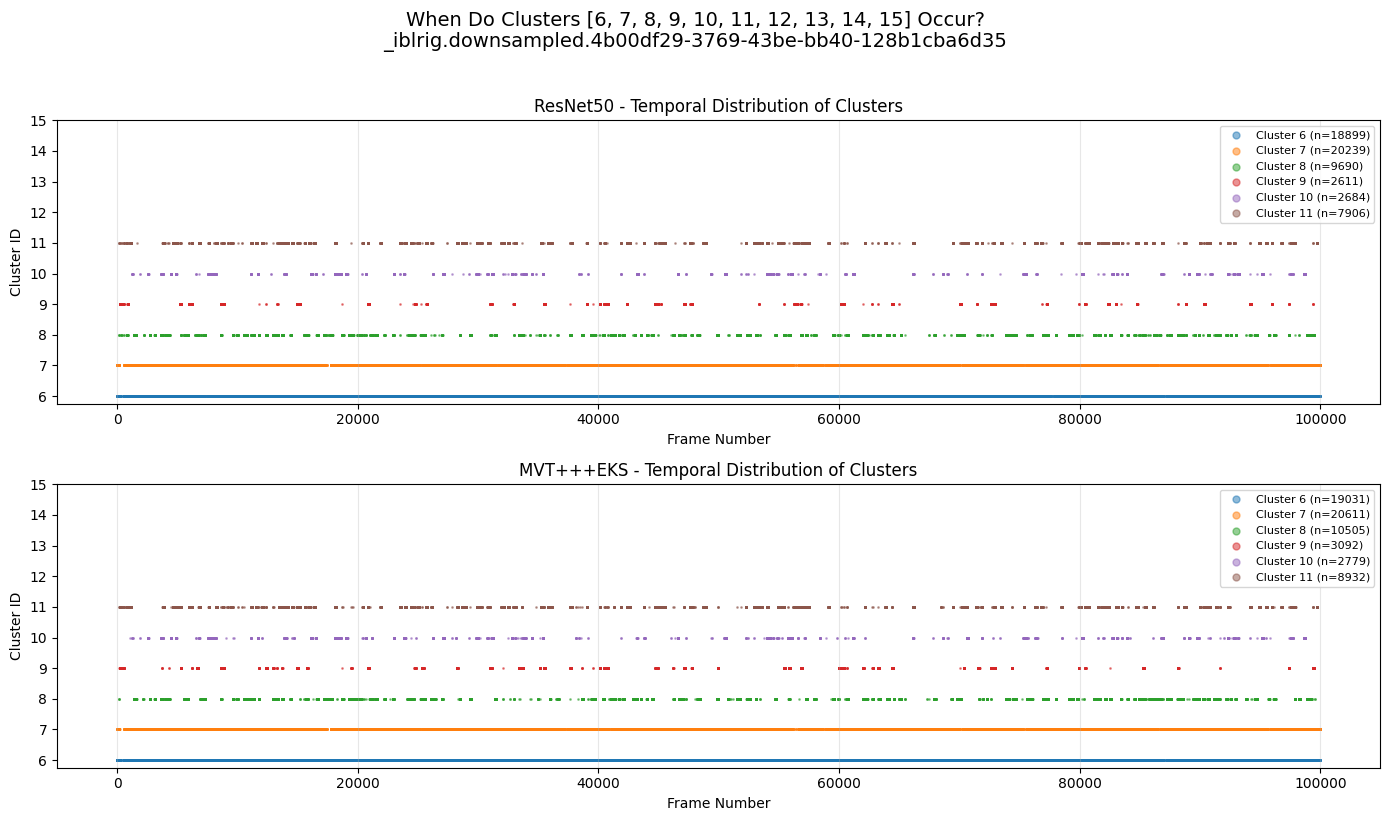

In [84]:
# ============================================================
# TEMPORAL ANALYSIS: When do clusters 6-10 occur in the video?
# ============================================================

fig, axes = plt.subplots(len(models_of_interest), 1, figsize=(14, 4*len(models_of_interest)))
if len(models_of_interest) == 1:
    axes = [axes]

for ax, model_name in zip(axes, models_of_interest):
    if model_name not in cluster_labels_by_model:
        continue
    
    labels = cluster_labels_by_model[model_name]
    
    # Map to original frame indices
    feats = all_features[model_name]
    valid_mask = ~np.any(np.isnan(feats), axis=1)
    valid_indices = np.where(valid_mask)[0][:frames_per_model]
    
    colors = plt.cm.tab10(np.linspace(0, 1, len(clusters_of_interest)))
    
    for i, c in enumerate(clusters_of_interest):
        cluster_mask = labels == c
        if not cluster_mask.any():
            continue
        
        original_frames = valid_indices[np.where(cluster_mask)[0]]
        
        # Plot as scatter (y = cluster ID for visibility)
        ax.scatter(original_frames, np.ones_like(original_frames) * c, 
                   s=1, alpha=0.5, color=colors[i], label=f'Cluster {c} (n={len(original_frames)})')
    
    ax.set_xlabel('Frame Number')
    ax.set_ylabel('Cluster ID')
    ax.set_title(f'{model_short_names[model_name]} - Temporal Distribution of Clusters')
    ax.legend(loc='upper right', fontsize=8, markerscale=5)
    ax.set_yticks(clusters_of_interest)
    ax.grid(axis='x', alpha=0.3)

fig.suptitle(f'When Do Clusters {clusters_of_interest} Occur?\n{target_session}', fontsize=14, y=1.02)
fig.tight_layout()
plt.show()

In [ ]:
# ============================================================
# HEATMAP: Cluster feature profiles (easier to read than bar plot)
# ============================================================

for model_name in models_of_interest:
    if model_name not in cluster_labels_by_model:
        continue
    
    labels = cluster_labels_by_model[model_name]
    
    # Get features
    feats = all_features[model_name]
    valid_mask = ~np.any(np.isnan(feats), axis=1)
    valid_indices = np.where(valid_mask)[0][:frames_per_model]
    feats_clean = feats[valid_indices]
    
    min_len = min(len(labels), len(feats_clean))
    labels = labels[:min_len]
    feats_clean = feats_clean[:min_len]
    
    n_features = feats_clean.shape[1]
    actual_feature_names = feature_names if (feature_names and len(feature_names) == n_features) else [f'F{i}' for i in range(n_features)]
    
    # Standardize
    feats_std = (feats_clean - feats_clean.mean(axis=0)) / (feats_clean.std(axis=0) + 1e-8)
    
    # Compute mean profile for each cluster
    cluster_means = []
    cluster_ids = []
    cluster_sizes = []
    
    for c in clusters_of_interest:
        mask = labels == c
        if mask.any():
            cluster_means.append(feats_std[mask].mean(axis=0))
            cluster_ids.append(c)
            cluster_sizes.append(mask.sum())
    
    if not cluster_means:
        continue
    
    cluster_means = np.array(cluster_means)
    
    # Create heatmap
    fig, ax = plt.subplots(figsize=(14, max(4, len(cluster_ids)*0.8)))
    
    im = ax.imshow(cluster_means, aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)
    
    # Labels
    ax.set_yticks(range(len(cluster_ids)))
    ax.set_yticklabels([f'Cluster {c}\n(n={cluster_sizes[i]})' for i, c in enumerate(cluster_ids)])
    ax.set_xticks(range(n_features))
    ax.set_xticklabels(actual_feature_names, rotation=45, ha='right')
    
    # Add value annotations
    for i in range(len(cluster_ids)):
        for j in range(n_features):
            val = cluster_means[i, j]
            color = 'white' if abs(val) > 1 else 'black'
            ax.text(j, i, f'{val:.1f}', ha='center', va='center', color=color, fontsize=8)
    
    plt.colorbar(im, ax=ax, label='Standardized Value\n(+ = high, - = low)')
    ax.set_title(f'{model_short_names[model_name]} - Cluster Feature Profiles\n{target_session}', fontsize=14)
    fig.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# RADAR PLOT: Cluster profiles as spider charts
# ============================================================

from math import pi

for model_name in models_of_interest:
    if model_name not in cluster_labels_by_model:
        continue
    
    labels = cluster_labels_by_model[model_name]
    
    # Get features
    feats = all_features[model_name]
    valid_mask = ~np.any(np.isnan(feats), axis=1)
    valid_indices = np.where(valid_mask)[0][:frames_per_model]
    feats_clean = feats[valid_indices]
    
    min_len = min(len(labels), len(feats_clean))
    labels = labels[:min_len]
    feats_clean = feats_clean[:min_len]
    
    n_features = feats_clean.shape[1]
    actual_feature_names = feature_names if (feature_names and len(feature_names) == n_features) else [f'F{i}' for i in range(n_features)]
    
    # Standardize
    feats_std = (feats_clean - feats_clean.mean(axis=0)) / (feats_clean.std(axis=0) + 1e-8)
    
    # Compute profiles
    cluster_profiles = {}
    for c in clusters_of_interest:
        mask = labels == c
        if mask.any():
            cluster_profiles[c] = {
                'mean': feats_std[mask].mean(axis=0),
                'n': mask.sum()
            }
    
    if not cluster_profiles:
        continue
    
    # Setup radar chart
    angles = [n / float(n_features) * 2 * pi for n in range(n_features)]
    angles += angles[:1]  # close the plot
    
    # Create subplots - one radar per cluster
    n_clusters_plot = len(cluster_profiles)
    cols = min(3, n_clusters_plot)
    rows = (n_clusters_plot + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 5*rows), subplot_kw=dict(polar=True))
    if n_clusters_plot == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    colors = plt.cm.tab10(np.linspace(0, 1, len(clusters_of_interest)))
    
    for idx, (c, data) in enumerate(cluster_profiles.items()):
        ax = axes[idx]
        
        values = data['mean'].tolist()
        values += values[:1]  # close the plot
        
        color_idx = clusters_of_interest.index(c) if c in clusters_of_interest else idx
        
        ax.plot(angles, values, 'o-', linewidth=2, color=colors[color_idx])
        ax.fill(angles, values, alpha=0.25, color=colors[color_idx])
        
        # Add feature labels
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels([fn[:10] for fn in actual_feature_names], size=8)
        
        ax.set_title(f'Cluster {c}\n(n={data["n"]})', size=12, fontweight='bold')
        ax.set_ylim(-2.5, 2.5)
    
    # Hide unused subplots
    for idx in range(len(cluster_profiles), len(axes)):
        axes[idx].set_visible(False)
    
    fig.suptitle(f'{model_short_names[model_name]} - Cluster Radar Profiles\n{target_session}', fontsize=14, y=1.02)
    fig.tight_layout()
    plt.show()

# '''''''''''''''''''''''''''''''''''''''''''''